### Laboratorium 4, część 1: Detekcja obiektów metodami klasycznymi

#### _Fabuła_
_Aby nauczyć głęboki model do segmentacji_ amodalnej _(tj. odpornej na okluzje między obiektami) konieczne jest skonstruowanie odpowiednio anotowanego zbioru uczącego.
Pozyskanie takich danych w drodze manualnej anotacji jest zbyt kosztowne, dlatego obieramy podejście oparte o generowanie danych syntetycznych.
Dane generowane będą na podstawie zbioru_ modalnego, _tj. zawierającego wyłącznie nieprzysłonięte obiekty.
Obiekty te należy najpierw wysegmentować ze specjalnie przygotowanych obrazów źródłowych, a następnie przeanalizować ich kształty -- ten właśnie krok będzie Twoim zadaniem._

#### Zadania

Twoim celem jest wykonanie detekcji i segmentacji _obiektów zainteresowania_ z podanych obrazów źródłowych.

W **pierwszej kolejności** przygotujesz potok przetwarzania przyjmujący obraz kolorowy w przestrzeni BGR/RGB a zwracający kolekcję obiektów opisanych (1) prostokątem otaczającym (_bounding box_) - na potrzeby detekcji, oraz (2) maską binarną **lub** konturem (tj. zbiorem koordynat punktów brzegowych).
Potok przetwarzania powinien obejmować binaryzację obrazu kolorowego (znanymi Ci już metodami), detekcję komponentów spójności ([`cv2.findContours`](https://docs.opencv.org/4.x/d3/dc0/group__imgproc__shape.html#gadf1ad6a0b82947fa1fe3c3d497f260e0)), oraz analizę blobów binarnych (obiektów).
Wykryte obiekty należy przefiltrować tak, aby pozostawić wyłącznie _obiekty zainteresowania_, tj. pojedyncze larwy.
Należy więc usunąć:
* drobne obiekty niebędące larwami,
* instancje złączone,
* wszelkie inne zakłócenia.

Zaimplementuj również funkcję pozwalającą na zaprezentowanie wyników detekcji w formie rysowania prostokątów odpowiadających instancjom oraz segmentacji w formie zaznaczania pikseli należących do instancji (może być w jednej funkcji z opcją wyboru).

**Następnie** opracujesz moduł przetwarzania poszczególnych instancji na poziomie masek binarnych lub konturów.
Moduł ten ma przyjmować pojedynczą instancję i wyznaczać dla niej podstawowe informacje, takie jak:
* długość (skorzystaj z [`skimage.morphology.skeletonize`](https://scikit-image.org/docs/stable/api/skimage.morphology.html#skimage.morphology.skeletonize)) - relatywnie łatwa do _estymacji_, ale dość trudna do precyzyjnego _pomiaru_,
* grubość - może stanowić wyzwanie,
* klasyfikację kształtu (I-kształtne, S-kształtne, C-kształtne) -- potencjalnie trudne zadanie,
* ...

Nie musisz implementować ich wszystkich: na maksymalną ocenę wystarczą dwie miary zrobione _nieźle_ lub jedna opracowana _solidnie_.

#### Oczekiwane rezultaty
1. Zaprojektowanie potoku przetwarzania do detekcji i segmentacji - skonstruuj go najlepiej jako pojedynczą funkcję, ale pozostaw ślad z dokonywanych po drodze eksperymentów, tak aby możliwe było przeanalizowanie przebiegu operacji krok po kroku.
2. Zadbaj o możliwość przetworzenia tylko wybranego RoI z obrazu, aby można było przyjrzeć się "z bliska" wybranym rejonom (np. trudniejszym) -- rekomenduję zacząć pracę od wybrania mniejszego, wygodniejszego w przetwarzaniu rejonu.
3. Działanie modułu analizy zademonstruj na kilku wybranych przykładach, także umożliwiając podgląd operacji krok po kroku.
4. Debugging - jeśli na którymkolwiek etapie pojawią się problemy, których nie potrafisz rozwiązać, postaraj się przynajmniej przeanalizować, co je powoduje.

#### Literatura
1. [`cv2.findContours`](https://docs.opencv.org/4.x/d3/dc0/group__imgproc__shape.html#gadf1ad6a0b82947fa1fe3c3d497f260e0), [OpenCV Structural Analysis and Shape Descriptors](https://docs.opencv.org/4.x/d3/dc0/group__imgproc__shape.html), [OpenCV Drawing Functions](https://docs.opencv.org/4.x/d6/d6e/group__imgproc__draw.html)
2. Publikacja, której częścią był potok przetwarzania podobny do tego, który zaimplementujesz: https://ieeexplore.ieee.org/document/10924163

In [1]:
from collections import Counter
from typing import List

import cv2
import numpy as np
import matplotlib.pyplot as plt
import skimage.morphology as skm
from skimage.graph import MCP_Geometric, pixel_graph
from skimage.measure import find_contours
from skimage.segmentation import expand_labels
from scipy.ndimage import gaussian_filter1d, map_coordinates

In [2]:
# staraj się projektować potok przetwarzania na jednym obrazie, a następnie przetestować go na drugim
calib = cv2.imread('Lab4_dane/proc_20221213112112426_image0.jpg')
test = cv2.imread('Lab4_dane/proc_20221213112219030_image0.jpg')
assert calib is not None and test is not None, 'Nie wczytano obrazów - sprawdź ścieżkę'

# Pracuję tylko na dnie pudełka: stały prostokąt (wiersze, kolumny), opis niżej. Pełne obrazy zostają w *_full.
FLOOR = (slice(255, 2730), slice(132, 3970))   # dno pudełka (275:2710, 152:3950) poszerzone o 20 px z każdej strony
calib_full, test_full = calib, test
calib, test = calib_full[FLOOR].copy(), test_full[FLOOR].copy()

### Obszar roboczy: dno pudełka

Obraz tnę od razu po wczytaniu do dna pudełka, czyli stałego prostokąta `FLOOR`. Cały dalszy potok, łącznie z wyborem RoI, pracuje już tylko na tym wycinku. Kamera wisi na stałej wysokości, a pudełko stoi w tym samym miejscu: między `calib` a `test` przesuwa się o ok. 5 px. 

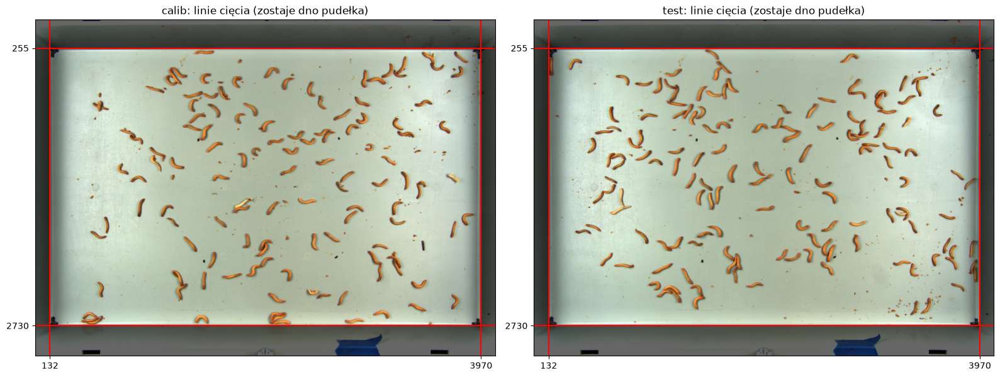

In [3]:
# Linie cięcia na obu obrazach wejściowych: zostaje dno pudełka (prostokąt FLOOR), odcięta część jest przyciemniona
ys, xs = FLOOR
f, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, img, name in zip(axes, (calib_full, test_full), ('calib', 'test')):
    vis = np.ascontiguousarray(img[..., ::-1])
    shown = cv2.convertScaleAbs(vis, alpha=0.4)
    shown[FLOOR] = vis[FLOOR]
    ax.imshow(shown)
    for y in (ys.start, ys.stop):
        ax.axhline(y, color='red', lw=1.5)
    for x in (xs.start, xs.stop):
        ax.axvline(x, color='red', lw=1.5)
    ax.set_xticks([xs.start, xs.stop])
    ax.set_yticks([ys.start, ys.stop])
    ax.set_title(f'{name}: linie cięcia (zostaje dno pudełka)')
plt.tight_layout()

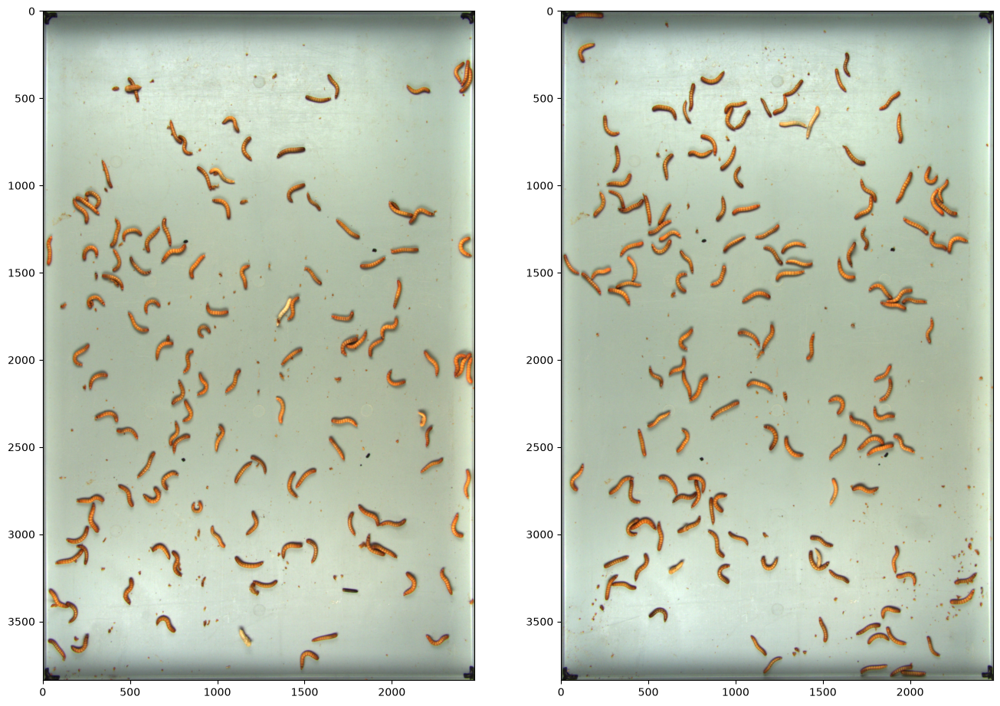

In [4]:
# Obrazy po cięciu: na nich pracuje cały potok (także RoI)
f, (a1, a2) = plt.subplots(1,2,figsize=(16,12))
a1.imshow(calib[...,::-1].transpose((1,0,2)))
a2.imshow(test[...,::-1].transpose((1,0,2)))

### Potok detekcji

Potok odwzorowuje segmentację z artykułu (sekcja III-B2c) i dodaje krok 6. `detect_objects` wywołuje kolejno funkcje sześciu kroków, a ich domyślne argumenty to parametry końcowe:

| krok | funkcja | artykuł | parametry końcowe |
|---|---|---|---|
| 1 | `rough_mask` | globalny próg na S | `S_THR` = 104 (Otsu na `calib`) |
| 2 | `find_candidates` | filtr pola, ROI | `min_area` = 1500 px, `margin` = 10 px |
| 3 | `segment_candidate` | lokalny próg z histogramu ROI | `K_GROW` = elipsa 7×7 |
| 4 | `segment_candidate` → `refine_edges` | adaptacyjna erozja (kanał B) | `refine_alpha` = 0.25 (`delta` = `alpha` × kontrast B w ROI), `refine_iters` = 4 |
| 5 | `blob_features`, `filter_candidates` | ręczne usunięcie zlepków | `max_extra` = 30 px; `k_len`, `k_width`, `k_area` = 1.35, 1.25, 1.6 |
| 6 | `split_candidates` → `split_candidate`, `clump_parts` | brak (rozszerzenie) | progi na S co `thr_step` = 10 do 200, `open_k` = 5, `grow` = 6 px, `min_part` = 500 px, `k_min` = 0.7, `min_cover` = 0.94, `branch_extra` = `clean_extra` = 3 px |

Krok 6 nie ma odpowiednika w artykule: rozdziela zlepki odrzucone w kroku 5 i usuwa wypustki (przyklejone okruchy) z larw przyjętych w kroku 5. `detect_objects(..., split=False)` zwraca wynik samych kroków 1–5.

Parametry dobierałem iteracyjnie, notatnik pokazuje stan końcowy. Każdy eksperyment zmienia jeden parametr, a pozostałe mają wartości końcowe. Do podglądu służą `show_candidate_steps` (kroki 1–5 dla jednego kandydata), `show_splits` (krok 6) i `display_objects` (prostokąty, maski, odrzuceni kandydaci z powodem).

**Kolory na wyniku końcowym** są takie same w każdej wizualizacji: zielony kontur = obiekt przyjęty, czerwony kontur = obiekt odrzucony. Szkielety, ścieżki, znaczniki i wypełnienia mają inne kolory.

#### Funkcje pomocnicze

In [5]:
def skeleton_longest_path(skel: np.ndarray):
    """Najdłuższa ścieżka w szkielecie: dwa przebiegi „najdalszego punktu” (dokładne dla drzew).
    Odległości po pikselach szkieletu liczy `skimage.graph.MCP_Geometric` (8-sąsiedztwo: krok prosty 1, ukośny √2).
    Zwraca (długość w px, punkty ścieżki jako tablicę (N, 2) [y, x])."""
    if not skel.any():
        return 0.0, np.empty((0, 2), int)
    cost = np.where(skel, 1.0, np.inf)  # poza szkieletem nie da się przejść

    def farthest(start):
        mcp = MCP_Geometric(cost, fully_connected=True)
        dist, _ = mcp.find_costs([start])
        dist[~np.isfinite(dist)] = -1
        end = np.unravel_index(np.argmax(dist), dist.shape)
        return end, float(dist[end]), mcp

    a, _, _ = farthest(tuple(np.argwhere(skel)[0]))  # od dowolnego punktu do najdalszego końca a
    b, length, mcp = farthest(a)                      # od a do najdalszego końca b: ścieżka a-b
    return length, np.array(mcp.traceback(b))


def skeleton_total_length(skel: np.ndarray) -> float:
    """Suma długości wszystkich gałęzi szkieletu. `skimage.graph.pixel_graph` łączy sąsiednie piksele szkieletu
    (8-sąsiedztwo) krawędziami o wadze równej odległości środków (1 lub √2). Macierz jest symetryczna,
    więc każda krawędź jest liczona dwa razy."""
    graph, _ = pixel_graph(skel, mask=skel, connectivity=2)
    return float(graph.sum() / 2)


def b_contrast(mask: np.ndarray, blue: np.ndarray) -> float:
    """Kontrast tło - obiekt na kanale B w ROI: mediana B tła minus średnia B obiektu.
    Tło = piksele ROI odległe od maski o co najmniej 4 px (bez pikseli mieszanych). Wpadają do niego też cień
    i fragmenty sąsiednich larw, ale mediana jest na nie odporna."""
    far = cv2.dilate(mask, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))) == 0
    return float(np.median(blue[far])) - float(blue[mask > 0].mean())


def refine_edges(mask: np.ndarray, blue: np.ndarray, alpha: float = 0.25, iters: int = 4) -> np.ndarray:
    """Adaptacyjna erozja brzegu (wg artykułu): piksel brzegowy jest usuwany, jeśli średnia kanału B
    w jego otoczeniu 3x3 jest jaśniejsza od średniej B całego obiektu o więcej niż delta.
    delta = alpha x kontrast tło - obiekt w tym ROI (b_contrast), liczona raz, na masce wejściowej.
    Dzięki temu erozja zdejmuje tę samą część przejścia larwa-tło niezależnie od jasności tła w danym miejscu pudełka.
    Larwy są żółte (mało niebieskiego), więc jasne B na brzegu = piksel mieszany z tłem / poświata."""
    m = mask.copy()
    kernel = np.ones((3, 3), np.uint8)
    blue_blur = cv2.blur(blue, (3, 3)).astype(np.float32)
    delta = alpha * b_contrast(mask, blue)
    for _ in range(iters):
        if not m.any():
            break
        mean_obj = blue_blur[m > 0].mean()
        edge = (m > 0) & (cv2.erode(m, kernel) == 0)
        to_remove = edge & (blue_blur > mean_obj + delta)
        if not to_remove.any():
            break
        m[to_remove] = 0
    return m

In [6]:
K_GROW = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))    # krok 3: poszerzenie konturu wstępnego o ok. 3 px
K_SMOOTH = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))  # krok 5: wygładzenie maski przed szkieletyzacją
FEAT_PAD = 10                                                    # margines tła wokół maski przy liczeniu szkieletu


def rough_mask(image: np.ndarray, s_thr: float):
    """Krok 1: binaryzacja wstępna = próg globalny na kanale S (HSV). Zwraca (S, maska wstępna)."""
    S = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)[..., 1]
    return S, (S > s_thr).astype(np.uint8)


def find_candidates(rough: np.ndarray, min_area: int = 1500, margin: int = 10):
    """Krok 2: komponenty spójności maski wstępnej (findContours), odrzucenie drobnych obiektów (< min_area)
    i prostokątne ROI z marginesem wokół każdego pozostałego.
    Zwraca (kandydaci: lista dict(contour, roi=(x0, y0, x1, y1)), kontury drobnych obiektów)."""
    h_img, w_img = rough.shape
    contours, _ = cv2.findContours(rough, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    seeds, small = [], []
    for c in contours:
        if cv2.contourArea(c) < min_area:
            small.append(c)
            continue
        x, y, w, h = cv2.boundingRect(c)
        roi = (max(x - margin, 0), max(y - margin, 0), min(x + w + margin, w_img), min(y + h + margin, h_img))
        seeds.append(dict(contour=c, roi=roi))
    return seeds, small


def segment_candidate(image: np.ndarray, S: np.ndarray, seed: dict, refine_alpha: float = 0.25,
                      refine_iters: int = 4, keep_steps: bool = False):
    """Kroki 3-4 dla jednego kandydata, w jego ROI:
      3. lokalny próg Otsu na S, ograniczony do konturu wstępnego poszerzonego o ok. 3 px (nie skleja z powrotem
         larw, które rozdzielił próg globalny),
      4. adaptacyjna erozja brzegu na kanale B (refine_edges, delta = refine_alpha x kontrast B tło - larwa w ROI),
    na koniec największa składowa pokrywająca się z konturem wstępnym (odcina fragmenty sąsiadów, które wpadły
    do prostokąta ROI), z wypełnionymi dziurami.
    Zwraca słownik instancji (bbox, mask, contour, area, ...) albo None, gdy nic nie zostało."""
    x0, y0, x1, y1 = seed['roi']
    seed_mask = np.zeros((y1 - y0, x1 - x0), np.uint8)
    cv2.drawContours(seed_mask, [seed['contour']], -1, 1, -1, offset=(-x0, -y0))

    # 3. lokalny próg Otsu na S, tylko w otoczeniu konturu wstępnego
    s_roi = S[y0:y1, x0:x1]
    local_thr, local = cv2.threshold(s_roi, 0, 1, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    local = local & cv2.dilate(seed_mask, K_GROW)

    # 4. adaptacyjna erozja brzegu na kanale B
    refined = refine_edges(local, image[y0:y1, x0:x1, 0], refine_alpha, refine_iters)

    # największa składowa pokrywająca się z konturem wstępnym, z wypełnionymi dziurami
    _, lab = cv2.connectedComponents(refined)
    ids = np.unique(lab[(seed_mask > 0) & (lab > 0)])
    if len(ids) == 0:
        return None
    best = max(ids, key=lambda i: np.count_nonzero(lab == i))
    cnts, _ = cv2.findContours((lab == best).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    cnt = max(cnts, key=cv2.contourArea)
    final = np.zeros_like(seed_mask)
    cv2.drawContours(final, [cnt], -1, 1, -1)

    bx, by, bw, bh = cv2.boundingRect(cnt)
    gx, gy = x0 + bx, y0 + by
    h_img, w_img = S.shape
    cand = dict(bbox=(gx, gy, bw, bh), mask=final[by:by + bh, bx:bx + bw].copy(), contour=cnt + np.array([x0, y0]),
                area=int(final.sum()), local_thr=float(local_thr), roi=seed['roi'],
                touches_border=gx == 0 or gy == 0 or gx + bw >= w_img or gy + bh >= h_img)
    if keep_steps:
        cand['steps'] = dict(S=s_roi, seed=seed_mask, local=local, refined=refined, final=final)
    return cand


def smooth_skeleton(mask: np.ndarray):
    """Maska wygładzona otwarciem K_SMOOTH i jej szkielet, obie w układzie maski.
    Maska jest przycięta do bbox, więc dotyka brzegu tablicy. Bez marginesu FEAT_PAD otwarcie nie zdejmuje pikseli
    leżących na brzegu tablicy i przy brzegu powstają fałszywe gałązki szkieletu."""
    m = cv2.morphologyEx(np.pad(mask, FEAT_PAD), cv2.MORPH_OPEN, K_SMOOTH)
    inner = (slice(FEAT_PAD, -FEAT_PAD),) * 2
    return m[inner], skm.skeletonize(m > 0)[inner]


def blob_features(mask: np.ndarray) -> dict:
    """Opis blobu na potrzeby filtracji (krok 5), liczony z samej maski instancji:
    szkielet wygładzonej maski -> najdłuższa ścieżka (długość) i nadmiar = suma bocznych gałęzi,
    przybliżona grubość = 2 x transformata odległości na środkowych 60% ścieżki.
    To przybliżone cechy do decyzji „jedna larwa czy nie”; dokładny pomiar robi analyze_instance."""
    _, skel = smooth_skeleton(mask)
    length, path = skeleton_longest_path(skel)
    extra = max(0.0, skeleton_total_length(skel) - length)
    dt = cv2.distanceTransform(np.pad(mask, FEAT_PAD), cv2.DIST_L2, 5)  # z marginesem: brzeg tablicy to tło
    mid = path[int(0.2 * len(path)):int(0.8 * len(path))] + FEAT_PAD
    width_est = 2 * float(np.median(dt[mid[:, 0], mid[:, 1]])) if len(mid) else 0.0
    return dict(length_px=float(length), skeleton_extra=float(extra), width_est=width_est, skeleton_path=path)


def filter_candidates(cands: List, min_area: int = 1500, max_extra: float = 30.0, k_len: float = 1.35,
                      k_width: float = 1.25, k_area: float = 1.6, ref_area: float = None, ref_len: float = None,
                      ref_width: float = None):
    """Krok 5: nadaje każdemu kandydatowi powód odrzucenia `reason` (None = przyjęty), w kolejności:
    maly, krawedz, szkielet (nadmiar >= max_extra), dlugosc (> k_len x mediana), grubosc (> k_width x mediana),
    pole (> k_area x mediana). Mediany liczone z „czystych” kandydatów (bez rozgałęzień, nie na krawędzi),
    chyba że podano `ref_*` (przydatne dla małych RoI). Nie zmienia wejścia: zwraca (nowa lista, mediany)."""
    clean = [c for c in cands if c['skeleton_extra'] < max_extra and not c['touches_border']]

    def median_of(given, key):
        return given if given is not None or not clean else float(np.median([c[key] for c in clean]))

    refs = dict(ref_area=median_of(ref_area, 'area'), ref_len=median_of(ref_len, 'length_px'),
                ref_width=median_of(ref_width, 'width_est'))
    out = []
    for c in cands:
        reason = None
        if c['area'] < min_area:
            reason = 'maly'
        elif c['touches_border']:
            reason = 'krawedz'
        elif c['skeleton_extra'] >= max_extra:
            reason = 'szkielet'
        elif refs['ref_len'] is not None and c['length_px'] > k_len * refs['ref_len']:
            reason = 'dlugosc'
        elif refs['ref_width'] is not None and c['width_est'] > k_width * refs['ref_width']:
            reason = 'grubosc'
        elif refs['ref_area'] is not None and c['area'] > k_area * refs['ref_area']:
            reason = 'pole'
        out.append({**c, 'reason': reason})
    return out, refs


CLUMP_REASONS = ('szkielet', 'dlugosc', 'grubosc')  # powody odrzucenia w kroku 5, które oznaczają zlepek


def clump_parts(S: np.ndarray, cand: dict, thr: float, open_k: int = 5, grow: int = 6, min_part: int = 500) -> List:
    """Krok 6 przy jednym progu: podział maski kandydata na części.
    Próg `thr` na S w obrębie maski -> otwarcie (przecina cienkie mostki między larwami albo larwą i okruchem) ->
    składowe >= min_part jako znaczniki -> odbudowa znaczników o `grow` px funkcją expand_labels (dylatacja bez
    sklejania: piksel trafia do najbliższego znacznika), tylko w granicach maski. Części są opisane jak kandydaci."""
    x, y, w, h = cand['bbox']
    clump = cand['mask'] > 0
    hi = ((S[y:y + h, x:x + w] > thr) & clump).astype(np.uint8)
    if open_k:
        hi = cv2.morphologyEx(hi, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (open_k, open_k)))
    n, lab, stats, _ = cv2.connectedComponentsWithStats(hi)
    keep = [i for i in range(1, n) if stats[i, cv2.CC_STAT_AREA] >= min_part]
    lab = expand_labels(np.where(np.isin(lab, keep), lab, 0), grow) * clump
    H, W = S.shape
    parts = []
    for i in keep:
        cnts, _ = cv2.findContours((lab == i).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cnt = max(cnts, key=cv2.contourArea)
        bx, by, bw, bh = cv2.boundingRect(cnt)
        mask = np.zeros((bh, bw), np.uint8)
        cv2.drawContours(mask, [cnt], -1, 1, -1, offset=(-bx, -by))
        gx, gy = x + bx, y + by
        parts.append(dict(bbox=(gx, gy, bw, bh), mask=mask, contour=cnt + np.array([x, y]), area=int(mask.sum()),
                          touches_border=gx == 0 or gy == 0 or gx + bw >= W or gy + bh >= H, **blob_features(mask)))
    return parts


def split_candidate(S: np.ndarray, cand: dict, filt: dict, thr_step: int = 10, thr_max: int = 200, k_min: float = 0.7,
                    min_cover: float = 0.94, clean_extra: float = 3.0, **part_kw):
    """Krok 6 dla jednego kandydata (zlepka albo larwy z wypustką): najniższy próg (co thr_step, od pierwszego
    powyżej progu lokalnego z kroku 3), przy którym podział maski jest poprawny:
      * każda część przechodzi filtr z kroku 5 (`filt`: parametry filtra i mediany całego obrazu),
      * każda część ma długość >= k_min x mediana (krótsza to najpewniej kawałek larwy przykrytej przez inną),
      * części razem pokrywają >= min_cover maski (inaczej przy tym progu zniknęła cała, np. blada, larwa
        albo wysoki próg zjadł brzeg larwy),
      * jeśli została jedna część, jej szkielet nie ma bocznej gałęzi (nadmiar < clean_extra): jedna część to ta
        sama larwa, więc jedyną korzyścią jest usunięcie wypustki, a ta musi zniknąć.
    Zwraca (próg, części) albo (None, [])."""
    for thr in range((int(cand['local_thr']) // thr_step + 1) * thr_step, thr_max + 1, thr_step):
        parts = clump_parts(S, cand, thr, **part_kw)
        if not parts:
            continue
        parts, _ = filter_candidates(parts, **filt)
        cover = sum(p['area'] for p in parts) / cand['area']
        if (cover >= min_cover and all(p['reason'] is None and p['length_px'] >= k_min * filt['ref_len'] for p in parts)
                and (len(parts) >= 2 or parts[0]['skeleton_extra'] < clean_extra)):
            return thr, parts
    return None, []


def split_candidates(S: np.ndarray, cands: List, filt: dict, branch_extra: float = 3.0, **kw) -> List:
    """Krok 6 dla wszystkich kandydatów po kroku 5: odrzuconych jako zlepki (CLUMP_REASONS) i przyjętych larw,
    których szkielet ma boczną gałąź (nadmiar >= branch_extra), czyli wypustkę. `kw` trafia do split_candidate.
    Zwraca listę udanych podziałów dict(cand, thr, parts, kind), kind = 'zlepek' albo 'wypustka'."""
    splits = []
    for c in cands:
        if c['reason'] in CLUMP_REASONS:
            kind = 'zlepek'
        elif c['reason'] is None and c['skeleton_extra'] >= branch_extra:
            kind = 'wypustka'
        else:
            continue
        thr, parts = split_candidate(S, c, filt, **kw)
        if parts:
            splits.append(dict(cand=c, thr=thr, parts=parts, kind=kind))
    return splits


def detect_objects(image: np.ndarray, s_thr: float, min_area: int = 1500, margin: int = 10,
                   refine_alpha: float = 0.25, refine_iters: int = 4, max_extra: float = 30.0,
                   k_len: float = 1.35, k_width: float = 1.25, k_area: float = 1.6,
                   ref_area: float = None, ref_len: float = None, ref_width: float = None,
                   split: bool = True, debug: bool = False, **split_kw):
    """Detekcja i segmentacja pojedynczych larw: kroki 1-6 potoku (kroki 1-5 wzorowane na artykule, sekcja III-B2c).
    Domyślne wartości argumentów to parametry końcowe; split=False wyłącza krok 6, `split_kw` trafia do
    split_candidates (np. min_cover, k_min, grow).

    Zwraca listę słowników: bbox (x, y, w, h), mask (maska przycięta do bbox), contour (współrzędne globalne),
    area, length_px, width_est, skeleton_extra, skeleton_path (y, x w układzie maski).
    Z debug=True zwraca (obiekty, info): info zawiera obrazy pośrednie, kandydatów z kroku 5 z powodem odrzucenia
    i obrazami pośrednimi kroków 3-4 (`steps`), podziały z kroku 6 (`splits`) i ostatecznie odrzuconych (`rejected`)."""
    S, rough = rough_mask(image, s_thr)                                                    # krok 1
    seeds, small = find_candidates(rough, min_area, margin)                                # krok 2
    cands = []
    for seed in seeds:
        c = segment_candidate(image, S, seed, refine_alpha, refine_iters, keep_steps=debug)  # kroki 3-4
        if c is not None:
            cands.append({**c, **blob_features(c['mask'])})
    cands, refs = filter_candidates(cands, min_area, max_extra, k_len, k_width, k_area,
                                    ref_area, ref_len, ref_width)                          # krok 5
    filt = dict(min_area=min_area, max_extra=max_extra, k_len=k_len, k_width=k_width, k_area=k_area, **refs)
    splits = split_candidates(S, cands, filt, **split_kw) if split else []               # krok 6
    replaced = {id(s['cand']): s['parts'] for s in splits}

    # kolejność kandydatów zostaje; podzielony kandydat jest zastąpiony swoimi częściami
    objects = [o for c in cands for o in replaced.get(id(c), [c] if c['reason'] is None else [])]
    if not debug:
        return objects
    info = dict(S=S, rough=rough, small=small, n_small=len(small), candidates=cands, splits=splits, filt=filt,
                rejected=[c for c in cands if c['reason'] is not None and id(c) not in replaced], **refs)
    return objects, info


In [7]:
ACCEPT_RGB, REJECT_RGB = (0, 200, 0), (255, 0, 0)  # kontur na wyniku końcowym: zielony = przyjęty, czerwony = odrzucony


def display_objects(image: np.ndarray, objects: List, mode: str = 'both', rejected: List = None,
                    ax=None, title: str = None, labels: bool = True):
    """Wizualizacja detekcji.
    Przyjęte obiekty mają zielony kontur, odrzuceni kandydaci (`rejected`) czerwony kontur i powód odrzucenia.
    mode: 'bbox' - prostokąty, 'mask' - piksele instancji, 'both' - jedno i drugie.
    Kolor pikseli instancji jest losowy, ale z odcieni od cyjanu do fioletu, żeby nie mylił się z decyzją."""
    vis = np.ascontiguousarray(image[..., ::-1])
    th = max(1, round(max(image.shape[:2]) / 800))
    rng = np.random.default_rng(0)
    if mode in ('mask', 'both'):
        overlay = vis.copy()
        for obj in objects:
            x, y, w, h = obj['bbox']
            hsv = np.uint8([[[rng.integers(90, 156), rng.integers(150, 256), 255]]])  # odcień 180-310°
            overlay[y:y + h, x:x + w][obj['mask'] > 0] = cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)[0, 0]
        vis = cv2.addWeighted(overlay, 0.55, vis, 0.45, 0)
    else:
        vis = vis.copy()
    for i, obj in enumerate(objects):
        x, y, w, h = obj['bbox']
        cv2.drawContours(vis, [obj['contour']], -1, ACCEPT_RGB, th)
        if mode in ('bbox', 'both'):
            cv2.rectangle(vis, (x, y), (x + w, y + h), ACCEPT_RGB, th)
        if labels:
            cv2.putText(vis, str(i), (x, max(y - 3 * th, 10)), cv2.FONT_HERSHEY_SIMPLEX, 0.5 * th, (0, 130, 0), th)
    for obj in rejected or []:
        cv2.drawContours(vis, [obj['contour']], -1, REJECT_RGB, th)
        if labels:
            x, y, _, _ = obj['bbox']
            cv2.putText(vis, obj['reason'], (x, max(y - 3 * th, 10)), cv2.FONT_HERSHEY_SIMPLEX,
                        0.5 * th, (220, 0, 0), th)
    if ax is None:
        _, ax = plt.subplots(figsize=(16, 12))
    ax.imshow(vis)
    ax.set_title(title or f'{len(objects)} obiektów' + (f', {len(rejected)} odrzuconych' if rejected else ''))
    ax.axis('off')
    return ax


def show_candidate_steps(image: np.ndarray, cand: dict):
    """Podgląd przetwarzania pojedynczego kandydata, kroki 1-5 (wymaga detect_objects(..., debug=True)).
    Ostatni panel: kontur w kolorze decyzji filtra, niebieska linia = najdłuższa ścieżka szkieletu."""
    x0, y0, x1, y1 = cand['roi']
    st = cand['steps']
    removed = np.zeros((*st['local'].shape, 3), np.uint8)
    removed[st['refined'] > 0] = (255, 255, 255)
    removed[(st['local'] > 0) & (st['refined'] == 0)] = (255, 0, 255)
    final = np.ascontiguousarray(image[y0:y1, x0:x1, ::-1]).copy()
    cnts, _ = cv2.findContours(st['final'], cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    cv2.drawContours(final, cnts, -1, REJECT_RGB if cand['reason'] else ACCEPT_RGB, 1)
    panels = [
        (image[y0:y1, x0:x1, ::-1], 'RGB (ROI kandydata)'),
        (st['S'], 'kanał S'),
        (st['seed'], '1-2. kontur wstępny'),
        (st['local'], f"3. lokalny Otsu (t={cand['local_thr']:.0f})"),
        (removed, '4. erozja B (magenta = usunięte)'),
        (final, f"5. wynik: {'odrzucony (' + cand['reason'] + ')' if cand['reason'] else 'przyjęty'}"),
    ]
    f, axes = plt.subplots(1, len(panels), figsize=(22, 4))
    for ax, (im, t) in zip(axes, panels):
        ax.imshow(im, cmap='gray')
        ax.set_title(t)
        ax.axis('off')
    path = cand['skeleton_path']
    if len(path):
        bx, by = cand['bbox'][0] - x0, cand['bbox'][1] - y0  # położenie maski instancji w ROI
        axes[-1].plot(path[:, 1] + bx, path[:, 0] + by, '-', color='blue', lw=1.5)
    f.suptitle(f"pole={cand['area']}  długość szkieletu={cand['length_px']:.0f}px  "
               f"nadmiar szkieletu={cand['skeleton_extra']:.1f}px")
    plt.tight_layout()

### Łatwy fragment (RoI)

Zaczynam od fragmentu z kilkunastoma larwami, w większości leżącymi osobno. Na nim pokazuję wynik każdego kroku. RoI jest wycinany z obrazu już przyciętego do dna pudełka.

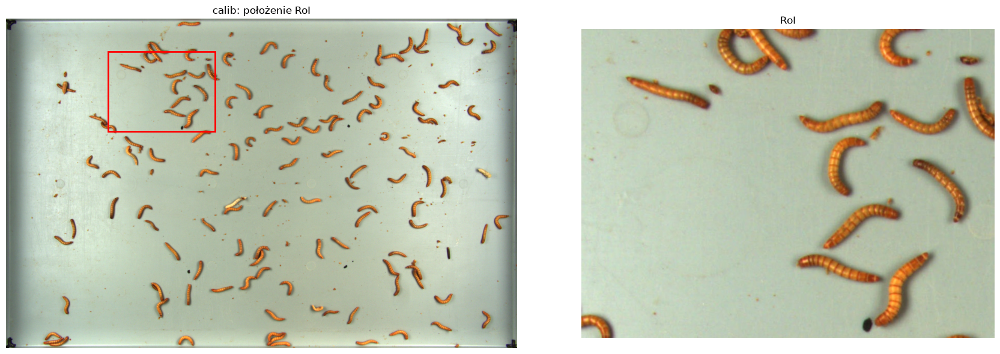

In [8]:
# Łatwy RoI: fragment calib z kilkunastoma larwami, w większości leżącymi osobno (współrzędne w układzie przyciętego obrazu)
roi = (slice(245, 845), slice(768, 1568))
roi_img = calib[roi]

f, (a1, a2) = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw=dict(width_ratios=(1.6, 1)))
a1.imshow(calib[..., ::-1])
a1.add_patch(plt.Rectangle((roi[1].start, roi[0].start), roi[1].stop - roi[1].start, roi[0].stop - roi[0].start,
                           fill=False, color='red', lw=2))
a1.set_title('calib: położenie RoI')
a2.imshow(roi_img[..., ::-1])
a2.set_title('RoI')
for ax in (a1, a2):
    ax.axis('off')
plt.tight_layout()

### Krok 1: binaryzacja wstępna, próg globalny na S (`rough_mask`)

**Binaryzacja wstępna** daje maskę wstępną: przybliżenie, które ma tylko wskazać, gdzie leżą obiekty (kandydaci i ich ROI w kroku 2). Jest szersza niż larwy, bo łapie poświatę, i bywa, że skleja sąsiadów. Ostateczny kształt każdej maski ustalają dopiero lokalny próg (krok 3) i erozja brzegu (krok 4).

Kanały dobieram za artykułem (sekcja III-B2c). Autorzy piszą, że larwy najwyraźniej oddzielają się od tła w **kanale S (nasycenie) modelu HSV** oraz w **kanale B modelu BGR**, i dlatego segmentują w tych dwóch kanałach:
* **S** służy do binaryzacji: najpierw próg globalny (ten krok), potem lokalny w każdym ROI (krok 3).
* **B** służy do doprecyzowania brzegów (adaptacyjna erozja, krok 4).

**Próg globalny na S.** W artykule dobrano go eksperymentalnie. Ja liczę go raz, metodą Otsu na obrazie kalibracyjnym (`S_THR`), i tej samej wartości używam dla RoI i obrazu testowego.

S_THR = 104; powyżej progu: calib 4.7%, test 5.1% pikseli


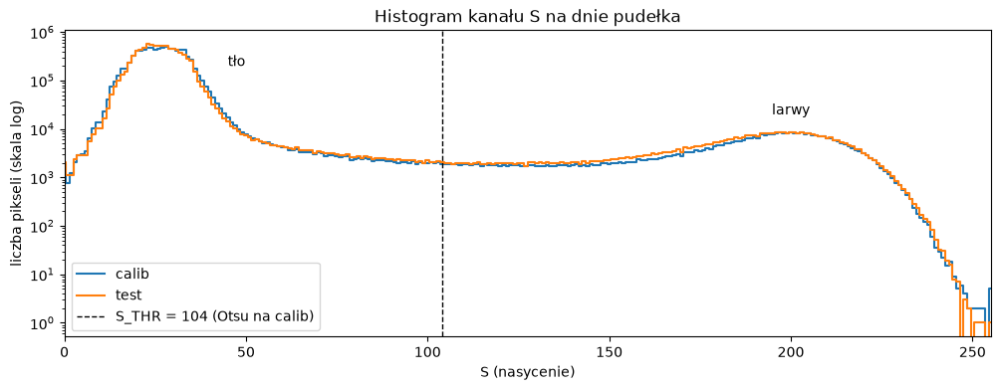

In [9]:
# Próg globalny na S: Otsu liczony raz, na obrazie kalibracyjnym. Ta sama wartość idzie do RoI i obrazu testowego.
S_calib = cv2.cvtColor(calib, cv2.COLOR_BGR2HSV)[..., 1]
S_test = cv2.cvtColor(test, cv2.COLOR_BGR2HSV)[..., 1]
S_THR, _ = cv2.threshold(S_calib, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print(f'S_THR = {S_THR:.0f}; powyżej progu: calib {(S_calib > S_THR).mean():.1%}, test {(S_test > S_THR).mean():.1%} pikseli')

# Histogram S na dnie pudełka; skala log, bo tło to ok. 95% pikseli
f, ax = plt.subplots(figsize=(12, 4))
for S, name in ((S_calib, 'calib'), (S_test, 'test')):
    ax.step(np.arange(256), np.bincount(S.ravel(), minlength=256), where='mid', lw=1.5, label=name)
ax.axvline(S_THR, color='k', ls='--', lw=1, label=f'S_THR = {S_THR:.0f} (Otsu na calib)')
ax.text(45, 2e5, 'tło', ha='left')
ax.text(200, 2e4, 'larwy', ha='center')
ax.set(yscale='log', xlim=(0, 255), xlabel='S (nasycenie)', ylabel='liczba pikseli (skala log)',
       title='Histogram kanału S na dnie pudełka')
ax.legend()

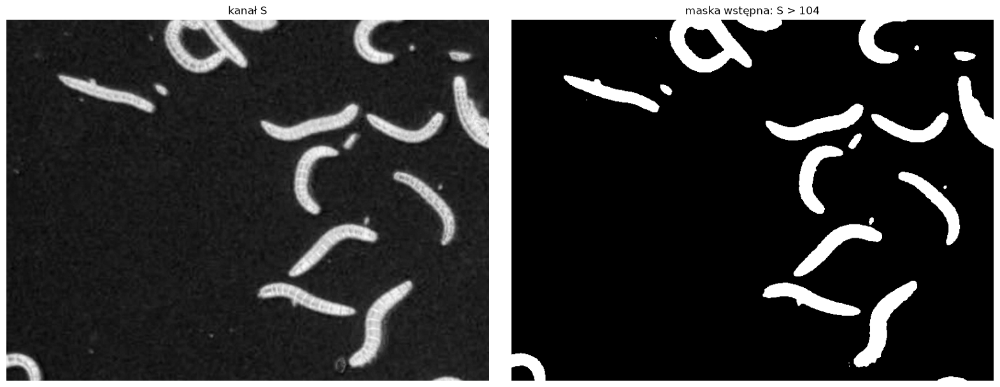

In [10]:
# Krok 1 na RoI: kanał S i maska wstępna
S_roi, rough_roi = rough_mask(roi_img, S_THR)
f, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].imshow(S_roi, cmap='gray')
axes[0].set_title('kanał S')
axes[1].imshow(rough_roi, cmap='gray')
axes[1].set_title(f'maska wstępna: S > {S_THR:.0f}')
for ax in axes:
    ax.axis('off')
plt.tight_layout()

#### Eksperyment: próg globalny a maska wstępna

Sprawdzam, co próg globalny robi z samą maską wstępną, czyli z wynikiem tego kroku. Liczę tylko kroki 1–2 dla progów 60–160 i śledzę:
* liczbę drobnych obiektów (< `min_area`), czyli szum, który krok 2 musi odrzucić,
* liczbę kandydatów o polu ponad 2× typowa larwa, czyli zlepków już w masce wstępnej,
* medianę pola kandydata, czyli ile poświaty wokół larw wchodzi do maski.

Pod wykresami: maska wstępna przy kilku progach na dwóch trudnych fragmentach `test`.

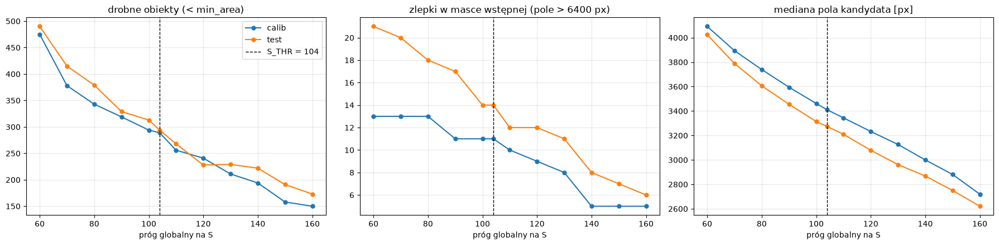

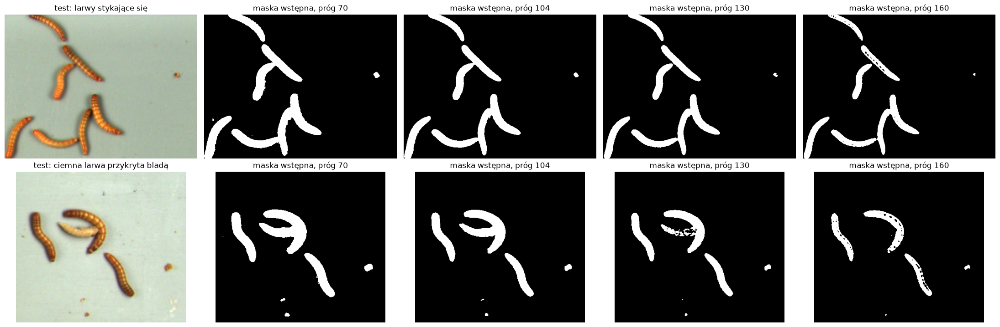

In [11]:
# Eksperyment (krok 1): jak próg globalny zmienia maskę wstępną. Liczone są tylko kroki 1-2, więc to szybkie.
CLUMP_AREA = 2 * 3200  # ok. 2 x mediana pola larwy po segmentacji: większy kandydat to prawie na pewno zlepek
thr_grid = sorted({60, 70, 80, 90, 100, S_THR, 110, 120, 130, 140, 150, 160})
f, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for name, img in (('calib', calib), ('test', test)):
    stats = []
    for t in thr_grid:
        seeds, small = find_candidates(rough_mask(img, t)[1])
        areas = [cv2.contourArea(s['contour']) for s in seeds]
        stats.append((len(small), sum(a > CLUMP_AREA for a in areas), np.median(areas)))
    for ax, values in zip(axes, zip(*stats)):
        ax.plot(thr_grid, values, 'o-', lw=1.5, ms=5, label=name)
for ax, title in zip(axes, ('drobne obiekty (< min_area)', f'zlepki w masce wstępnej (pole > {CLUMP_AREA} px)',
                            'mediana pola kandydata [px]')):
    ax.axvline(S_THR, color='k', ls='--', lw=1, label=f'S_THR = {S_THR:.0f}')
    ax.set(title=title, xlabel='próg globalny na S')
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()

# Maska wstępna przy kilku progach na dwóch trudnych fragmentach test
zooms = [('larwy stykające się', (slice(20, 470), slice(1320, 1920))),
         ('ciemna larwa przykryta bladą', (slice(1320, 1720), slice(2970, 3420)))]
shown_thr = (70, S_THR, 130, 160)
f, axes = plt.subplots(len(zooms), len(shown_thr) + 1, figsize=(4.4 * (len(shown_thr) + 1), 3.6 * len(zooms)))
for row, (label, zoom) in zip(axes, zooms):
    row[0].imshow(test[zoom][..., ::-1])
    row[0].set_title(f'test: {label}')
    for ax, t in zip(row[1:], shown_thr):
        ax.imshow(rough_mask(test[zoom], t)[1], cmap='gray')
        ax.set_title(f'maska wstępna, próg {t:.0f}')
    for ax in row:
        ax.axis('off')
plt.tight_layout()

**Wniosek (krok 1):**
* **Niski próg (≤ 80)** wpuszcza do maski poświatę wokół larw. Mediana pola kandydata rośnie z ok. 3400 px (przy `S_THR`) do ok. 4100 px (przy 60), drobnych obiektów jest ok. 1.7× więcej, a sąsiednie larwy łączą się przez poświatę w zlepki.
* **Wysoki próg** rozcina zlepki: przy 160 jest ich w masce wstępnej 5 zamiast 11 (`calib`) i 6 zamiast 14 (`test`). Kosztem jest to, że blade larwy rozpadają się na kawałki, a przy 160 maski nawet ciemnych larw mają dziury i przerwy.
* Kandydatów o polu ≥ `min_area` jest prawie tyle samo przy każdym progu (`calib` 102–105, `test` 111–115). Próg globalny nie decyduje więc o tym, *czy* larwa zostanie znaleziona. Decyduje o tym, jak dzielą się zlepki i ile tła wchodzi do maski. Kształt maski i tak ustala później lokalny próg (krok 3).
* Ile z tego zostaje po całym potoku, sprawdzam w sekcji „Wrażliwość wyniku na próg globalny”.

### Krok 2: komponenty spójności i filtr pola (`find_candidates`)

Kontury zewnętrzne maski wstępnej (`cv2.findContours`, `RETR_EXTERNAL`) wyznaczają komponenty spójności. Komponenty o polu `< min_area` to okruchy, odchody i fragmenty wylinek. Odrzucam je od razu, tak jak w artykule („mniejsze niż pojedynczy owad”). Wokół każdego pozostałego komponentu wyznaczam prostokątne ROI z marginesem `margin` = 10 px. W nim działają kroki 3–4.

(np.float64(-0.5), np.float64(799.5), np.float64(599.5), np.float64(-0.5))

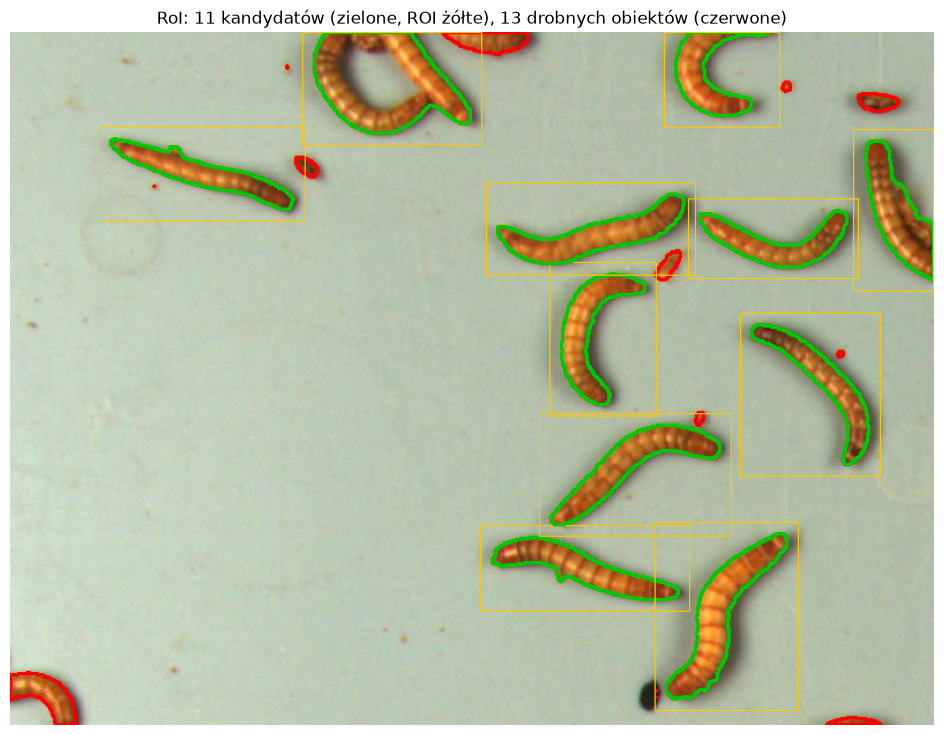

In [12]:
# Krok 2 na RoI: zielone = kandydaci (pole >= min_area) z prostokątem ROI, czerwone = drobne obiekty
seeds_roi, small_roi = find_candidates(rough_roi)
vis = np.ascontiguousarray(roi_img[..., ::-1]).copy()
cv2.drawContours(vis, small_roi, -1, (255, 0, 0), 2)
for s in seeds_roi:
    cv2.drawContours(vis, [s['contour']], -1, (0, 200, 0), 2)
    x0, y0, x1, y1 = s['roi']
    cv2.rectangle(vis, (x0, y0), (x1 - 1, y1 - 1), (255, 200, 0), 1)
f, ax = plt.subplots(figsize=(12, 9))
ax.imshow(vis)
ax.set_title(f'RoI: {len(seeds_roi)} kandydatów (zielone, ROI żółte), {len(small_roi)} drobnych obiektów (czerwone)')
ax.axis('off')

calib: komponentów o polu 1000-1700 px: 0, największy drobny: 956 px, najmniejszy kandydat: 1966 px
test: komponentów o polu 1000-1700 px: 0, największy drobny: 821 px, najmniejszy kandydat: 1729 px


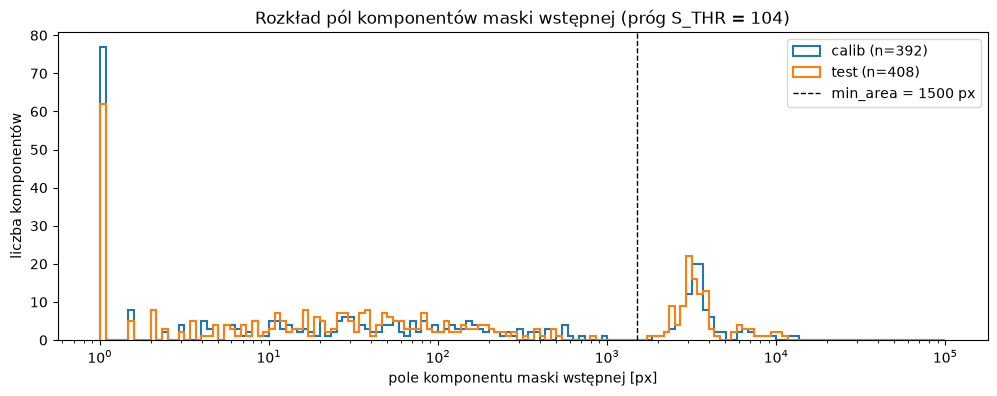

In [13]:
# Uzasadnienie min_area: rozkład pól wszystkich komponentów maski wstępnej (oś x w skali log, 30 przedziałów na dekadę)
bins = np.logspace(0, 5, 151)
f, ax = plt.subplots(figsize=(12, 4))
for name, img in (('calib', calib), ('test', test)):
    cnts, _ = cv2.findContours(rough_mask(img, S_THR)[1], cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    areas = np.array([cv2.contourArea(c) for c in cnts])
    ax.hist(np.maximum(areas, 1), bins, histtype='step', lw=1.5, label=f'{name} (n={len(areas)})')
    print(f'{name}: komponentów o polu 1000-1700 px: {np.sum((areas >= 1000) & (areas < 1700))}, '
          f'największy drobny: {areas[areas < 1500].max():.0f} px, najmniejszy kandydat: {areas[areas >= 1500].min():.0f} px')
ax.axvline(1500, color='k', ls='--', lw=1, label='min_area = 1500 px')
ax.set(xscale='log', xlabel='pole komponentu maski wstępnej [px]', ylabel='liczba komponentów',
       title=f'Rozkład pól komponentów maski wstępnej (próg S_THR = {S_THR:.0f})')
ax.legend()

**Wniosek (krok 2):** rozkład pól jest dwumodalny. Drobne obiekty mają najwyżej ok. 960 px, a najmniejszy kandydat ok. 1730 px. Między nimi nie ma na żadnym obrazie ani jednego komponentu. `min_area` = 1500 px leży więc w przerwie i jego dokładna wartość nie ma znaczenia. Pojedyncze larwy mają po segmentacji ok. 1800–4300 px. Na RoI czerwone są też fragmenty larw przeciętych brzegiem RoI, bo ich część wewnątrz RoI ma mniej niż `min_area`.

### Kroki 3–4: segmentacja w ROI (`segment_candidate`)

Dla każdego kandydata, w jego ROI:
* **krok 3:** lokalny próg Otsu na S. Histogram ROI zawiera głównie jedną larwę i tło wokół niej, więc Otsu wyznacza próg dopasowany do tej larwy. Wynik ograniczam do konturu wstępnego poszerzonego o ok. 3 px (`K_GROW`), żeby lokalny próg nie skleił z powrotem larw, które rozdzielił próg globalny. Fragmenty sąsiednich larw, które wpadły do prostokąta ROI, odpadają na końcu, bo zostaje tylko składowa nakładająca się na kontur wstępny.
* **krok 4:** adaptacyjna erozja brzegu na kanale B (`refine_edges`). Larwy są żółto-brązowe, czyli mają mało niebieskiego, więc piksel brzegowy z jasnym B to piksel mieszany z tłem albo poświata. Usuwam go, gdy średnia B w jego otoczeniu 3×3 przekracza średnią B obiektu o więcej niż `delta`. Artykuł nie podaje wartości `delta`. Nie przyjmuję stałej, tylko liczę ją dla każdego ROI: `delta` = `alpha` × kontrast, gdzie kontrast to mediana B tła w ROI (piksele co najmniej 4 px od maski) minus średnia B obiektu (`b_contrast`). Pudełko jest oświetlone nierówno, więc kontrast różni się między larwami prawie trzykrotnie (eksperyment niżej), a stała `delta` erodowałaby larwy na jasnym tle mocniej niż na ciemnym. Parametrem jest więc `alpha`: jaka część kontrastu larwa–tło wystarczy, żeby piksel brzegowy uznać za tło. Brzeg wyznaczam kwadratowym elementem strukturalnym 3×3 (piksel jest brzegowy, gdy którykolwiek z 8 sąsiadów należy do tła), więc jedna iteracja zdejmuje najwyżej 1 px, a `refine_iters` = 4 ogranicza erozję do 4 px.
* Na koniec zostaje największa składowa pokrywająca się z konturem wstępnym, z wypełnionymi dziurami.

Poniżej trzech kandydatów z RoI krok po kroku.

lokalne progi Otsu w RoI:

 [103, 107, 111, 112, 112, 112, 113, 113, 114, 114, 115] (globalny S_THR = 104)


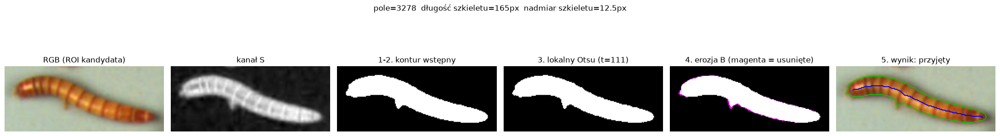

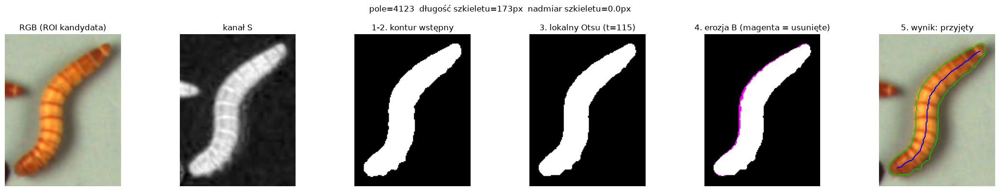

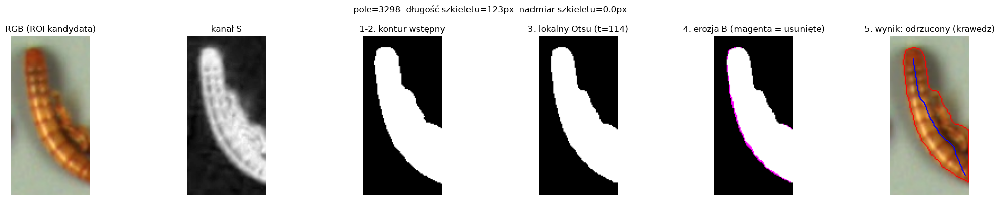

In [14]:
# Kroki 3-4 na RoI: detect_objects z debug=True zapisuje obrazy pośrednie każdego kandydata
objs_roi, dbg_roi = detect_objects(roi_img, S_THR, debug=True)
print('lokalne progi Otsu w RoI:', sorted(round(c['local_thr']) for c in dbg_roi['candidates']),
      f'(globalny S_THR = {S_THR:.0f})')
shown = [c for c in dbg_roi['candidates'] if c['reason'] is None][:2] + [c for c in dbg_roi['candidates'] if c['reason']][:1]
for cand in shown:
    show_candidate_steps(roi_img, cand)

#### Eksperyment: siła erozji brzegu (`alpha`)

Najpierw sprawdzam, czy stała `delta` ma sens: liczę kontrast B tło − larwa w ROI wszystkich kandydatów. Potem liczę erozję wprost funkcją `refine_edges` na masce z kroku 3 dwóch larw z RoI, dla trzech wartości `alpha` (mniejsza `alpha` = mocniejsza erozja). Półprzezroczysta zieleń to maska po erozji, a niebieska linia to kontur maski z kroku 3 (po binaryzacji lokalnym Otsu). Pas między konturem a zielenią to dokładnie piksele zdjęte przez erozję, a wszystko w zieleni zostaje w masce. Na koniec przebieg `alpha` od 0.05 do 0.5 na całym potoku dla obu obrazów: odsetek zdjętych pikseli (wynik kroku 4) oraz liczba przyjętych larw i mediana ich grubości (wynik końcowy).

calib: kontrast B tło - larwa w ROI kandydatów: min 64, mediana 121, max 169; stała delta=30 to alpha od 0.18 do 0.47


test: kontrast B tło - larwa w ROI kandydatów: min 62, mediana 126, max 170; stała delta=30 to alpha od 0.18 do 0.48


alpha | calib: larwy  zdjęto  grubość | test: larwy  zdjęto  grubość
 0.05 |          85   26.5%    15.98 |          98   25.2%    15.59
 0.10 |          90   19.0%    17.79 |         102   17.6%    17.58
 0.15 |          91   13.1%    19.58 |         102   11.9%    19.58
 0.20 |          92    8.7%    20.38 |         102    8.0%    20.38
 0.25 |          92    5.6%    21.19 |         103    5.1%    21.19
 0.30 |          91    3.4%    21.58 |         103    3.1%    21.58
 0.35 |          90    1.9%    21.97 |         103    1.6%    21.97
 0.40 |          90    1.0%    21.98 |         103    0.7%    21.97
 0.45 |          90    0.5%    22.00 |         103    0.2%    21.97
 0.50 |          90    0.3%    22.00 |         103    0.0%    21.97


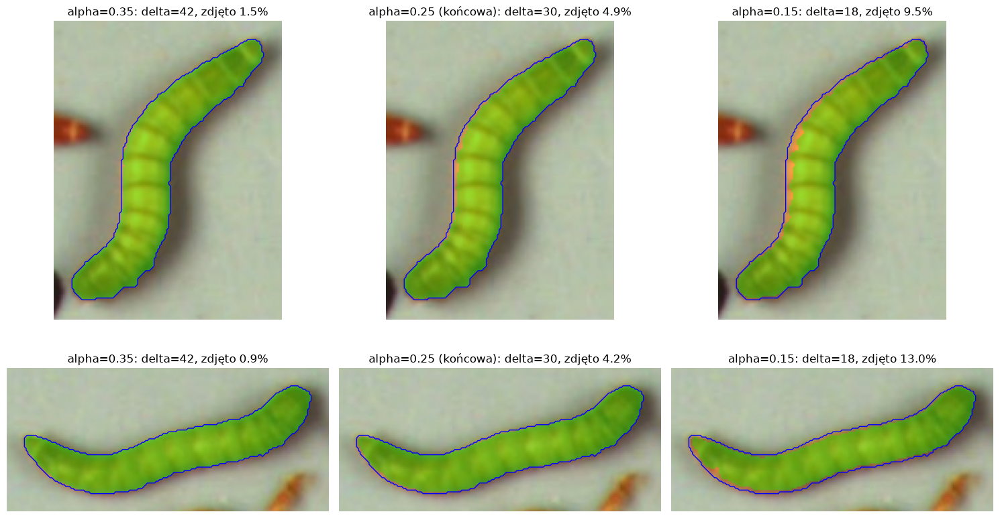

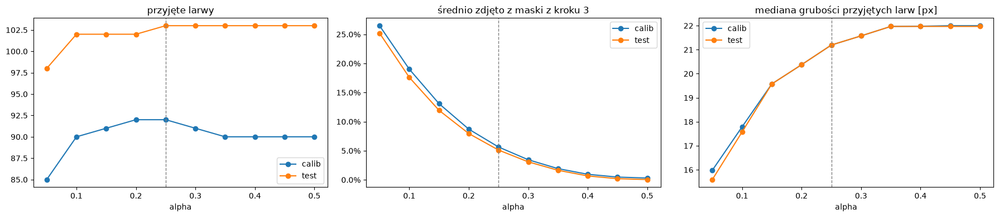

In [15]:
# Eksperyment (krok 4): alpha, czyli jaka część kontrastu B tło - larwa decyduje o usunięciu piksela brzegowego.
# Detekcja trwa ułamek sekundy, więc przebieg alpha liczę na całym potoku dla obu obrazów.
ALPHA_SHOW = [('alpha=0.35', 0.35), ('alpha=0.25 (końcowa)', 0.25), ('alpha=0.15', 0.15)]
ALPHA_GRID = np.round(np.arange(0.05, 0.51, 0.05), 2)


def show_erosion(ax, img_roi: np.ndarray, local: np.ndarray, eroded: np.ndarray):
    """Maska po erozji jako półprzezroczysta zieleń, kontur maski z kroku 3 na niebiesko.
    Pas między konturem a zielenią to piksele zdjęte przez erozję."""
    vis = img_roi[..., ::-1].astype(np.float32)
    vis[eroded > 0] = 0.6 * vis[eroded > 0] + 0.4 * np.array([0, 255, 0])
    ax.imshow(vis.astype(np.uint8))
    for cnt in find_contours(local, 0.5):  # kontur po granicy pikseli
        ax.plot(cnt[:, 1], cnt[:, 0], color='blue', lw=1)
    ax.axis('off')


def roi_of(image: np.ndarray, cand: dict):
    x0, y0, x1, y1 = cand['roi']
    return image[y0:y1, x0:x1]


# a) po co delta zależna od ROI: kontrast B tło - larwa w ROI kandydatów (maska z kroku 3, nie zależy od alpha)
for name, image in (('calib', calib), ('test', test)):
    _, dbg = detect_objects(image, S_THR, debug=True)
    con = np.array([b_contrast(c['steps']['local'], roi_of(image, c)[..., 0]) for c in dbg['candidates']])
    print(f'{name}: kontrast B tło - larwa w ROI kandydatów: min {con.min():.0f}, mediana {np.median(con):.0f}, '
          f'max {con.max():.0f}; stała delta=30 to alpha od {30 / con.max():.2f} do {30 / con.min():.2f}')

# b) dwie larwy z RoI dla trzech wartości alpha
examples = sorted((c for c in dbg_roi['candidates'] if c['reason'] is None), key=lambda c: -c['area'])[:2]
f, axes = plt.subplots(len(examples), len(ALPHA_SHOW), figsize=(5 * len(ALPHA_SHOW), 4.5 * len(examples)), squeeze=False)
for row, cand in zip(axes, examples):
    local, img_roi = cand['steps']['local'], roi_of(roi_img, cand)
    con = b_contrast(local, img_roi[..., 0])
    for ax, (name, a) in zip(row, ALPHA_SHOW):
        eroded = refine_edges(local, img_roi[..., 0], a)
        show_erosion(ax, img_roi, local, eroded)
        ax.set_title(f'{name}: delta={a * con:.0f}, zdjęto {1 - eroded.sum() / local.sum():.1%}')
plt.tight_layout()

# c) przebieg alpha na całym potoku: odsetek zdjętych pikseli, liczba larw, mediana grubości przyjętych larw
sweep = {}
for name, image in (('calib', calib), ('test', test)):
    for a in ALPHA_GRID:
        objs, dbg = detect_objects(image, S_THR, refine_alpha=a, debug=True)
        removed = np.mean([1 - c['steps']['refined'].sum() / c['steps']['local'].sum() for c in dbg['candidates']])
        sweep[name, a] = (len(objs), removed, np.median([o['width_est'] for o in objs]))
print('alpha | calib: larwy  zdjęto  grubość | test: larwy  zdjęto  grubość')
for a in ALPHA_GRID:
    print(f' {a:.2f} |' + ' |'.join(f'{sweep[n, a][0]:12d} {sweep[n, a][1]:7.1%} {sweep[n, a][2]:8.2f}'
                                   for n in ('calib', 'test')))
f, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, j, t in zip(axes, range(3), ['przyjęte larwy', 'średnio zdjęto z maski z kroku 3', 'mediana grubości przyjętych larw [px]']):
    for n in ('calib', 'test'):
        ax.plot(ALPHA_GRID, [sweep[n, a][j] for a in ALPHA_GRID], 'o-', label=n)
    ax.axvline(0.25, color='gray', ls='--', lw=1)
    ax.set_xlabel('alpha')
    ax.set_title(t)
    ax.legend()
axes[1].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.tight_layout()

#### Stała `delta` a `delta` dopasowana do ROI

Przy `alpha` = 0.25 erozja jest średnio tak silna jak przy stałej `delta` = 30, której używałem wcześniej: dla mediany kontrastu (ok. 120) daje właśnie `delta` = 30. Decyzja filtra zmienia się jednak dla dwóch kandydatów. Poniżej oba: po lewej stała `delta` = 30 (czyli `alpha` = 30 / kontrast), po prawej `alpha` = 0.25.

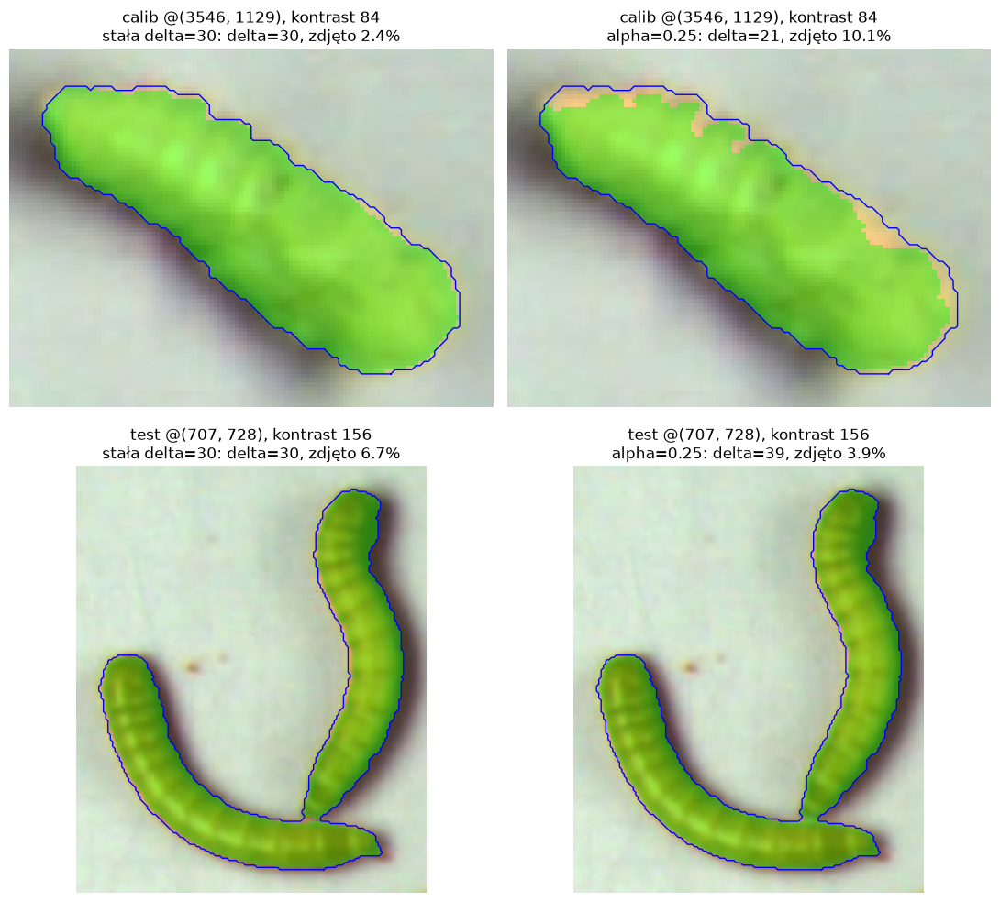

In [16]:
# Stała delta = 30 (czyli alpha = 30 / kontrast) a alpha = 0.25 na dwóch kandydatach, dla których zmienia się decyzja
# filtra. Punkt (x, y) w układzie przyciętego obrazu leży w ROI kandydata.
cases = [('calib', calib, (3596, 1162)), ('test', test, (768, 846))]
f, axes = plt.subplots(len(cases), 2, figsize=(11, 5 * len(cases)), squeeze=False)
for row, (name, image, (px, py)) in zip(axes, cases):
    _, dbg = detect_objects(image, S_THR, debug=True)
    cand = max((c for c in dbg['candidates'] if c['roi'][0] <= px < c['roi'][2] and c['roi'][1] <= py < c['roi'][3]),
               key=lambda c: c['area'])
    local, img_roi = cand['steps']['local'], roi_of(image, cand)
    con = b_contrast(local, img_roi[..., 0])
    for ax, (t, a) in zip(row, [('stała delta=30', 30 / con), ('alpha=0.25', 0.25)]):
        eroded = refine_edges(local, img_roi[..., 0], a)
        show_erosion(ax, img_roi, local, eroded)
        ax.set_title(f'{name} @{cand["bbox"][:2]}, kontrast {con:.0f}\n{t}: delta={a * con:.0f}, zdjęto {1 - eroded.sum() / local.sum():.1%}')
plt.tight_layout()

**Wniosek (kroki 3–4):**
* Lokalne progi Otsu w RoI wynoszą 103–115, czyli są równe progowi globalnemu albo trochę wyższe. Krok 3 w praktyce przycina więc maskę wstępną: zdejmuje resztki poświaty i rozcina połączenia dwóch larw przez poświatę (wtedy zostaje tylko największa część). Dlatego wynik końcowy prawie nie zależy od progu globalnego, dopóki ten jest niższy od progów lokalnych (sekcja o wrażliwości wyniku).
* **Kontrast B tło − larwa** w ROI kandydatów wynosi 64–169 na `calib` i 62–170 na `test` (mediana 121 / 126). Larwy mają podobne B, zmienia się głównie tło, bo pudełko jest oświetlone nierówno. Stała `delta` = 30 to więc od 0.18 do 0.48 kontrastu: na jasnym tle erozja zdejmuje piksele z niewielką domieszką tła, a na ciemnym dopiero takie, które są prawie w połowie tłem. Dlatego `delta` liczę z kontrastu w ROI.
* **`alpha` na RoI:** przy 0.35 erozja zdejmuje pojedyncze piksele (ok. 1–1.5% maski). Przy 0.25 zdejmuje wąski pas jasnych pikseli po stronie oświetlonej, tam gdzie brzeg larwy płynnie przechodzi w tło (ok. 4–5%). Przy 0.15 pas jest szeroki i wcina się w ciało larwy: między konturem a zielenią widać pomarańczowe piksele (ok. 10–13%). Od strony cienia kontur z kroku 3 leży już na brzegu ciała, bo cień ma niskie S, więc tam erozja nie ma czego zdejmować.
* **Przebieg `alpha` na całym potoku:** odsetek zdjętych pikseli maleje płynnie od ok. 26% przy 0.05 do zera przy 0.5, bez wyraźnego kolana, więc wartości nie da się odczytać z samej krzywej. Mediana grubości rośnie do ok. 22.0 px przy 0.4 i dalej się nie zmienia, a przy 0.25 wynosi 21.2 px. Liczba larw po całym potoku zmienia się mało: dla `alpha` od 0.10 do 0.50 jest to 90–92 na `calib` i 102–103 na `test`. Dopiero przy 0.05 (26% maski) spada wyraźnie (85 i 98).
* **Wybieram `alpha` = 0.25.** Dla mediany kontrastu daje `delta` ≈ 30, czyli wartość, którą wcześniej dobrałem wzrokowo jako stałą, i średnio zdejmuje tyle samo pikseli (5.6% / 5.1%). Różnica polega na tym, że erozja nie zależy już od jasności tła w danym miejscu pudełka.
* **Stała `delta` a `alpha` = 0.25** (dwa kandydaty wyżej):
  * `calib` @(3546, 1129): blada, krótka larwa, najpewniej tuż po wylince, z kontrastem 84. Stała `delta` = 30 zostawiała jasną poświatę i larwa odpadała przez `grubosc` (1.48×). Teraz `delta` = 21 zdejmuje poświatę, grubość spada do 1.19× i larwa przechodzi filtr. Maska ma jednak wcięcia w jasnych miejscach ciała, a decyzja jest niestabilna: przy innych progach globalnych larwa znów odpada (sekcja o wrażliwości).
  * `test` @(707, 728): dwie larwy stykające się końcem z bokiem, na jasnym tle (kontrast 156). Stała `delta` = 30 przecinała wąską szyjkę między nimi, a reguła największej składowej zostawiała tylko większą larwę. Przy `alpha` = 0.25 (`delta` = 39) szyjka zostaje, więc filtr odrzuca parę jako `szkielet`. Rozdzielenie było przypadkowym skutkiem silniejszej erozji na jasnym tle. Teraz parę rozdziela krok 6 i odzyskuje obie larwy.
* Erozja zmienia głównie brzeg maski, więc najbardziej odczuwa ją pomiar grubości. Sprawdzam to w części o analizie instancji (eksperyment „siła erozji brzegu a pomiar”).

### Krok 5: opis blobu i filtracja (`blob_features`, `filter_candidates`)

Z maski każdego kandydata `blob_features` liczy przybliżone cechy kształtu:
* szkielet wygładzonej maski i jego **najdłuższą ścieżkę**, wyznaczaną dwoma przebiegami „najdalszego punktu” (`skimage.graph.MCP_Geometric`),
* **nadmiar** = całkowita długość szkieletu (`skimage.graph.pixel_graph`) − najdłuższa ścieżka,
* przybliżoną grubość = 2 × transformata odległości na środku ścieżki.

Te cechy służą tylko do decyzji „jedna larwa czy nie”. Dokładny pomiar długości i grubości robi dopiero moduł analizy instancji.

`filter_candidates` odrzuca kandydata z pierwszym pasującym powodem:
* `krawedz`: obiekt dotyka brzegu obrazu (prostokąta `FLOOR`) lub RoI, więc może być ucięty albo wchodzić na ściankę;
* `szkielet`: nadmiar ≥ `max_extra` = 30 px, czyli skrzyżowane albo zlepione larwy;
* `dlugosc`: najdłuższa ścieżka > `k_len` × mediana, czyli larwy stykające się końcami (mają czysty szkielet, ale podwójną długość);
* `grubosc`: grubość > `k_width` × mediana, czyli larwy sklejone bokiem, leżące równolegle (szkielet też mają czysty);
* `pole`: pole > `k_area` × mediana, czyli zabezpieczenie na zlepki, których nie złapały poprzednie reguły.

Progi `dlugosc`, `grubosc` i `pole` są **względne**: odnoszą się do mediany „czystych” kandydatów (bez rozgałęzień, nie na krawędzi), więc dopasowują się do rozmiaru larw w danej partii. Uzasadnienie `max_extra` i progów względnych jest niżej.

RoI: 8 larw, odrzucono: {'krawedz': 3}
mediany z RoI: pole 3100 px, długość 165 px, grubość 20.5 px


<Axes: title={'center': 'RoI: 8 larw, 3 odrzuconych'}>

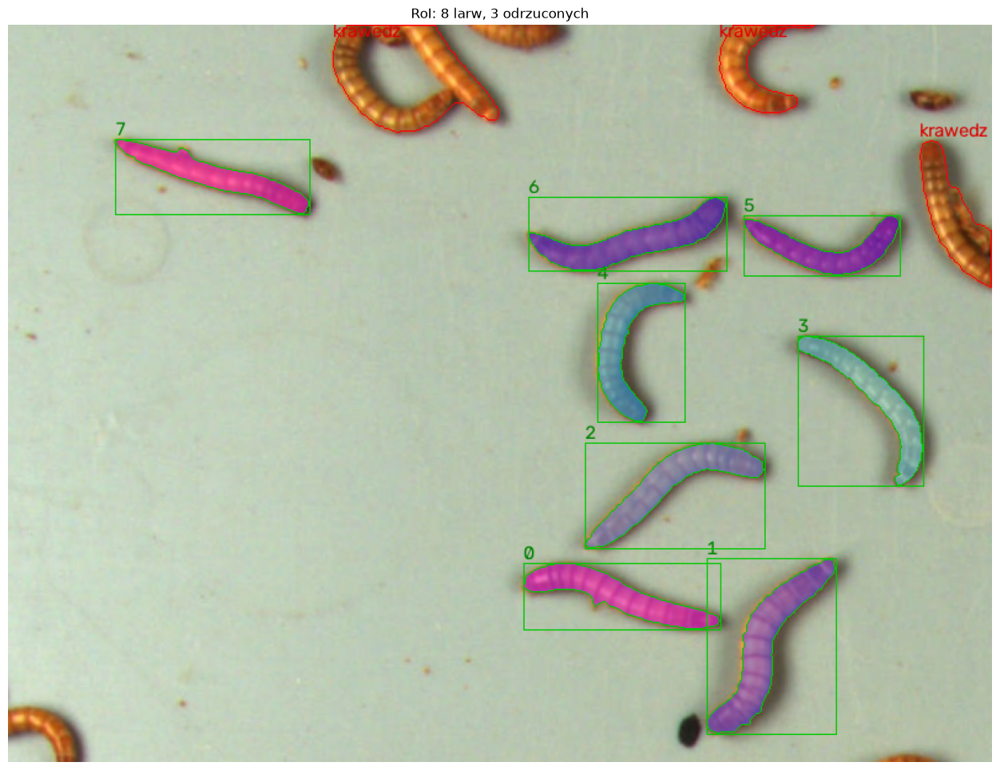

In [17]:
# Krok 5 na RoI: zielone = przyjęte, czerwone = odrzucone z powodem; mediany liczone z samego RoI
print(f"RoI: {len(objs_roi)} larw, odrzucono: {dict(Counter(c['reason'] for c in dbg_roi['rejected']))}")
print(f"mediany z RoI: pole {dbg_roi['ref_area']:.0f} px, długość {dbg_roi['ref_len']:.0f} px, grubość {dbg_roi['ref_width']:.1f} px")
display_objects(roi_img, objs_roi, mode='both', rejected=dbg_roi['rejected'],
                title=f'RoI: {len(objs_roi)} larw, {len(dbg_roi["rejected"])} odrzuconych')

Na RoI nie ma zlepków, więc filtr dobierałem na wszystkich kandydatach z `calib`. `test` służy do sprawdzenia, czy wnioski się przenoszą. Detekcję na obu obrazach (kroki 1–6) liczę tutaj, a wyniki pokazuję w sekcjach „Wynik”. Eksperymenty z filtrem korzystają z kandydatów po kroku 5. Krok 6 opisuję w osobnej sekcji po kroku 5.

In [18]:
# Pełna detekcja na obu obrazach (kroki 1-6, parametry końcowe). Eksperymenty z filtrem korzystają z kandydatów
# po kroku 5 (dbg['candidates']), a krok 6 opisuję w osobnej sekcji niżej.
objs_calib, dbg_calib = detect_objects(calib, S_THR, debug=True)
objs_test, dbg_test = detect_objects(test, S_THR, debug=True)
print(f'calib: {len(dbg_calib["candidates"])} kandydatów, test: {len(dbg_test["candidates"])} kandydatów')

calib: 103 kandydatów, test: 114 kandydatów


#### Eksperyment: jak powstał filtr zlepków (`max_extra`)

**Pierwsza wersja** uznawała obiekt za pojedynczą larwę, gdy jego szkielet ma dokładnie 2 końce i 0 rozgałęzień. Na całym obrazie ta reguła odrzucała jednak także **poprawne pojedyncze larwy**: drobny okruch przyklejony do brzegu albo nierówność konturu tworzą krótką boczną gałązkę szkieletu.

**Druga próba:** przycinanie krótkich gałązek. Nie pomogło, bo po usunięciu gałązki przy węźle zostawały 1–2-pikselowe resztki, które dalej liczyły się jako końce.

**Wersja końcowa:** zamiast liczyć węzły mierzę **nadmiar**, czyli łączną długość szkieletu poza najdłuższą ścieżką. Krótka wypustka daje mały nadmiar, a druga larwa duży.

Poniżej: rozkład nadmiaru (widać przerwę między pojedynczymi larwami a zlepkami) oraz larwy, które pierwsza reguła by niesłusznie odrzuciła, po dwa panele na larwę:
* **pierwsza reguła:** biały kontur to maska wygładzona otwarciem 7×7, z której powstaje szkielet (cyjan). Koniec (żółty) to piksel szkieletu z jednym sąsiadem w oknie 3×3. Rozgałęzienie (magenta) to skupisko stykających się pikseli z co najmniej trzema sąsiadami: jedno rozwidlenie daje zwykle 3–4 takie piksele, więc liczę skupiska, a nie piksele.
* **wynik końcowy:** maska dokładnie taka, jaka trafia do wyników, z zielonym konturem (przyjęta). Niebieska linia to najdłuższa ścieżka, a pomarańczowe piksele to gałęzie liczone do nadmiaru. Filtr z kroku 5 niczego z maski nie wycina: wypustka zostaje w masce, a otwarcie służy tylko do policzenia szkieletu. Część wypustek usuwa dopiero krok 6 (sekcja niżej). Wtedy panel pokazuje maskę po kroku 6, a biała przerywana linia to maska z kroku 5.

pierwsza reguła (2 końce, 0 rozgałęzień) odrzuciłaby 10 z 86 larw przyjętych przez wersję końcową


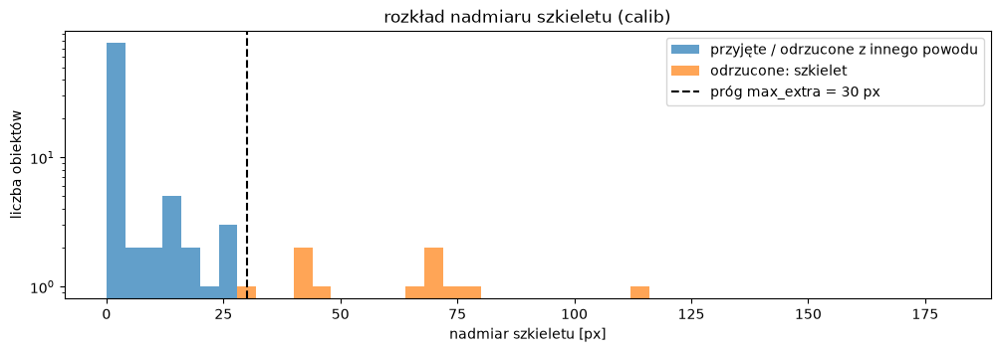

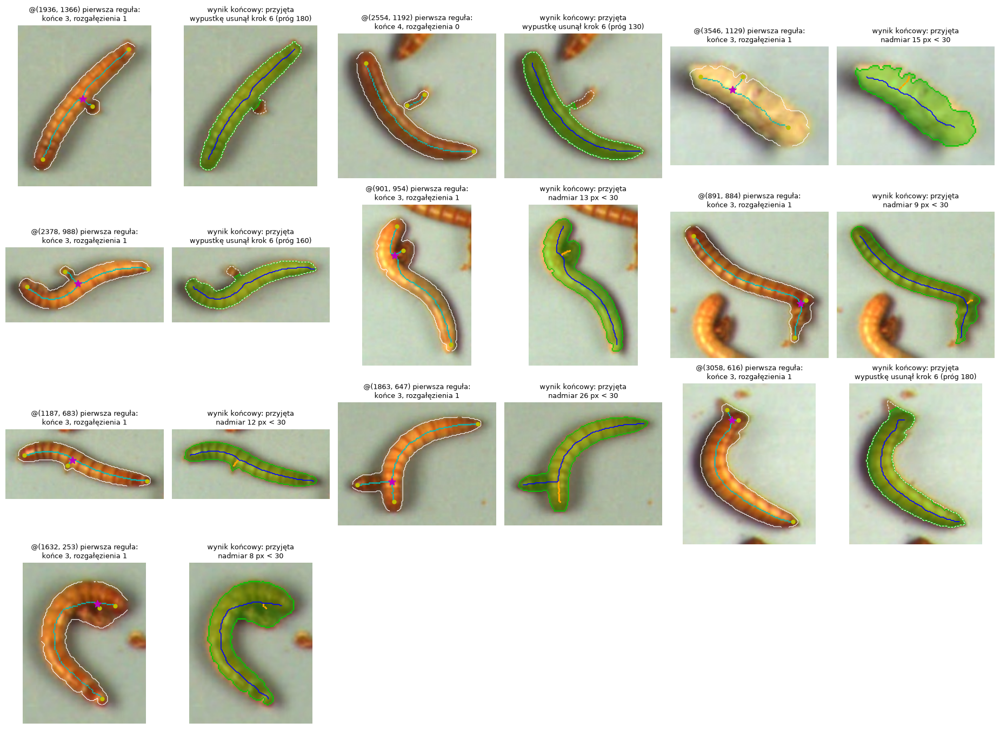

In [19]:
K3 = np.ones((3, 3), np.float32)


def skeleton_nodes(mask: np.ndarray):
    """Szkielet, z którego blob_features liczy nadmiar (smooth_skeleton), oraz jego końce i rozgałęzienia.
    Liczba sąsiadów piksela szkieletu = suma okna 3x3 (8-sąsiedztwo) minus on sam.
    Koniec = piksel z 1 sąsiadem. Rozgałęzienie = skupisko stykających się pikseli z >= 3 sąsiadami: jedno
    rozwidlenie szkieletu 8-spójnego daje zwykle 3-4 takie piksele, więc liczę skupiska, a nie piksele.
    Zwraca (szkielet, maska końców, środki rozgałęzień jako tablica (N, 2) [x, y])."""
    _, sk = smooth_skeleton(mask)
    sk = sk.astype(np.uint8)
    nbrs = cv2.filter2D(sk, -1, K3, borderType=cv2.BORDER_CONSTANT).astype(int) - 1
    _, _, _, centers = cv2.connectedComponentsWithStats(((nbrs >= 3) & (sk > 0)).astype(np.uint8), connectivity=8)
    return sk, (nbrs == 1) & (sk > 0), centers[1:]


def crop_around(image: np.ndarray, c: dict, pad: int):
    """Wycinek RGB wokół bbox kandydata i położenie (x0, y0) wycinka w obrazie."""
    x, y, w, h = c['bbox']
    x0, y0 = max(x - pad, 0), max(y - pad, 0)
    return np.ascontiguousarray(image[y0:y + h + pad, x0:x + w + pad, ::-1]).copy(), x0, y0


def show_gallery(image: np.ndarray, cands: List, title_fn, cols: int = 6, pad: int = 15):
    """Galeria wycinków z konturem (zielony = przyjęty, czerwony = odrzucony).
    image: obraz albo słownik {nazwa: obraz}; wtedy obraz wycinka wybiera pole c['img_name']."""
    if not cands:
        print('(brak obiektów)')
        return
    rows = int(np.ceil(len(cands) / cols))
    f, axes = plt.subplots(rows, cols, figsize=(3.2 * cols, 3.2 * rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis('off')
    for ax, c in zip(axes.ravel(), cands):
        crop, x0, y0 = crop_around(image[c['img_name']] if isinstance(image, dict) else image, c, pad)
        cv2.drawContours(crop, [c['contour'] - [x0, y0]], -1, REJECT_RGB if c.get('reason') else ACCEPT_RGB, 1)
        ax.imshow(crop)
        ax.set_title(title_fn(c), fontsize=9)
    plt.tight_layout()


def show_skeleton_vs_final(image: np.ndarray, cands: List, splits: List = (), cols: int = 3, pad: int = 15,
                           max_extra: float = 30.0):
    """Dwa panele na kandydata.
    Lewy, „pierwsza reguła”: maska wygładzona otwarciem (biały kontur), z której powstaje szkielet (cyjan),
    końce (żółte) i rozgałęzienia (magenta). Bez decyzji, więc bez konturu zielonego / czerwonego.
    Prawy, „wynik końcowy”: maska, która trafia do wyników (półprzezroczysta), kontur w kolorze decyzji,
    najdłuższa ścieżka (niebieska) i gałęzie liczone do nadmiaru (pomarańczowe). Jeśli kandydata zmienił krok 6
    (`splits` z detect_objects), panel pokazuje maskę po kroku 6, a biała przerywana linia to maska z kroku 5."""
    by_cand = {id(s['cand']): s for s in splits}
    rows = int(np.ceil(len(cands) / cols))
    f, axes = plt.subplots(rows, 2 * cols, figsize=(3.1 * 2 * cols, 3.4 * rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis('off')
    for k, c in enumerate(cands):
        a_rule, a_final = axes[k // cols, 2 * (k % cols)], axes[k // cols, 2 * (k % cols) + 1]
        crop, x0, y0 = crop_around(image, c, pad)
        ox, oy = c['bbox'][0] - x0, c['bbox'][1] - y0  # położenie maski w wycinku
        smooth, _ = smooth_skeleton(c['mask'])
        sk, ends, junctions = skeleton_nodes(c['mask'])

        a_rule.imshow(crop)
        for cnt in find_contours(smooth, 0.5):
            a_rule.plot(cnt[:, 1] + ox, cnt[:, 0] + oy, '-', color='white', lw=0.8)
        for m_, style, ms in ((sk, 'c.', 1.5), (ends, 'yo', 5)):
            yy, xx = np.nonzero(m_)
            a_rule.plot(xx + ox, yy + oy, style, ms=ms)
        a_rule.plot(junctions[:, 0] + ox, junctions[:, 1] + oy, 'm*', ms=10)
        a_rule.set_title(f"@({c['bbox'][0]}, {c['bbox'][1]}) pierwsza reguła:\n"
                         f"końce {ends.sum()}, rozgałęzienia {len(junctions)}", fontsize=9)

        split = by_cand.get(id(c))
        shown = split['parts'] if split else [c]
        for o in shown:  # wypełnienie i kontur w kolorze decyzji
            m = o['mask'] > 0
            bx, by = o['bbox'][0] - x0, o['bbox'][1] - y0
            verdict = ACCEPT_RGB if o['reason'] is None else REJECT_RGB
            region = crop[by:by + m.shape[0], bx:bx + m.shape[1]]
            region[m] = (0.65 * region[m] + 0.35 * np.array(verdict)).astype(np.uint8)
            cv2.drawContours(crop, [o['contour'] - [x0, y0]], -1, verdict, 1)
        a_final.imshow(crop)
        if split:
            cnt = c['contour'][:, 0, :] - [x0, y0]
            a_final.plot(np.r_[cnt[:, 0], cnt[0, 0]], np.r_[cnt[:, 1], cnt[0, 1]], '--', color='white', lw=0.8)
        for o in shown:  # najdłuższa ścieżka i gałęzie nadmiaru
            bx, by = o['bbox'][0] - x0, o['bbox'][1] - y0
            _, sk_o = smooth_skeleton(o['mask'])
            on_path = np.zeros(sk_o.shape, bool)
            on_path[o['skeleton_path'][:, 0], o['skeleton_path'][:, 1]] = True
            yy, xx = np.nonzero(sk_o & ~on_path)
            a_final.plot(xx + bx, yy + by, '.', color='orange', ms=3)
            a_final.plot(o['skeleton_path'][:, 1] + bx, o['skeleton_path'][:, 0] + by, '-', color='blue', lw=1.2)
        if split:
            title = f"wynik końcowy: przyjęta\nwypustkę usunął krok 6 (próg {split['thr']})"
        else:
            title = (f"wynik końcowy: {'przyjęta' if c['reason'] is None else 'odrzucona: ' + c['reason']}\n"
                     f"nadmiar {c['skeleton_extra']:.0f} px {'<' if c['skeleton_extra'] < max_extra else '≥'} {max_extra:.0f}")
        a_final.set_title(title, fontsize=9)
    plt.tight_layout()


def old_rule_ok(c) -> bool:
    _, ends, junctions = skeleton_nodes(c['mask'])
    return ends.sum() == 2 and len(junctions) == 0


cands = [c for c in dbg_calib['candidates'] if not c['touches_border']]
accepted = [c for c in cands if c['reason'] is None]
saved = [c for c in accepted if not old_rule_ok(c)]
print(f'pierwsza reguła (2 końce, 0 rozgałęzień) odrzuciłaby {len(saved)} z {len(accepted)} larw przyjętych przez wersję końcową')

f, ax = plt.subplots(figsize=(12, 3.5))
bins = np.arange(0, 181, 4)
ax.hist([c['skeleton_extra'] for c in cands if c['reason'] != 'szkielet'], bins, alpha=0.7,
        label='przyjęte / odrzucone z innego powodu')
ax.hist([c['skeleton_extra'] for c in cands if c['reason'] == 'szkielet'], bins, alpha=0.7, label='odrzucone: szkielet')
ax.axvline(30, color='k', ls='--', label='próg max_extra = 30 px')
ax.set_yscale('log'); ax.set_xlabel('nadmiar szkieletu [px]'); ax.set_ylabel('liczba obiektów'); ax.legend()
ax.set_title('rozkład nadmiaru szkieletu (calib)')

show_skeleton_vs_final(calib, saved, dbg_calib['splits'])

#### Uzasadnienie progów względnych (`k_len`, `k_width`, `k_area`)

Dla każdego kandydata, który przeszedł reguły `krawedz` i `szkielet`, liczę stosunek długości, grubości i pola do mediany jego obrazu. Próg względny ma sens, jeśli między pojedynczymi larwami a zlepkami jest przerwa i próg w niej leży. Kolor punktu oznacza ostateczną decyzję filtra. Pod wykresem są przypadki graniczne: najwyższe wartości wśród przyjętych i najniższe ponad progiem, żeby ocenić wzrokowo, co jest pojedynczą larwą.

Czego się spodziewać po budowie zlepka:
* dwie larwy stykające się końcami mają długość ≈ L₁ + L₂, czyli ok. 2× mediana; dla dwóch małych larw mniej, nawet ok. 1.2–1.4×;
* dwie larwy leżące równolegle mogą mieć w środku nawet 2× grubość, ale zwykle stykają się tylko fragmentem, więc mediana grubości na środku osi rośnie mniej;
* pole zlepka to ok. 2× mediana minus część wspólna.

długość  próg 1.35: przyjęte do 1.25 (95. percentyl 1.13); ponad progiem 10 kandydatów, od 1.47; reguła zadziałała jako pierwsza 10 razy
grubość  próg 1.25: przyjęte do 1.23 (95. percentyl 1.13); ponad progiem 4 kandydatów, od 1.26; reguła zadziałała jako pierwsza 3 razy
pole     próg 1.6: przyjęte do 1.34 (95. percentyl 1.20); ponad progiem 9 kandydatów, od 1.79; reguła zadziałała jako pierwsza 0 razy


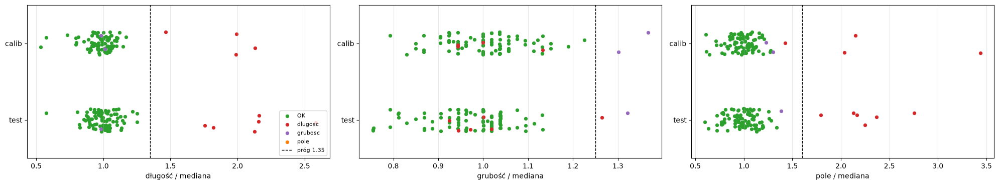

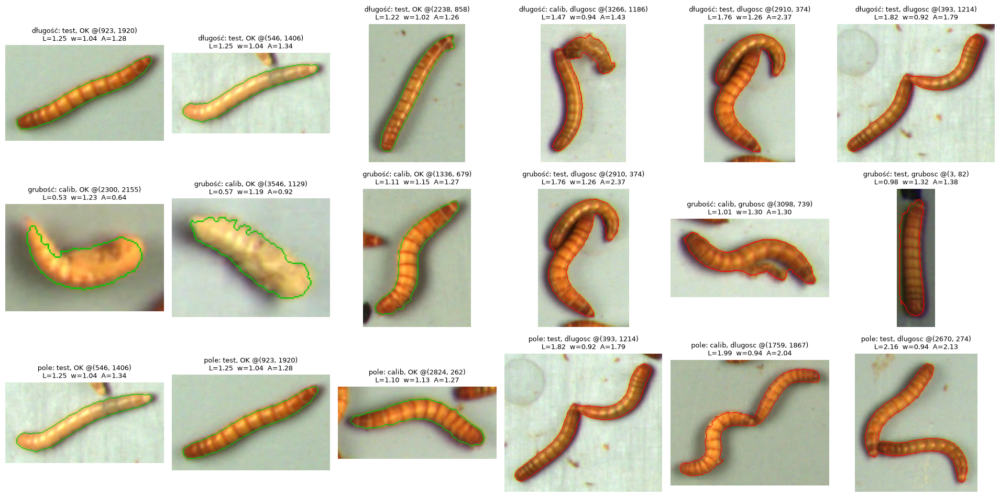

In [20]:
# Stosunek do mediany dla kandydatów, o których decydują progi względne (po regułach krawedz i szkielet)
criteria = [('length_px', 'ref_len', 1.35, 'długość'), ('width_est', 'ref_width', 1.25, 'grubość'),
            ('area', 'ref_area', 1.6, 'pole')]
pool = [dict(c, img_name=name, ratios={key: c[key] / dbg[ref] for key, ref, _, _ in criteria})
        for name, dbg in (('calib', dbg_calib), ('test', dbg_test))
        for c in dbg['candidates'] if c['reason'] not in ('maly', 'krawedz', 'szkielet')]
REASON_COLORS = {'OK': 'tab:green', 'dlugosc': 'tab:red', 'grubosc': 'tab:purple', 'pole': 'tab:orange'}

rng = np.random.default_rng(1)
f, axes = plt.subplots(1, 3, figsize=(20, 3.8))
for ax, (key, _, k, label) in zip(axes, criteria):
    for row, name in enumerate(('test', 'calib')):
        for reason, col in REASON_COLORS.items():
            vals = [c['ratios'][key] for c in pool if c['img_name'] == name and (c['reason'] or 'OK') == reason]
            ax.scatter(vals, row + rng.uniform(-0.15, 0.15, len(vals)), s=18, color=col,
                       label=reason if row == 1 else None)
    ax.axvline(k, color='k', ls='--', lw=1, label=f'próg {k}')
    ax.set(yticks=[0, 1], yticklabels=['test', 'calib'], xlabel=f'{label} / mediana', ylim=(-0.5, 1.5))
    ax.grid(alpha=0.3, axis='x')
axes[0].legend(fontsize=8, loc='lower right')
plt.tight_layout()

for key, _, k, label in criteria:
    ok = [c['ratios'][key] for c in pool if c['reason'] is None]
    above = [c['ratios'][key] for c in pool if c['ratios'][key] > k]
    fired = sum(c['reason'] == {'length_px': 'dlugosc', 'width_est': 'grubosc', 'area': 'pole'}[key] for c in pool)
    print(f'{label:8s} próg {k}: przyjęte do {max(ok):.2f} (95. percentyl {np.percentile(ok, 95):.2f}); '
          f'ponad progiem {len(above)} kandydatów, od {min(above):.2f}; reguła zadziałała jako pierwsza {fired} razy')

# Przypadki graniczne: po 3 najwyższe wśród przyjętych i 3 najniższe ponad progiem, osobno dla każdej cechy
cases = []
for key, _, k, label in criteria:
    ok = sorted((c for c in pool if c['reason'] is None), key=lambda c: -c['ratios'][key])[:3]
    above = sorted((c for c in pool if c['ratios'][key] > k), key=lambda c: c['ratios'][key])[:3]
    cases += [dict(c, crit=label) for c in ok + above]
show_gallery({'calib': calib, 'test': test}, cases, cols=6,
             title_fn=lambda c: (f"{c['crit']}: {c['img_name']}, {c['reason'] or 'OK'} @({c['bbox'][0]}, {c['bbox'][1]})\n"
                                 f"L={c['ratios']['length_px']:.2f}  w={c['ratios']['width_est']:.2f}  "
                                 f"A={c['ratios']['area']:.2f}"))

#### Próg długości: dlaczego 1.35, a nie 1.5

Pierwotnie `k_len` wynosiło 1.5. Wykres pokazuje, ile larw przyjmuje filtr przy różnych wartościach `k_len`, przy pozostałych regułach bez zmian. `filter_candidates` działa na gotowych cechach, więc segmentacji nie trzeba powtarzać. Pod wykresem: kandydat, dla którego progi 1.5 i 1.35 dają różną decyzję.

calib: przy k_len = 1.35 przyjętych 86, przy 1.5: 87; ta sama liczba dla k_len 1.18-1.46
test: przy k_len = 1.35 przyjętych 90, przy 1.5: 90; ta sama liczba dla k_len 1.26-2.30
decyzja zmienia się dla 1 kandydatów


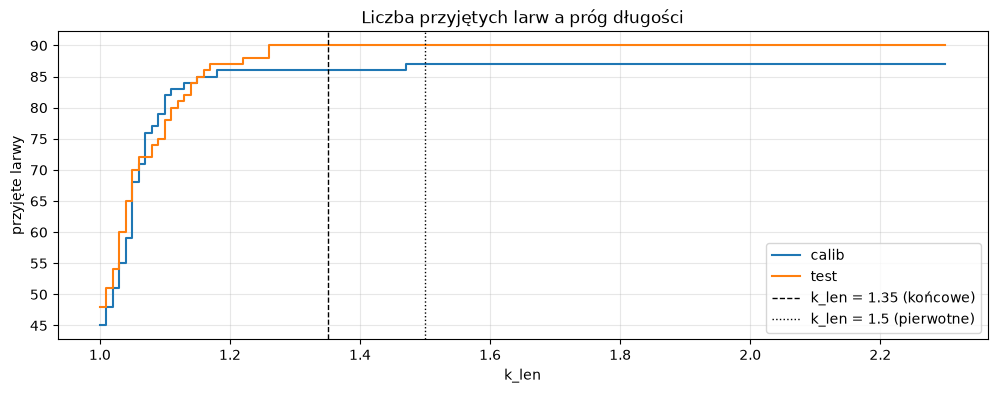

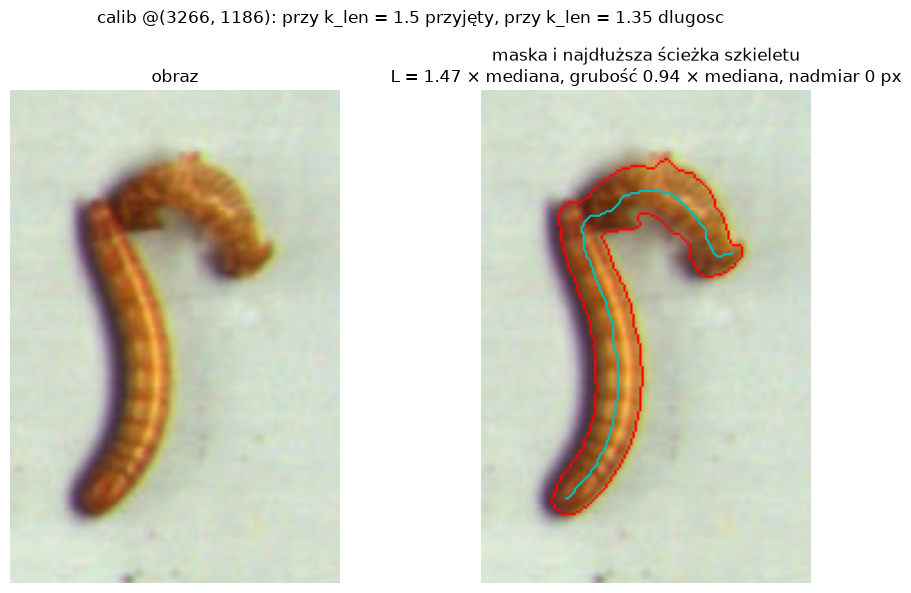

In [21]:
# Liczba przyjętych larw w funkcji k_len (pozostałe reguły bez zmian), na gotowych kandydatach z detekcji
k_grid = np.round(np.arange(1.0, 2.31, 0.01), 2)
f, ax = plt.subplots(figsize=(12, 4))
for name, dbg in (('calib', dbg_calib), ('test', dbg_test)):
    n_ok = [sum(c['reason'] is None for c in filter_candidates(dbg['candidates'], k_len=k)[0]) for k in k_grid]
    ax.step(k_grid, n_ok, where='post', lw=1.5, label=name)
    plateau = k_grid[np.array(n_ok) == n_ok[list(k_grid).index(1.35)]]
    print(f'{name}: przy k_len = 1.35 przyjętych {n_ok[list(k_grid).index(1.35)]}, przy 1.5: {n_ok[list(k_grid).index(1.5)]}; '
          f'ta sama liczba dla k_len {plateau.min():.2f}-{plateau.max():.2f}')
for k, style, label in ((1.35, '--', 'k_len = 1.35 (końcowe)'), (1.5, ':', 'k_len = 1.5 (pierwotne)')):
    ax.axvline(k, color='k', ls=style, lw=1, label=label)
ax.set(xlabel='k_len', ylabel='przyjęte larwy', title='Liczba przyjętych larw a próg długości')
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.grid(alpha=0.3)
ax.legend()

# Kandydaci, dla których k_len = 1.5 i k_len = 1.35 dają różną decyzję
changed = []
for name, img, dbg in (('calib', calib, dbg_calib), ('test', test, dbg_test)):
    at_15, _ = filter_candidates(dbg['candidates'], k_len=1.5)
    at_135, _ = filter_candidates(dbg['candidates'], k_len=1.35)
    changed += [(name, img, dbg, c15, c135) for c15, c135 in zip(at_15, at_135) if c15['reason'] != c135['reason']]
print(f'decyzja zmienia się dla {len(changed)} kandydatów')
for name, img, dbg, c15, c135 in changed:
    x, y, w, h = c135['bbox']
    pad = 30
    x0, y0 = max(x - pad, 0), max(y - pad, 0)
    crop = np.ascontiguousarray(img[y0:y + h + pad, x0:x + w + pad, ::-1]).copy()
    f, (a1, a2) = plt.subplots(1, 2, figsize=(10, 6))
    a1.imshow(crop)
    a1.set_title('obraz')
    cv2.drawContours(crop, [c135['contour'] - [x0, y0]], -1, (255, 0, 0), 1)
    a2.imshow(crop)
    path = c135['skeleton_path']
    a2.plot(path[:, 1] + x - x0, path[:, 0] + y - y0, 'c-', lw=1.5)
    a2.set_title(f"maska i najdłuższa ścieżka szkieletu\nL = {c135['length_px'] / dbg['ref_len']:.2f} × mediana, "
                 f"grubość {c135['width_est'] / dbg['ref_width']:.2f} × mediana, nadmiar {c135['skeleton_extra']:.0f} px")
    for ax in (a1, a2):
        ax.axis('off')
    f.suptitle(f"{name} @({x}, {y}): przy k_len = 1.5 {c15['reason'] or 'przyjęty'}, przy k_len = 1.35 {c135['reason'] or 'przyjęty'}")
    plt.tight_layout()

**Wniosek:**
* **Długość (`k_len` = 1.35).** Pojedyncze larwy mają do 1.25× mediany (95. percentyl ok. 1.1×), a zlepki stykające się końcami od 1.47×. Najkrótszy zlepek to obiekt z `calib` @(3266, 1186): **dwie larwy**, prosta i zwinięta, stykające się końcami. Ma czysty szkielet (nadmiar 0), a najdłuższa ścieżka biegnie przez obie larwy. Jest też cieńszy od mediany (0.94×), więc pozostałe reguły go przepuszczają. Pierwotny próg 1.5 leżał tuż nad nim, więc ten zlepek trafiał do wyników jako pojedyncza larwa. Próg 1.35 leży w środku przerwy 1.25–1.47. Dla `k_len` od 1.26 do 1.46 liczba przyjętych larw na obu obrazach się nie zmienia (wykres), więc dokładna wartość w tym zakresie nie ma znaczenia. Granica nie może być ostra: dwie małe larwy (po ok. 0.6×) dają razem tyle, co długa pojedyncza larwa.
* **Grubość (`k_width` = 1.25).** Pojedyncze larwy mają do 1.23× (krótka, skurczona larwa w `calib`), a zlepki od 1.26×. Ten zlepek z `test` i tak odpada przez długość, a zlepki, które łapie tylko grubość, mają od 1.30×. Próg leży w przerwie, ale przerwa jest wąska. Blada, krótka larwa z `calib` @(3546, 1129) przy stałej `delta` = 30 odpadała tu z grubością 1.48×, bo maska obejmowała poświatę. Po dopasowaniu `delta` do ROI ma 1.19× i przechodzi filtr (kroki 3–4). Na `test` przez grubość odpada larwa leżąca przy lewej ściance (1.32×): jej maska obejmuje rozmyty cień na ściance.
* **Pole (`k_area` = 1.6).** Pole nie oddziela pojedynczych larw od zlepków. Duże pojedyncze larwy mają do ok. 1.34× mediany, a dwie larwy sklejone bokiem już od 1.23×, bo częściowo na siebie nachodzą. Na obu obrazach reguła `pole` nie zadziałała ani razu jako pierwsza: każdy kandydat powyżej 1.6× odpada wcześniej przez `szkielet` albo `dlugosc`. Zostawiam ją jako zabezpieczenie. To pokazuje też, dlaczego sam filtr pola, czyli najprostsza alternatywa, by nie wystarczył: myli rozmiar larwy z liczbą larw.
* **Skutek uboczny progów względnych:** reguły `dlugosc` i `grubosc` z definicji obcinają górny ogon rozkładu długości i grubości, który potem mierzę. Na tych obrazach pojedyncze larwy kończą się wyraźnie poniżej progów, więc to nie przeszkadza. W partii o większym rozrzucie rozmiarów te reguły wycięłyby jednak największe osobniki. Reguła `szkielet` nie zależy od rozmiaru i tej wady nie ma.

### Krok 6: rozdzielanie zlepków i usuwanie wypustek (`split_candidates`)

Krok 5 zostawia dwa rodzaje błędów. Zlepki odrzuca w całości, choć część z nich da się rozdzielić. Larwy z drobną wypustką (nadmiar szkieletu poniżej 30 px) przyjmuje razem z wypustką, która zostaje w masce. Wypustka to zwykle przyklejony okruch, kawałek wylinki albo odchód. Obie sytuacje mają podobną budowę: dwa obiekty łączy wąski mostek z pikseli mieszanych, o niższym S niż ciało larwy. Wyższy próg na S rozcina takie mostki (wniosek z kroku 1), ale podniesiony dla całego obrazu gubi blade larwy (sekcja o wrażliwości niżej). Dlatego podnoszę go tylko w obrębie maski jednego kandydata.

Krok 6 dostaje kandydatów odrzuconych jako zlepki (`szkielet`, `dlugosc`, `grubosc`) i larwy przyjęte, których szkielet ma boczną gałąź (nadmiar ≥ `branch_extra` = 3 px). Przyjęte larwy mają nadmiar albo 0, albo co najmniej 4 px, więc dokładna wartość nie ma znaczenia. Dla każdego kandydata `split_candidate` sprawdza progi na S co 10 (`thr_step`), od pierwszego powyżej progu lokalnego z kroku 3 do 200. Przy każdym progu `clump_parts` robi:
1. progowanie S w obrębie maski kandydata,
2. otwarcie elipsą 5×5 (`open_k`), które przecina cienkie mostki,
3. składowe ≥ 500 px (`min_part`) jako znaczniki; mniejsze to okruchy i odpadają,
4. odbudowę każdego znacznika o 6 px (`grow`) funkcją `skimage.segmentation.expand_labels`, tylko w granicach maski kandydata. Wyższy próg działa jak erozja, a to jest operacja odwrotna: dylatacja, w której piksel trafia do najbliższego znacznika, więc sąsiednie larwy się nie sklejają.

Przyjmuję najniższy próg, przy którym podział jest poprawny:
* każda część przechodzi filtr z kroku 5 (z medianami całego obrazu),
* każda część ma długość ≥ 0.7 × mediana (`k_min`). Krótsza część to najpewniej kawałek larwy przykrytej przez inną,
* części razem pokrywają ≥ 94% maski kandydata (`min_cover`). Inaczej przy tym progu zniknęła cała larwa (np. blada) i jej kawałek mógł się dokleić do sąsiadki albo wysoki próg zjadł brzeg larwy,
* jeśli została jedna część, jej szkielet nie ma bocznej gałęzi (nadmiar < `clean_extra` = 3 px). Jedna część to ta sama larwa, więc jedyną korzyścią jest usunięcie wypustki i wypustka musi zniknąć.

Jeśli żaden próg nie daje poprawnego podziału, kandydat zostaje bez zmian: zlepek odrzucony, a larwa przyjęta z dotychczasową maską. Tak jak w całym potoku: lepiej zgubić larwę niż zapisać złą maskę.

Krok 6 liczy `detect_objects`, więc jego wynik jest już w `objs_calib` i `objs_test` (komórka z pełną detekcją w kroku 5). Na RoI krok 6 niczego nie zmienia, więc niżej są całe obrazy.

calib: 86 larw po kroku 5 -> 92 po kroku 6; zlepki: podzielone 3 z 17 (+6 larw); wypustki: usunięte u 4 z 10 larw
  zlepek   @(1759, 1867) (dlugosc, nadmiar 19 px): próg 190, części 2, L = 0.88, 1.06 x mediana, pokrycie 0.99
  zlepek   @(2835, 1810) (dlugosc, nadmiar 5 px): próg 170, części 2, L = 1.08, 0.97 x mediana, pokrycie 1.00
  wypustka @(1936, 1366) (przyjęta, nadmiar 14 px): próg 180, części 1, L = 0.90 x mediana, pokrycie 0.96
  wypustka @(2554, 1192) (przyjęta, nadmiar 18 px): próg 130, części 1, L = 0.85 x mediana, pokrycie 0.95
  wypustka @(2378, 988) (przyjęta, nadmiar 23 px): próg 160, części 1, L = 1.02 x mediana, pokrycie 0.96
  zlepek   @(2356, 723) (szkielet, nadmiar 46 px): próg 150, części 2, L = 0.93, 0.98 x mediana, pokrycie 1.00
  wypustka @(3058, 616) (przyjęta, nadmiar 9 px): próg 180, części 1, L = 0.95 x mediana, pokrycie 0.98
test: 90 larw po kroku 5 -> 103 po kroku 6; zlepki: podzielone 7 z 24 (+13 larw); wypustki: usunięte u 3 z 8 larw
  zlepek   @(3319, 

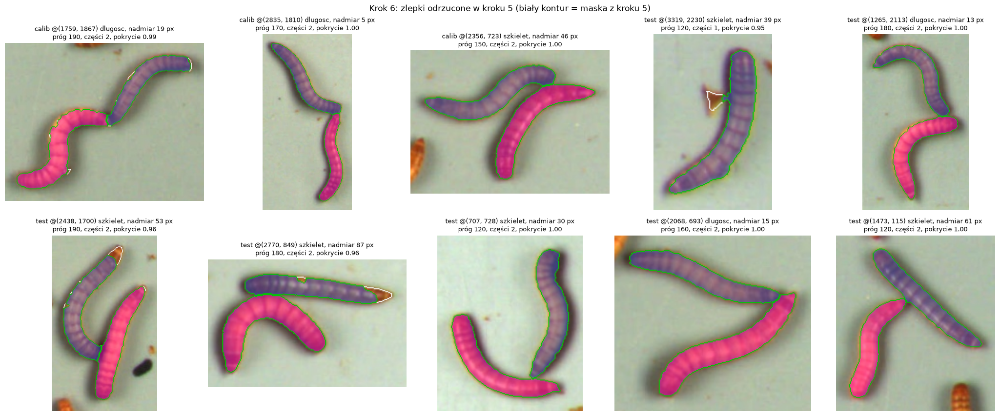

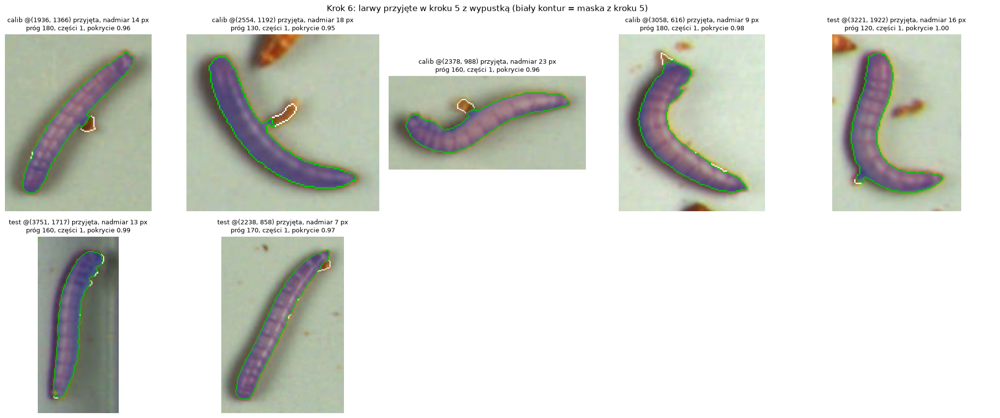

In [22]:
SPLIT_FILLS = [(40, 90, 255), (255, 0, 255), (0, 220, 255), (255, 230, 0)]  # bez czerwieni i zieleni


def show_splits(image, splits: List, title_fn=None, cols: int = 4, pad: int = 15, title: str = None,
                accepted: bool = True):
    """Galeria wyników kroku 6: wycinek kandydata, biały kontur = maska z kroku 5, każda część innym kolorem
    wypełnienia, kontur części w kolorze decyzji: zielony = podział przyjęty, czerwony = odrzucony (`accepted=False`).
    image: obraz albo słownik {nazwa: obraz}; wtedy obraz wybiera pole s['img_name']."""
    if not splits:
        print('(brak podziałów)')
        return
    rows = int(np.ceil(len(splits) / cols))
    f, axes = plt.subplots(rows, cols, figsize=(4.2 * cols, 4.2 * rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis('off')
    for ax, s in zip(axes.ravel(), splits):
        c = s['cand']
        crop, x0, y0 = crop_around(image[s['img_name']] if isinstance(image, dict) else image, c, pad)
        overlay = crop.copy()
        for k, p in enumerate(s['parts']):
            cv2.drawContours(overlay, [p['contour'] - [x0, y0]], -1, SPLIT_FILLS[k % len(SPLIT_FILLS)], -1)
        crop = cv2.addWeighted(overlay, 0.4, crop, 0.6, 0)
        cv2.drawContours(crop, [c['contour'] - [x0, y0]], -1, (255, 255, 255), 1)
        for p in s['parts']:
            cv2.drawContours(crop, [p['contour'] - [x0, y0]], -1, ACCEPT_RGB if accepted else REJECT_RGB, 1)
        ax.imshow(crop)
        cover = sum(p['area'] for p in s['parts']) / c['area']
        ax.set_title(title_fn(s) if title_fn else
                     f"{s.get('img_name', '')} @({c['bbox'][0]}, {c['bbox'][1]}) {c['reason'] or 'przyjęta'}, "
                     f"nadmiar {c['skeleton_extra']:.0f} px\npróg {s['thr']}, części {len(s['parts'])}, pokrycie {cover:.2f}",
                     fontsize=9)
    plt.tight_layout()
    if title:
        f.suptitle(title, y=1.01)


# Wynik kroku 6 (policzony w detect_objects razem z krokami 1-5, komórka z pełną detekcją w kroku 5)
images, infos = {'calib': calib, 'test': test}, {'calib': dbg_calib, 'test': dbg_test}
for (name, info), objs in zip(infos.items(), (objs_calib, objs_test)):
    n5 = sum(c['reason'] is None for c in info['candidates'])
    clumps = [s for s in info['splits'] if s['kind'] == 'zlepek']
    cleaned = [s for s in info['splits'] if s['kind'] == 'wypustka']
    n_clumps = sum(c['reason'] in CLUMP_REASONS for c in info['candidates'])
    n_branch = sum(c['reason'] is None and c['skeleton_extra'] >= 3 for c in info['candidates'])  # branch_extra = 3
    print(f"{name}: {n5} larw po kroku 5 -> {len(objs)} po kroku 6; zlepki: podzielone {len(clumps)} z {n_clumps} "
          f"(+{sum(len(s['parts']) for s in clumps)} larw); wypustki: usunięte u {len(cleaned)} z {n_branch} larw")
    for s in info['splits']:
        c = s['cand']
        L = [p['length_px'] / info['ref_len'] for p in s['parts']]
        cover = sum(p['area'] for p in s['parts']) / c['area']
        print(f"  {s['kind']:8s} @{c['bbox'][:2]} ({c['reason'] or 'przyjęta'}, nadmiar {c['skeleton_extra']:.0f} px): "
              f"próg {s['thr']}, części {len(s['parts'])}, L = {', '.join(f'{l:.2f}' for l in L)} x mediana, pokrycie {cover:.2f}")

for kind, label in (('zlepek', 'zlepki odrzucone w kroku 5'), ('wypustka', 'larwy przyjęte w kroku 5 z wypustką')):
    show_splits(images, [dict(s, img_name=name) for name, info in infos.items() for s in info['splits'] if s['kind'] == kind],
                cols=5, title=f'Krok 6: {label} (biały kontur = maska z kroku 5)')

#### Eksperyment: czy wypustki usuwa binaryzacja albo erozja B

Wypustki to w większości okruchy, kawałki wylinki i odchody przyklejone do larwy, czasem odnóże albo zagięta główka. Sprawdzam, czy usunęłaby je wcześniejsza część potoku. Dla każdej larwy przyjętej w kroku 5 z boczną gałęzią szkieletu porównuję nadmiar przy mocniejszej erozji na B (`alpha` = 0.15 i 0.10 zamiast 0.25; ten sam obiekt wybieram po największym IoU masek) z wynikiem kroku 6, czyli wyższego progu na S w obrębie maski. Dla larw, których krok 6 nie oczyszcza, podaję najniższy próg, przy którym gałąź znika, i pokrycie maski przy tym progu (bez warunku `min_cover`). Na koniec porównuję S i B pikseli usuniętych przez krok 6 z resztą maski tych larw.

In [23]:
# Wypustki a binaryzacja (S) i erozja brzegu (B): larwy przyjęte w kroku 5 z boczną gałęzią szkieletu
def mask_iou(a: dict, b: dict) -> float:
    """IoU masek dwóch obiektów (współrzędne globalne); 0, gdy prostokąty się nie przecinają."""
    (ax, ay, aw, ah), (bx, by, bw, bh) = a['bbox'], b['bbox']
    x0, y0, x1, y1 = min(ax, bx), min(ay, by), max(ax + aw, bx + bw), max(ay + ah, by + bh)
    if x1 - x0 > aw + bw or y1 - y0 > ah + bh:
        return 0.0
    m = np.zeros((2, y1 - y0, x1 - x0), bool)
    for k, o in enumerate((a, b)):
        x, y, w, h = o['bbox']
        m[k, y - y0:y - y0 + h, x - x0:x - x0 + w] = o['mask'] > 0
    return float((m[0] & m[1]).sum() / (m[0] | m[1]).sum())


ALPHAS = (0.15, 0.10)
alpha_cands = {(name, a): detect_objects(images[name], S_THR, refine_alpha=a, debug=True)[1]['candidates']
               for name in images for a in ALPHAS}

print(f"{'larwa':22s} | nadmiar przy alpha 0.25 / {' / '.join(f'{a:.2f}' for a in ALPHAS)} | krok 6")
removed_S, removed_B, kept_S, kept_B = [], [], [], []
for name, info in infos.items():
    S, B = info['S'], images[name][..., 0]
    by_cand = {id(s['cand']): s for s in info['splits']}
    for c in info['candidates']:
        if c['reason'] is not None or c['skeleton_extra'] < 3:
            continue
        cols = [f"{c['skeleton_extra']:4.0f}"]
        for a in ALPHAS:  # ten sam obiekt w potoku z inną alpha: największe IoU masek
            d = max(alpha_cands[name, a], key=lambda d: mask_iou(c, d))
            cols.append(f"{d['skeleton_extra']:4.0f}" + (f" ({d['reason']})" if d['reason'] else ''))
        split = by_cand.get(id(c))
        if split:
            cover = sum(p['area'] for p in split['parts']) / c['area']
            res = f"wypustka usunięta: próg {split['thr']}, pokrycie {cover:.2f}"
            # piksele usunięte przez krok 6 (wypustka) a reszta maski: średnie S i B
            x, y, w, h = c['bbox']
            kept = np.zeros((h, w), bool)
            for p in split['parts']:
                px, py, pw, ph = p['bbox']
                kept[py - y:py - y + ph, px - x:px - x + pw] |= p['mask'] > 0
            gone = (c['mask'] > 0) & ~kept
            removed_S.append(S[y:y + h, x:x + w][gone].mean()); kept_S.append(S[y:y + h, x:x + w][kept].mean())
            removed_B.append(B[y:y + h, x:x + w][gone].mean()); kept_B.append(B[y:y + h, x:x + w][kept].mean())
        else:  # bez warunku pokrycia: przy jakim progu gałąź znika i ile maski wtedy zostaje
            thr, parts = split_candidate(S, c, info['filt'], min_cover=0)
            res = (f"zostaje; gałąź znika dopiero przy progu {thr}, pokrycie {sum(p['area'] for p in parts) / c['area']:.2f}"
                   if parts else 'zostaje; gałąź nie znika przy żadnym progu')
        print(f"{name} @{str(c['bbox'][:2]):15s} | {' / '.join(cols):30s} | {res}")
print(f"\npiksele usunięte przez krok 6: średnie S {np.mean(removed_S):.0f}, B {np.mean(removed_B):.0f}; "
      f"reszta maski tych larw: S {np.mean(kept_S):.0f}, B {np.mean(kept_B):.0f} (próg lokalny S ok. 100-115)")

larwa                  | nadmiar przy alpha 0.25 / 0.15 / 0.10 | krok 6
calib @(1936, 1366)    |   14 /   15 /   12             | wypustka usunięta: próg 180, pokrycie 0.96
calib @(2554, 1192)    |   18 /    0 /    0             | wypustka usunięta: próg 130, pokrycie 0.95
calib @(3546, 1129)    |   15 /   19 (grubosc) /    3 (grubosc) | zostaje; gałąź nie znika przy żadnym progu
calib @(2378, 988)     |   23 /   26 /   26             | wypustka usunięta: próg 160, pokrycie 0.96
calib @(901, 954)      |   13 /    4 /    7             | zostaje; gałąź nie znika przy żadnym progu
calib @(891, 884)      |    9 /   10 /   10             | zostaje; gałąź znika dopiero przy progu 190, pokrycie 0.84
calib @(1187, 683)     |   12 /    0 /    0             | zostaje; gałąź znika dopiero przy progu 190, pokrycie 0.89
calib @(1863, 647)     |   26 /   23 /   27             | zostaje; gałąź nie znika przy żadnym progu
calib @(3058, 616)     |    9 /    3 /    0             | wypustka usunięta: pró

#### Eksperyment: parametry kroku 6 i zabezpieczenia

Zmieniam po jednym parametrze (pozostałe mają wartości końcowe) i liczę larwy po kroku 6. Obok: kandydaci podzieleni dodatkowo (+), utraceni (−) albo podzieleni przy innym progu (~) względem wersji końcowej. Krok 6 działa na gotowych kandydatach z kroku 5 (`split_candidates`), więc segmentacji nie powtarzam.

Pod tabelą: podziały, które przechodzą tylko bez jednego z zabezpieczeń (`k_min = 0`, `min_cover = 0` albo `clean_extra = 30`), z długością części względem mediany (L) i pokryciem maski kandydata. Na nich widać, co zabezpieczenia odrzucają. W wersji końcowej te podziały są odrzucone, więc mają czerwony kontur.

wariant           | calib                                                        | test


końcowe           |  92 larw                                                     | 103 larw 


open_k = 0        |  90 larw -@(2835, 1810) ~@(1936, 1366): 180->190 ~@(2356, 723): 150->160 ~@(2554, 1192): 130->140 | 103 larw +@(632, 1251) +@(1501, 658) -@(2238, 858) ~@(1473, 115): 120->130 ~@(2068, 693): 160->170 ~@(3221, 1922): 120->140


open_k = 3        |  90 larw -@(2835, 1810) ~@(1936, 1366): 180->190 ~@(2356, 723): 150->160 ~@(2554, 1192): 130->140 | 104 larw +@(3, 82) +@(632, 1251) +@(1501, 658) -@(2238, 858) ~@(3221, 1922): 120->130


open_k = 7        |  93 larw +@(3098, 739) ~@(1759, 1867): 190->180 ~@(1936, 1366): 180->170 ~@(2356, 723): 150->140 ~@(2378, 988): 160->140 ~@(2554, 1192): 130->110 |  99 larw +@(1645, 1954) -@(2238, 858) -@(2438, 1700) -@(2770, 849) ~@(1265, 2113): 180->170 ~@(3319, 2230): 120->110


grow = 0          |  86 larw +@(1187, 683) -@(1759, 1867) -@(1936, 1366) -@(2356, 723) -@(2378, 988) -@(2554, 1192) -@(2835, 1810) -@(3058, 616) |  94 larw +@(1501, 658) +@(1645, 1954) -@(1265, 2113) -@(2068, 693) -@(2238, 858) -@(2438, 1700) -@(2770, 849) -@(3319, 2230) ~@(3221, 1922): 120->110 ~@(3751, 1717): 160->110


... (11 outputs left out)

min_cover = 0.95  |  92 larw                                                     | 103 larw 


min_cover = 0.96  |  92 larw -@(2554, 1192)                                      | 102 larw -@(3319, 2230)


clean_extra = 30  |  93 larw +@(891, 884) +@(901, 954) +@(1187, 683) +@(1509, 339) +@(1632, 253) +@(1863, 647) ~@(1936, 1366): 180->120 ~@(2378, 988): 160->120 ~@(2554, 1192): 130->110 ~@(3058, 616): 180->110 | 103 larw +@(632, 1251) +@(1501, 658) +@(1645, 1954) +@(3514, 1693) ~@(2238, 858): 170->110 ~@(3221, 1922): 120->110 ~@(3751, 1717): 160->100


thr_step = 5      |  92 larw ~@(1759, 1867): 190->185 ~@(2378, 988): 160->155    | 103 larw +@(632, 1251) ~@(1265, 2113): 180->175 ~@(2770, 849): 180->175 ~@(3319, 2230): 120->115
calib: larwy przyjęte w kroku 5 krótsze niż 0.7 x mediana: 2 z 86 (0.53, 0.57)
test: larwy przyjęte w kroku 5 krótsze niż 0.7 x mediana: 1 z 90 (0.57)


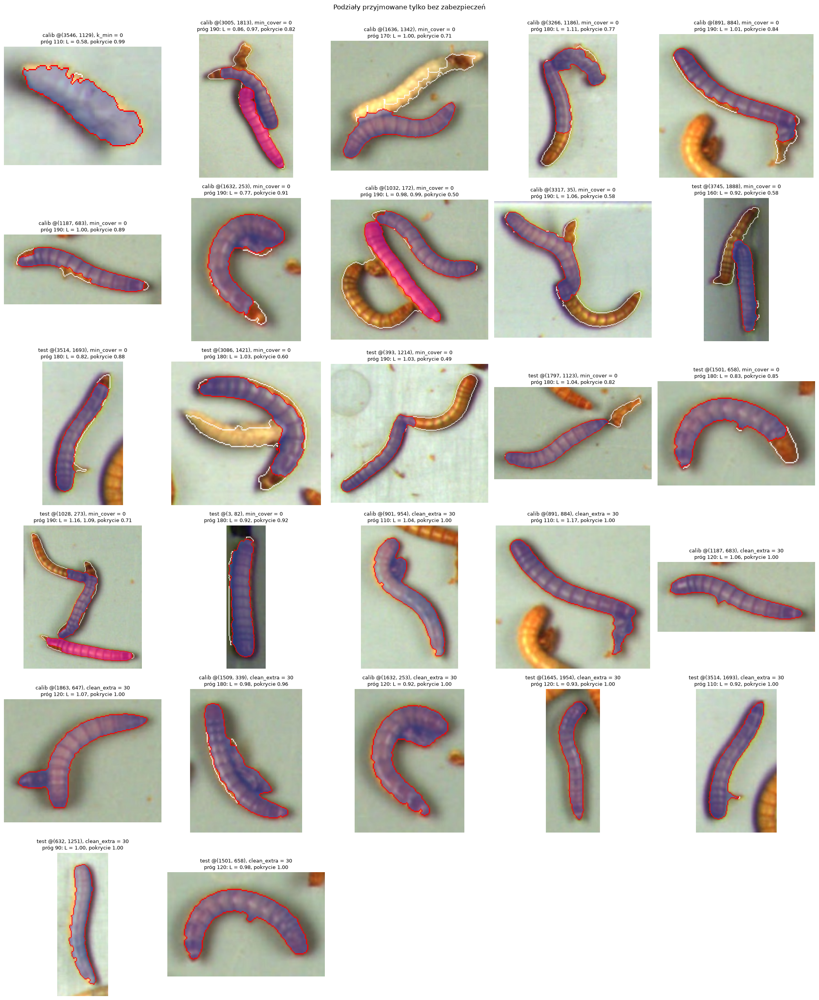

In [24]:
# Ablacja kroku 6: po jednym parametrze, reszta ma wartości końcowe. Krok 6 działa na gotowych kandydatach
# z kroku 5 (info['candidates']), więc segmentacji nie powtarzam.
variants = [('końcowe', {}),
            ('open_k = 0', dict(open_k=0)), ('open_k = 3', dict(open_k=3)), ('open_k = 7', dict(open_k=7)),
            ('grow = 0', dict(grow=0)), ('grow = 3', dict(grow=3)), ('grow = 10', dict(grow=10)),
            ('min_part = 200', dict(min_part=200)), ('min_part = 1000', dict(min_part=1000)),
            ('k_min = 0', dict(k_min=0)), ('k_min = 0.6', dict(k_min=0.6)), ('k_min = 0.8', dict(k_min=0.8)),
            ('min_cover = 0', dict(min_cover=0)), ('min_cover = 0.9', dict(min_cover=0.9)),
            ('min_cover = 0.92', dict(min_cover=0.92)), ('min_cover = 0.93', dict(min_cover=0.93)),
            ('min_cover = 0.95', dict(min_cover=0.95)), ('min_cover = 0.96', dict(min_cover=0.96)),
            ('clean_extra = 30', dict(clean_extra=30)), ('thr_step = 5', dict(thr_step=5))]
GUARDS = ('k_min = 0', 'min_cover = 0', 'clean_extra = 30')
final = {name: {s['cand']['bbox']: s['thr'] for s in info['splits']} for name, info in infos.items()}
guard_cases = []
print(f"{'wariant':17s} | {'calib':60s} | test")
for label, kw in variants:
    row = []
    for name, info in infos.items():
        splits = split_candidates(info['S'], info['candidates'], info['filt'], **kw)
        n_larvae = (sum(c['reason'] is None for c in info['candidates'])
                    + sum(len(s['parts']) - (s['kind'] == 'wypustka') for s in splits))
        thr = {s['cand']['bbox']: s['thr'] for s in splits}
        diff = ([f'+@{b[:2]}' for b in sorted(thr.keys() - final[name].keys())] +
                [f'-@{b[:2]}' for b in sorted(final[name].keys() - thr.keys())] +
                [f'~@{b[:2]}: {final[name][b]}->{thr[b]}' for b in sorted(thr.keys() & final[name].keys()) if thr[b] != final[name][b]])
        row.append(f"{n_larvae:3d} larw {' '.join(diff)}")
        if label in GUARDS:
            guard_cases += [dict(s, img_name=name, label=label,
                                 L=[p['length_px'] / info['ref_len'] for p in s['parts']],
                                 cover=sum(p['area'] for p in s['parts']) / s['cand']['area'])
                            for s in splits if s['cand']['bbox'] not in final[name]]
    print(f'{label:17s} | {row[0]:60s} | {row[1]}')

# Uzasadnienie k_min: ile pojedynczych larw z kroku 5 jest krótszych niż 0.7 x mediana
for name, info in infos.items():
    L = sorted(c['length_px'] / info['ref_len'] for c in info['candidates'] if c['reason'] is None)
    print(f"{name}: larwy przyjęte w kroku 5 krótsze niż 0.7 x mediana: {sum(l < 0.7 for l in L)} z {len(L)} "
          f"({', '.join(f'{l:.2f}' for l in L if l < 0.7)})")

show_splits(images, guard_cases, cols=5, title='Podziały przyjmowane tylko bez zabezpieczeń', accepted=False,
            title_fn=lambda s: (f"{s['img_name']} @{s['cand']['bbox'][:2]}, {s['label']}\n"
                                f"próg {s['thr']}: L = {', '.join(f'{l:.2f}' for l in s['L'])}, pokrycie {s['cover']:.2f}"))

**Wniosek (krok 6):**
* **Zlepki.** Krok 6 zamienia na larwy 3 z 17 zlepków na `calib` i 7 z 24 na `test` (+6 i +13 larw). Rozdzielają się pary, które stykają się końcami albo bokiem przez poświatę. Wśród nich jest para `test` @(707, 728), którą przy stałej `delta` = 30 rozcinała erozja w kroku 4 (kroki 3–4). Na `test` krok 6 odzyskuje też larwę @(3319, 2230), odrzuconą w kroku 5 jako `szkielet` przez przyklejony okruch: przy progu 120 okruch odpada i zostaje jedna larwa bez wypustki. Skrzyżowane larwy zostają odrzucone, bo przykryta larwa rozpada się na kawałki, które nie przechodzą `k_min` albo `min_cover`.
* **Wypustki.** Krok 6 usuwa wypustkę u 4 z 10 larw na `calib` i u 3 z 8 na `test`. Usunięte są okruchy i kawałki wylinki przyklejone do boku larwy oraz cienkie wyrostki na końcach. Reszta maski prawie się nie zmienia (pokrycie 0.95–1.00, galeria wyżej). Razem: `calib` 86 → 92 larw, `test` 90 → 103.
* **Dlaczego nie binaryzacja ani erozja B.** Piksele usunięte przez krok 6 mają średnio S = 154 i B = 53, a reszta maski tych larw S = 183 i B = 45. Wypustka jest więc trochę bledsza od ciała, ale dużo bardziej nasycona niż tło (próg lokalny ok. 100–115) i tak samo ciemna w B. Próg wspólny dla całego obrazu, który odciąłby wypustki, odciąłby wcześniej brzegi i blade fragmenty larw (sekcja o wrażliwości). Mocniejsza erozja B też nie pomaga: przy `alpha` = 0.15 nadmiar znika u 7 z 18 larw, ale u 7 innych rośnie (najbardziej 8 → 16 px i 4 → 13 px), blada larwa @(3546, 1129) odpada przez `grubosc`, a po stronie oświetlonej erozja wcina się w ciało wszystkich larw (kroki 3–4). Erozja działa na cały obrys, a wypustka to tylko jego mały fragment. Wyższy próg działa dopiero lokalnie, w obrębie jednej maski, czyli w kroku 6.
* **Wypustki, które zostają (6 na `calib`, 5 na `test`).** U 6 larw gałąź nie znika przy żadnym progu do 200: wyrostek jest tak samo nasycony jak ciało (np. ciemny wyrostek @(1863, 647)) albo larwa jest blada i jej maska ma wcięcia (@(3546, 1129), `test` @(632, 1251) i @(3158, 617)). U 5 gałąź znika dopiero przy progu 180–190, ale wtedy zostaje 84–91% maski: wysoki próg zjada brzeg albo koniec larwy (galeria niżej, `min_cover = 0`). Te larwy zostają przyjęte z wypustką, tak jak po kroku 5.
* **Otwarcie (`open_k` = 5).** Przy 0 i 3×3 na `calib` nie rozdziela się para @(2835, 1810), a na `test` zamiast wypustki @(2238, 858) znikają wypustki @(632, 1251) i @(1501, 658). Przy 3×3 przechodzi też larwa na ściance @(3, 82). Przy 7×7 na `test` giną pary @(2438, 1700) i @(2770, 849) oraz oczyszczenie @(2238, 858), a dochodzą dwie inne zmiany (zlepek `calib` @(3098, 739) zamieniony na jedną larwę i wypustka `test` @(1645, 1954)). Każda wartość oczyszcza z wypustek trochę inny zestaw larw, ale przy 5 krok 6 rozdziela najwięcej zlepków. Wszystkie zmiany przy wartościach końcowych sprawdziłem wzrokowo.
* **Odbudowa (`grow` = 6 px).** Bez niej prawie nic nie przechodzi (`calib` 86 larw, tyle co po kroku 5, `test` 94): części po wysokim progu są cieńsze i krótsze od larw. Przy 3 px znika 1 podział zlepka na `calib` i 2 na `test`. Przy 10 px podziały zlepków na dwie larwy są te same, ale szersza odbudowa dokleja część wypustek z powrotem: znika 5 oczyszczeń (w tym larwa z okruchem @(3319, 2230)), a dochodzą 2 inne.
* **`min_part`** od 200 do 1000 px nie zmienia wyniku (przy 200 jeden podział zapada przy progu wyższym o 10).
* **`k_min` = 0.7.** Bez niego przechodzi tylko oczyszczenie bladej larwy @(3546, 1129), która sama jest krótka (0.58×). Zły podział `test` @(393, 1214), który wcześniej łapał tylko `k_min` (kawałek larwy 0.49× razem z sąsiadką), ma pokrycie 0.937, więc teraz odrzuca go też `min_cover`. Wśród larw przyjętych w kroku 5 krótsze niż 0.7× są tylko dwie na `calib` (0.53× i 0.57×) i jedna na `test` (0.57×), więc ten próg rzadko szkodzi.
* **`min_cover` = 0.94** (wcześniej 0.9, gdy krok 6 dotyczył tylko zlepków). Bez niego przechodzi 16 dodatkowych zmian, prawie wszystkie złe: znika bledsza larwa, a jej koniec dokleja się do sąsiadki (np. `test` @(1028, 273), 0.71), jedna larwa przykrywa drugą (`calib` @(3005, 1813), 0.82) albo wysoki próg zjada koniec larwy (`calib` @(1632, 253): ogon ucięty, długość spada z 0.92× do 0.77× mediany, pokrycie 0.91). Przy 0.92 przechodzi larwa na ściance `test` @(3, 82) (0.92), a przy 0.96 giną dwie poprawne zmiany z pokryciem 0.95. Wszystkie przyjęte zmiany mają pokrycie ≥ 0.95, odrzucone ≤ 0.92, a wynik jest ten sam dla `min_cover` od 0.93 do 0.95. Kosztem są dwie poprawne zmiany z niskim pokryciem: zlepek `calib` @(1032, 172), w którym obie części są dobre, ale znika trzecia larwa leżąca częściowo pod jedną z nich (0.50), i larwa `test` @(1797, 1123) z dużym kawałkiem wylinki (0.82). Pokrycie nie odróżnia ich od złych podziałów.
* **`clean_extra` = 3 px.** Bez tego warunku (30 px, czyli sam filtr z kroku 5) krok 6 „oczyszcza” larwy, zostawiając gałąź: maska jest tylko przebudowana przy niskim progu, a wypustka zostaje (np. @(1863, 647)). U larw, które oczyszcza wersja końcowa, wybiera wtedy niższy próg, przy którym wypustka jeszcze jest. Przyjmuje też larwę `calib` @(1509, 339) z doklejoną wylinką (nadmiar 25 px).
* **Krok progu 5** zamiast 10 daje te same podziały, część przy progu niższym o 5, i dodatkowo oczyszcza bladą larwę `test` @(632, 1251). Zysk to jedna larwa, więc zostawiam 10.
* Analiza instancji niżej korzysta z pełnego wyniku, czyli z kroków 1–6.

### Wynik: cały obraz kalibracyjny

Parametry końcowe na całym obrazie. Dochodzą trudniejsze przypadki: skrzyżowane i sklejone larwy, okruchy, odchody i larwy przy ściankach pudełka. Pod spodem jest po jednym przykładzie każdego wyniku (OK i każdy powód odrzucenia), krok po kroku.

calib: 92 larw (po kroku 5: 86), odrzucono: {'szkielet': 10, 'dlugosc': 2, 'grubosc': 2}, drobnych obiektów (< min_area): 289
mediana pola = 3240 px, mediana długości szkieletu = 156 px, mediana grubości = 21.2 px


<Axes: title={'center': '92 obiektów, 14 odrzuconych'}>

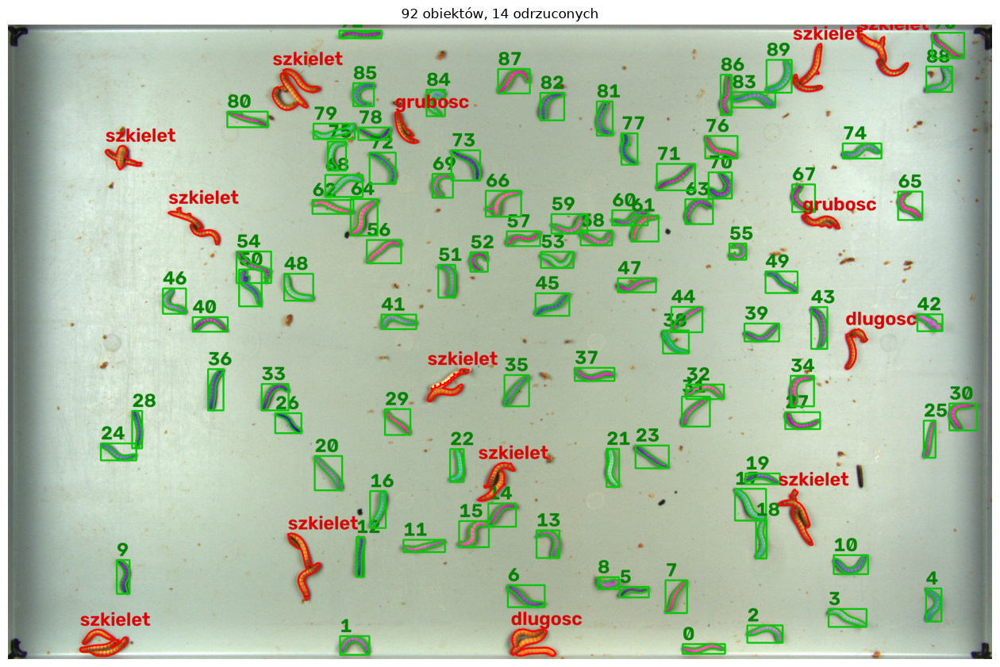

In [25]:
# Cały obraz kalibracyjny (kroki 1-6, detekcja policzona w sekcji kroku 5): zielone = przyjęte larwy, czerwone = odrzuceni kandydaci z powodem
print(f"calib: {len(objs_calib)} larw (po kroku 5: {sum(c['reason'] is None for c in dbg_calib['candidates'])}), odrzucono: {dict(Counter(c['reason'] for c in dbg_calib['rejected']))}, "
      f"drobnych obiektów (< min_area): {dbg_calib['n_small']}")
print(f"mediana pola = {dbg_calib['ref_area']:.0f} px, mediana długości szkieletu = {dbg_calib['ref_len']:.0f} px, "
      f"mediana grubości = {dbg_calib['ref_width']:.1f} px")
display_objects(calib, objs_calib, mode='both', rejected=dbg_calib['rejected'])

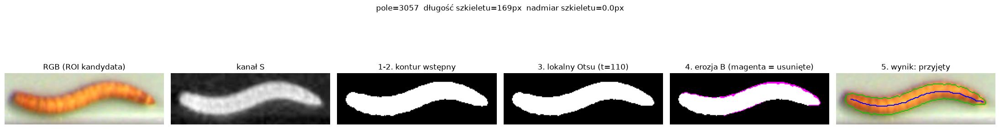

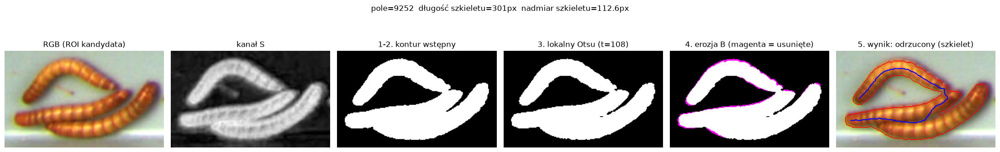

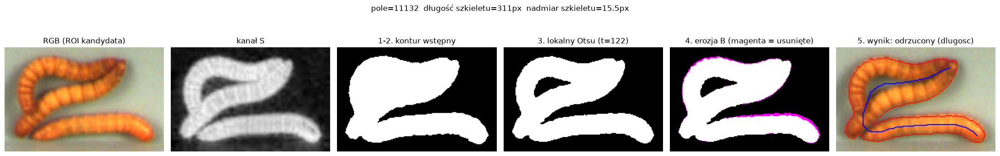

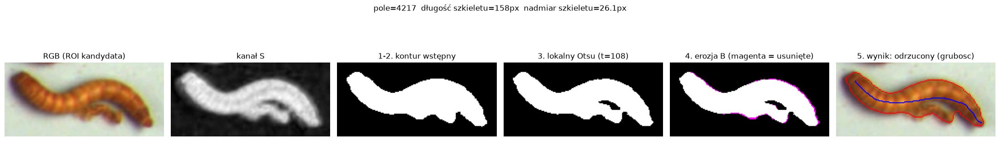

In [26]:
# Pojedyncze obiekty krok po kroku: po jednym przykładzie każdego wyniku (OK + każdy powód odrzucenia).
# Biorę kandydatów, których nie zmienił krok 6, więc decyzja w ostatnim panelu jest ostateczna.
changed = {id(s['cand']) for s in dbg_calib['splits']}
examples = {}
for c in dbg_calib['candidates']:
    if id(c) not in changed:
        examples.setdefault(c['reason'] or 'OK', c)
for reason, cand in examples.items():
    show_candidate_steps(calib, cand)

#### Dlaczego larwy zostały odrzucone

Wszystkie kandydaty z `calib` odrzucone ostatecznie (w kroku 5 i niepodzielone w kroku 6) w powiększeniu, z powodem i wartościami, które o nim zdecydowały. Odniesienia: nadmiar szkieletu < 30 px, długość < 1.35 × mediana, grubość < 1.25 × mediana.

mediany calib: długość 156 px, grubość 21.2 px, pole 3240 px


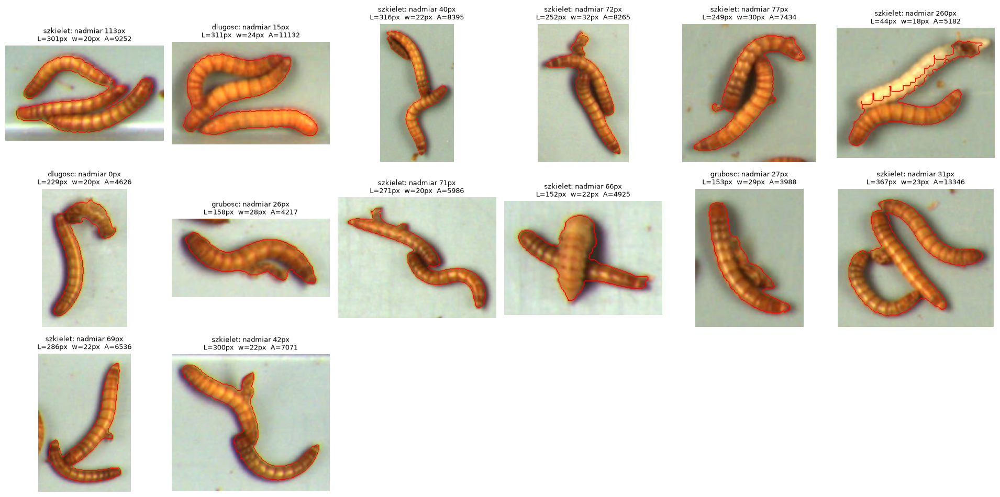

In [27]:
def rejection_title(c) -> str:
    return f"{c['reason']}: nadmiar {c['skeleton_extra']:.0f}px\nL={c['length_px']:.0f}px  w={c['width_est']:.0f}px  A={c['area']}"

print(f"mediany calib: długość {dbg_calib['ref_len']:.0f} px, grubość {dbg_calib['ref_width']:.1f} px, pole {dbg_calib['ref_area']:.0f} px")
show_gallery(calib, dbg_calib['rejected'], rejection_title)

#### Czego w ogóle nie wykrywamy

Odrzuceni kandydaci to nie wszystko. Część obiektów nie przechodzi już przez próg nasycenia (krok 1), więc w ogóle nie staje się kandydatem. Żeby je znaleźć, szukam obiektów wyraźnie innych od tła: ciemniejszych od lokalnej jasności tła albo choć trochę nasyconych, i niepokrytych przez żadnego kandydata. Przy każdym podaję średnie S, które trzeba porównać z progiem `S_THR` = 104.

calib: 9 obiektów spoza kandydatów


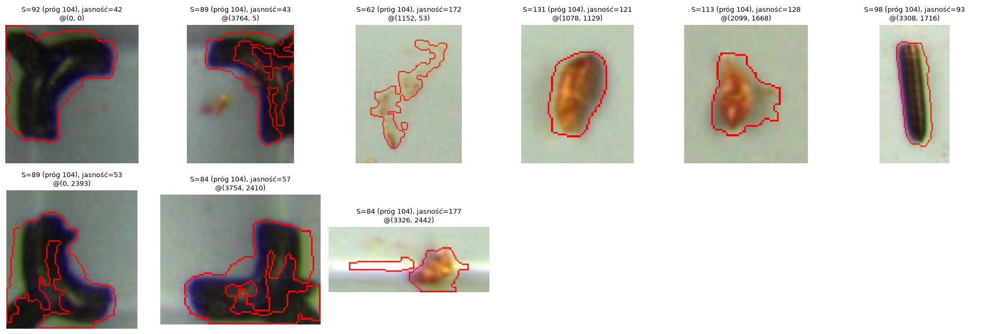

In [28]:
def find_missed(image: np.ndarray, info: dict, min_area: int = 1200, max_area: int = 20000):
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    background = cv2.medianBlur(gray, 51)                       # lokalna jasność tła
    anything = ((np.abs(gray.astype(int) - background.astype(int)) > 35) | (hsv[..., 1] > 40)).astype(np.uint8)
    anything = cv2.morphologyEx(anything, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    covered = np.zeros_like(anything)
    for c in info['candidates']:
        cv2.drawContours(covered, [c['contour']], -1, 1, -1)
    covered = cv2.dilate(covered, np.ones((15, 15), np.uint8))
    n, lab, stats, _ = cv2.connectedComponentsWithStats(anything)
    missed = []
    for i in range(1, n):
        x, y, w, h, a = stats[i]
        if not (min_area <= a <= max_area):
            continue
        comp = (lab[y:y + h, x:x + w] == i)
        if covered[y:y + h, x:x + w][comp].mean() >= 0.2:
            continue
        cnts, _ = cv2.findContours(comp.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        missed.append(dict(bbox=(x, y, w, h), contour=max(cnts, key=cv2.contourArea) + [x, y], reason='brak',
                           mean_S=float(hsv[y:y + h, x:x + w, 1][comp].mean()),
                           mean_gray=float(gray[y:y + h, x:x + w][comp].mean())))
    return missed

missed_calib = find_missed(calib, dbg_calib)
print(f'calib: {len(missed_calib)} obiektów spoza kandydatów')
show_gallery(calib, missed_calib, lambda c: f"S={c['mean_S']:.0f} (próg {S_THR:.0f}), jasność={c['mean_gray']:.0f}\n@({c['bbox'][0]}, {c['bbox'][1]})")

### Wynik: obraz testowy

Te same parametry, bez zmian, na drugim obrazie. Progi względne liczone są na nowo z tego obrazu. Pod spodem: odrzuceni kandydaci i obiekty, których nie wykrywamy.

test: 103 larw (po kroku 5: 90), odrzucono: {'szkielet': 12, 'dlugosc': 4, 'grubosc': 1}, drobnych: 294
mediana pola: calib 3240 / test 3136,  mediana długości: calib 156 / test 153


<Axes: title={'center': '103 obiektów, 17 odrzuconych'}>

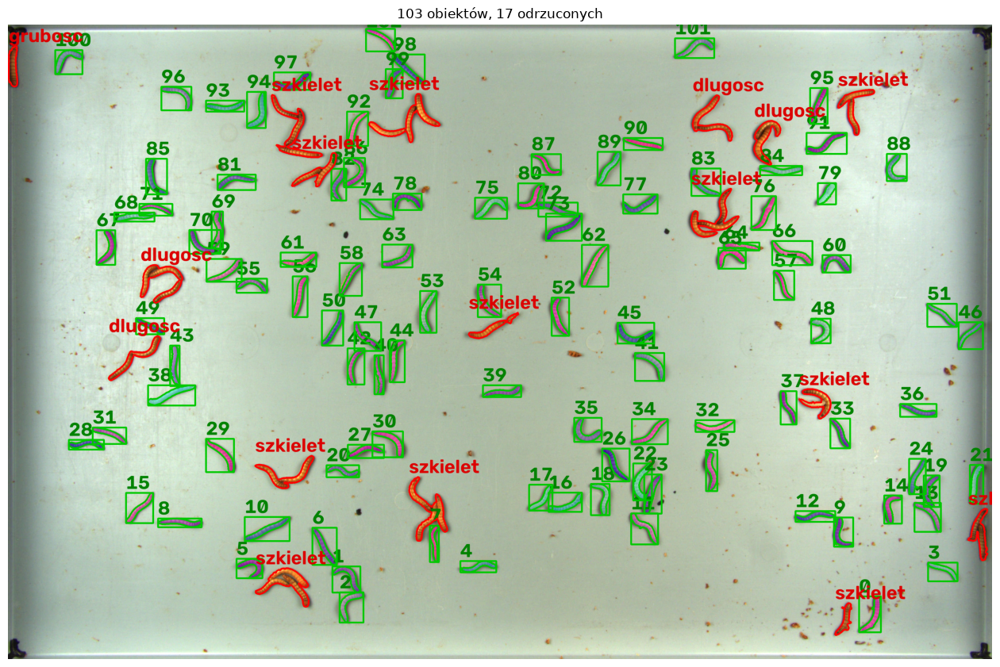

In [29]:
# Obraz testowy (kroki 1-6, detekcja policzona w sekcji kroku 5): te same parametry, także S_THR z calib; progi względne liczone na nowo z tego obrazu
print(f"test: {len(objs_test)} larw (po kroku 5: {sum(c['reason'] is None for c in dbg_test['candidates'])}), odrzucono: {dict(Counter(c['reason'] for c in dbg_test['rejected']))}, "
      f"drobnych: {dbg_test['n_small']}")
print(f"mediana pola: calib {dbg_calib['ref_area']:.0f} / test {dbg_test['ref_area']:.0f},  "
      f"mediana długości: calib {dbg_calib['ref_len']:.0f} / test {dbg_test['ref_len']:.0f}")
display_objects(test, objs_test, mode='both', rejected=dbg_test['rejected'])

test: 5 obiektów spoza kandydatów


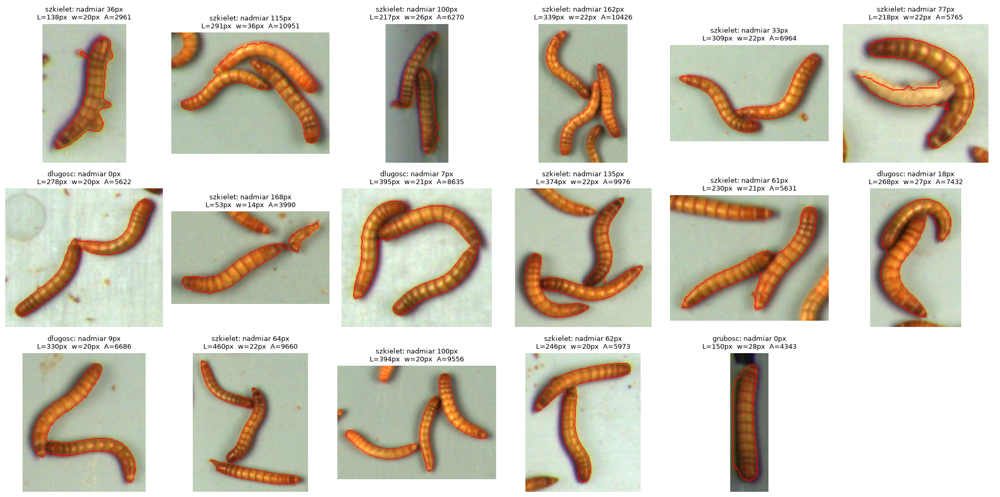

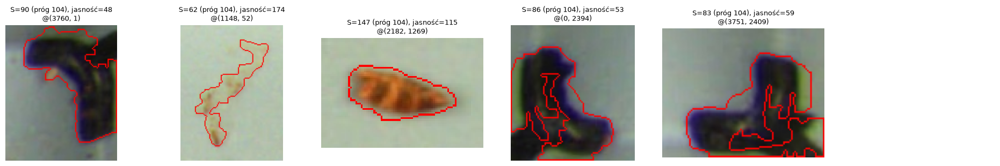

In [30]:
show_gallery(test, dbg_test['rejected'], rejection_title)
missed_test = find_missed(test, dbg_test)
print(f'test: {len(missed_test)} obiektów spoza kandydatów')
show_gallery(test, missed_test, lambda c: f"S={c['mean_S']:.0f} (próg {S_THR:.0f}), jasność={c['mean_gray']:.0f}\n@({c['bbox'][0]}, {c['bbox'][1]})")

#### Wyniki detekcji i dlaczego część larw się zgubiła

| | RoI | calib | test |
|---|---|---|---|
| larwy przyjęte w kroku 5 | 8 | 86 | 90 |
| krok 6: zlepki zamienione na larwy | – | 3 z 17 (+6) | 7 z 24 (+13) |
| krok 6: larwy, którym usunięto wypustkę | – | 4 z 10 | 3 z 8 |
| **larwy w wyniku (kroki 1–6)** | **8** | **92** | **103** |
| odrzucone `szkielet` (skrzyżowane, zlepione) | – | 10 | 12 |
| odrzucone `dlugosc` (stykające się końcami) | – | 2 | 4 |
| odrzucone `grubosc` (sklejone bokiem, larwa na ściance) | – | 2 | 1 |
| odrzucone `krawedz` (przecięte brzegiem RoI lub `FLOOR`) | 3 | – | – |
| drobne obiekty < 1500 px (okruchy, odchody) | – | 289 | 294 |

Mediany pola i długości są prawie takie same na obu obrazach (3240/3136 px, 156/153 px), więc parametry dobrane na `calib` przenoszą się na `test` bez zmian.

**Odrzuceni kandydaci** (galerie wyżej, już po kroku 6): prawie wszyscy to skrzyżowane, stykające się albo zlepione larwy, których krok 6 nie rozdzielił poprawnie. Wyjątki:
* na `test` larwa @(3226, 2256) z kilkoma przyklejonymi okruchami (nadmiar szkieletu 36 px). Krok 6 jej nie oczyszcza, więc zostaje odrzucona. To ostrożne, ale uzasadnione: do budowy bazy instancji lepiej zgubić larwę niż zapisać złą maskę. Podobną larwę z jednym okruchem, @(3319, 2230), krok 6 oczyszcza i przyjmuje;
* na `test` larwa wspinająca się po lewej ściance, odrzucona przez `grubosc`: jej maska obejmuje rozmyty cień na ściance, więc i tak byłaby za szeroka. Krok 6 przy progu 180 zdejmuje cień, ale zostaje 92% maski, mniej niż `min_cover`. Dzięki marginesowi 20 px wokół dna żaden obiekt na `calib` ani `test` nie dotyka brzegu obrazu, więc `krawedz` działa tylko na RoI.

**Obiekty, które w ogóle nie zostały kandydatami** (galerie „czego nie wykrywamy”):
* **narożniki dna pudełka:** czarne elementy w rogach prostokąta `FLOOR` (taśmy i pasków na krawędziach obrazu po przycięciu już nie ma). Pominięte słusznie: są ciemne, a ich fragmenty o S > 104 są mniejsze niż `min_area`;
* **ciemna larwa** (`calib`, ok. (3308, 1716) w układzie przyciętego obrazu): średnie S ≈ 98, czyli tuż pod progiem 104. To prawdziwa strata, bo ciemne, przepoczwarczające się osobniki mają mniej nasycony kolor;
* **krótkie pomarańczowe fragmenty:** S > 104, ale pole poniżej `min_area` = 1500 px. To fragmenty wylinek, główki albo zwinięte małe larwy. Obniżenie `min_area` wpuściłoby też grudki odchodów;
* **jasny, postrzępiony obiekt** o niskim S (≈ 62) przy górnej krawędzi dna, na obu zdjęciach w tym samym miejscu, prawdopodobnie fragment wylinki: słusznie pominięty.

**Inne ograniczenia:**
* jasne larwy (świeżo po wylince) mają niskie S i mogą zostać zgubione albo segmentowane tylko częściowo. Przyjęta blada larwa `calib` @(3546, 1129) ma maskę z wcięciami w jasnych miejscach ciała i przechodzi filtr tylko przy części progów globalnych (sekcja o wrażliwości);
* larwy przyjęte z wypustką, której krok 6 nie usuwa (6 na `calib`, 5 na `test`), mają ją w masce. Na przykład maska @(901, 954) zawiera kawałek ogona sąsiedniej larwy (nadmiar 13 px), a w @(1863, 647) najdłuższa ścieżka biegnie przez ciemny wyrostek zamiast do końca larwy;
* erozja na kanale B zmienia mierzoną grubość (eksperyment w części analizy). Jej siłę reguluje `refine_alpha`.

### Wrażliwość wyniku na próg globalny

Krok 1 pokazał, co próg globalny robi z maską wstępną. Tu sprawdzam, co z tego zostaje po całym potoku. Uruchamiam `detect_objects` (kroki 1–6) dla progów 60–160 przy pozostałych parametrach końcowych i porównuję wynik z wynikiem dla `S_THR`. Larwę uznaję za tę samą, gdy IoU masek ≥ 0.5. „Nowe” to larwy bez pary w wyniku dla `S_THR`, a „zgubione” to larwy z wyniku dla `S_THR` bez pary przy danym progu.

calib
 próg | przyjęte | nowe | zgubione | IoU wspólnych | szkielet | dlugosc | grubosc | krawedz | maly | drobne


   60 |       91 |    0 |        1 |         0.998 |       10 |       2 |       3 |       0 |    2 |    475


   70 |       91 |    0 |        1 |         0.999 |       10 |       2 |       3 |       0 |    1 |    378


   80 |       91 |    0 |        1 |         0.999 |       10 |       2 |       3 |       0 |    1 |    343


   90 |       92 |    0 |        0 |         1.000 |       10 |       2 |       2 |       0 |    0 |    319


  100 |       91 |    0 |        1 |         1.000 |       10 |       2 |       3 |       0 |    0 |    294


... (15 outputs left out)

  130 |      104 |    2 |        1 |         0.995 |       10 |       4 |       1 |       0 |    0 |    229


  140 |      103 |    3 |        3 |         0.998 |       10 |       4 |       1 |       0 |    0 |    222


  150 |      103 |    4 |        4 |         0.998 |       11 |       4 |       0 |       0 |    0 |    191


  160 |      102 |    5 |        6 |         0.996 |       10 |       4 |       0 |       0 |    0 |    173


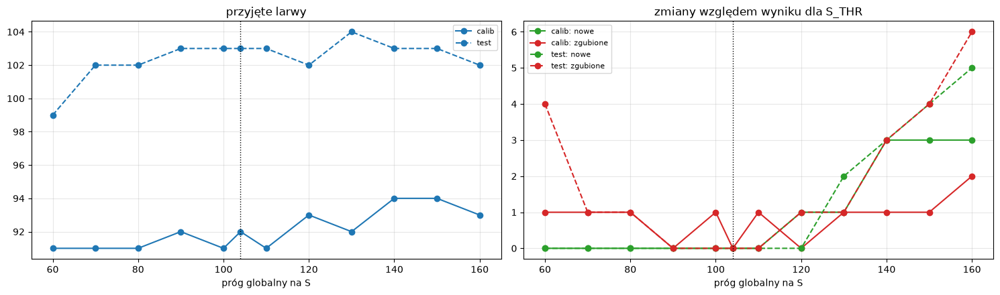

In [31]:
def mask_iou_pairs(objs: List, base: List, shape) -> tuple:
    """IoU każdej larwy z objs z najbardziej pokrywającą się larwą z base.
    Zwraca (tablica IoU dla objs, indeksy larw z base, które nie mają pary z IoU >= 0.5)."""
    lab = np.zeros(shape, np.int32)
    for i, b in enumerate(base, 1):
        x, y, w, h = b['bbox']
        lab[y:y + h, x:x + w][b['mask'] > 0] = i
    ious, paired = [], set()
    for o in objs:
        x, y, w, h = o['bbox']
        under = lab[y:y + h, x:x + w][o['mask'] > 0]
        ids, cnt = np.unique(under[under > 0], return_counts=True)
        iou = 0.0
        if len(ids):
            k = cnt.argmax()
            iou = cnt[k] / (o['area'] + base[ids[k] - 1]['area'] - cnt[k])
            if iou >= 0.5:
                paired.add(ids[k] - 1)
        ious.append(iou)
    return np.array(ious), [i for i in range(len(base)) if i not in paired]


thr_study = {}
for name, img, base in (('calib', calib, objs_calib), ('test', test, objs_test)):
    print(f'{name}\n próg | przyjęte | nowe | zgubione | IoU wspólnych | szkielet | dlugosc | grubosc | krawedz | maly | drobne')
    for t in thr_grid:
        objs, info = detect_objects(img, t, debug=True)
        ious, lost = mask_iou_pairs(objs, base, img.shape[:2])
        same = ious >= 0.5
        r = Counter(c['reason'] for c in info['rejected'])
        thr_study[name, t] = dict(objs=objs, info=info, ious=ious, lost=lost)
        print(f"{t:5.0f} | {len(objs):8d} | {(~same).sum():4d} | {len(lost):8d} | {ious[same].mean():13.3f} | "
              f"{r['szkielet']:8d} | {r['dlugosc']:7d} | {r['grubosc']:7d} | {r['krawedz']:7d} | {r['maly']:4d} | {info['n_small']:6d}")

f, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for name, ls in (('calib', '-'), ('test', '--')):
    st = [thr_study[name, t] for t in thr_grid]
    axes[0].plot(thr_grid, [len(s['objs']) for s in st], 'o' + ls, color='tab:blue', label=name)
    axes[1].plot(thr_grid, [int((s['ious'] < 0.5).sum()) for s in st], 'o' + ls, color='tab:green', label=f'{name}: nowe')
    axes[1].plot(thr_grid, [len(s['lost']) for s in st], 'o' + ls, color='tab:red', label=f'{name}: zgubione')
for ax, title in zip(axes, ('przyjęte larwy', 'zmiany względem wyniku dla S_THR')):
    ax.axvline(S_THR, color='k', ls=':', lw=1)
    ax.set(title=title, xlabel='próg globalny na S')
    ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()

**Wniosek:**
* **Między 90 a 110 wynik jest prawie identyczny:** na `test` te same larwy (IoU masek ≈ 1.000), a na `calib` zmienia się tylko blada larwa @(3546, 1129). Przy 90 i 104 przechodzi filtr, przy 100 odpada przez `grubosc`, a przy 110 przez `szkielet`, bo jej maska leży na granicy obu reguł (kroki 3–4). Poza nią `S_THR` = 104 leży w płaskiej dolinie histogramu S, więc przesunięcie progu o kilka jednostek nic nie zmienia. Ostateczny kształt maski ustala lokalny Otsu w kroku 3.
* **Niżej (≤ 80)** na `test` ginie 1–4 larw: poświata skleja je z sąsiadami w jedną składową, z której zostaje tylko największa część. Na `calib` ginie tylko blada larwa. Ciemna larwa z `calib` (S ≈ 98) nie wraca: od progu 80 staje się kandydatem, ale po lokalnym Otsu ma tylko ok. 1280 px, mniej niż `min_area` (kolumna `maly`).
* **Wyżej (≥ 120) zysk jest mały**, bo większość zlepków, które rozdziela wyższy próg globalny, rozdziela już krok 6 przy `S_THR`. Przed dodaniem kroku 6 próg 130 dawał na `test` 7 nowych larw, teraz 2. Na `calib` przybywa 1–3 larw, na `test` 0–5, a jednocześnie ginie 0–2 (`calib`) i 1–6 (`test`), bo blade larwy rozpadają się w masce wstępnej na kawałki (krok 1). Bilans to od 0 do +2 larw na `calib` i od −1 do +1 na `test`.
* **Decyzja:** zostaję przy `S_THR`. Wyższy próg opłaca się tylko lokalnie, w obrębie jednej maski, a to robi krok 6.

### Analiza instancji: długość, grubość, kształt

`analyze_objects` przyjmuje listę instancji z `detect_objects` i dla każdej maski liczy:

**Długość** (miara główna, zwalidowana poniżej):
1. szkielet (`skeletonize`) wygładzonej maski i jego **najdłuższa ścieżka**, czyli oś larwy bez bocznych gałązek;
2. **wygładzenie osi** filtrem Gaussa. Szkielet to schodki w 8-sąsiedztwie, a ich długość jest większa niż długość gładkiej krzywej;
3. **przedłużenie obu końców** wzdłuż stycznej aż do brzegu maski. Szkielet kończy się mniej więcej jeden promień przed czubkiem larwy, więc bez tej korekty długość jest zaniżona. Brzeg wyznaczam podpikselowo (maska interpolowana dwuliniowo, brzeg na poziomie 0.5).

**Grubość:** cięciwy prostopadłe do osi, mierzone tą samą podpikselową metodą. Wynik to mediana ze środkowych 60% długości, bo końce larwy są zwężone. Zapisuję też maksimum i cały profil grubości.

**Kształt I / C / S:** przebieg kąta stycznej wzdłuż osi, z pominięciem końcówek (po 10%, bo główka i ogon bywają lokalnie zagięte). Oś dzielę na zakręty, czyli odcinki o stałym znaku krzywizny, i liczę kąt skrętu każdego z nich:
* brak zakrętu ≥ 35° → **I**;
* co najmniej dwa znaczące zakręty w przeciwne strony → **S**;
* w przeciwnym razie → **C**.

Wszystkie wartości są w pikselach. Nie znamy skali obrazu (brak wzorca na zdjęciu), więc przeliczenie na mm wymagałoby kalibracji.

In [32]:
PAD = 2  # margines wokół maski, żeby brzeg obiektu nie leżał na brzegu tablicy


def polyline_length(p: np.ndarray) -> float:
    return float(np.linalg.norm(np.diff(p, axis=0), axis=1).sum()) if len(p) > 1 else 0.0


def resample_polyline(p: np.ndarray, step: float = 1.0) -> np.ndarray:
    """Równomierne próbkowanie łamanej co `step` px."""
    d = np.r_[0, np.cumsum(np.linalg.norm(np.diff(p, axis=0), axis=1))]
    s = np.arange(0, d[-1], step)
    if d[-1] - s[-1] > 1e-6:
        s = np.r_[s, d[-1]]
    return np.c_[np.interp(s, d, p[:, 0]), np.interp(s, d, p[:, 1])]


def rays_to_edge(maskf: np.ndarray, points: np.ndarray, dirs: np.ndarray, step: float = 0.25, max_t: float = 60.0):
    """Dla każdego punktu: odległość wzdłuż zadanego kierunku do brzegu maski.
    Maska jest interpolowana dwuliniowo, a brzeg to poziom 0.5 (w połowie między pikselem obiektu i tła),
    więc wynik jest podpikselowy. Liczone wektorowo dla wszystkich punktów naraz."""
    dirs = dirs / (np.linalg.norm(dirs, axis=1, keepdims=True) + 1e-9)
    t = np.arange(step, max_t + step, step)
    q = points[:, None, :] + t[None, :, None] * dirs[:, None, :]
    vals = map_coordinates(maskf, q.reshape(-1, 2).T, order=1, mode='constant').reshape(len(points), len(t))
    outside = vals < 0.5
    first_out = np.where(outside.any(axis=1), outside.argmax(axis=1), len(t))
    return first_out * step


def classify_shape(centerline: np.ndarray, sigma: float = 6.0, trim: float = 0.1, lobe_deg: float = 35.0):
    """Klasyfikacja I / C / S na podstawie przebiegu kąta stycznej wzdłuż linii środkowej.
    Końcówki (`trim` długości z każdej strony) są pomijane, bo główka i ogon bywają lokalnie zagięte.
    Linię dzielę na zakręty (odcinki o stałym znaku krzywizny) i sumuję kąt skrętu w każdym:
      brak zakrętu >= lobe_deg -> I;  >= 2 znaczące zakręty o przeciwnych znakach -> S;  inaczej -> C."""
    p = np.c_[gaussian_filter1d(centerline[:, 0], sigma, mode='nearest'),
              gaussian_filter1d(centerline[:, 1], sigma, mode='nearest')]
    cut = int(trim * len(p))
    p = p[cut:len(p) - cut]
    if len(p) < 3:
        return 'I', dict(lobes=[], significant=[], theta=np.zeros(0))
    d = np.diff(p, axis=0)
    theta = np.unwrap(np.arctan2(d[:, 0], d[:, 1]))
    lobes, cur = [], 0.0
    for v in np.diff(theta):
        if cur == 0 or np.sign(v) == np.sign(cur):
            cur += v
        else:
            lobes.append(cur)
            cur = v
    lobes.append(cur)
    lobes = [float(np.degrees(l)) for l in lobes]
    significant = [l for l in lobes if abs(l) >= lobe_deg]
    if not significant:
        cls = 'I'
    elif any(np.sign(a) != np.sign(b) for a, b in zip(significant, significant[1:])):
        cls = 'S'
    else:
        cls = 'C'
    return cls, dict(lobes=lobes, significant=significant, theta=np.degrees(theta))


def analyze_instance(obj: dict, sigma: float = 3.0, k_dir: int = 8, mid=(0.2, 0.8), open_k: int = 7,
                     **shape_kw) -> dict:
    """Pomiar pojedynczej instancji na podstawie jej maski binarnej (obj['mask']).
      1. szkielet wygładzonej maski -> najdłuższa ścieżka (oś larwy, bez bocznych gałązek),
      2. wygładzenie osi filtrem Gaussa (usuwa schodki 8-sąsiedztwa, które zawyżają długość),
      3. przedłużenie obu końców wzdłuż stycznej aż do brzegu maski (szkielet kończy się ok. promień przed
         czubkiem larwy, co zaniża długość),
      4. grubość: cięciwy prostopadłe do osi; mediana ze środkowej części (`mid`), bo końce są zwężone,
      5. kształt I/C/S z przebiegu kąta stycznej (classify_shape)."""
    m = np.pad(obj['mask'], PAD).astype(np.uint8)
    maskf = m.astype(np.float32)
    smooth_mask = cv2.morphologyEx(m, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (open_k, open_k)))
    skel = skm.skeletonize(smooth_mask > 0)
    geo_len, path = skeleton_longest_path(skel)
    res = dict(length_naive=float(skel.sum()), length_geodesic=float(geo_len))
    if len(path) < 2 * k_dir + 2:
        res.update(length=np.nan, length_smooth=np.nan, width=np.nan, width_dt=np.nan, width_max=np.nan,
                   shape=None, straightness=np.nan)
        return res

    # 2. wygładzona oś, próbkowana co 1 px
    path = path.astype(np.float64)
    smooth = np.c_[gaussian_filter1d(path[:, 0], sigma, mode='nearest'),
                   gaussian_filter1d(path[:, 1], sigma, mode='nearest')]
    smooth = resample_polyline(smooth, 1.0)

    # 3. przedłużenie końców wzdłuż stycznej do brzegu maski
    k = min(k_dir, len(smooth) - 1)
    ends = np.array([smooth[0], smooth[-1]])
    dirs = np.array([smooth[0] - smooth[k], smooth[-1] - smooth[-1 - k]])
    dirs /= np.linalg.norm(dirs, axis=1, keepdims=True)
    ext = rays_to_edge(maskf, ends, dirs)
    tips = ends + ext[:, None] * dirs
    length_smooth = polyline_length(smooth)
    length = length_smooth + float(ext.sum())

    # 4. grubość: cięciwy prostopadłe do osi
    tang = np.gradient(smooth, axis=0)
    tang /= np.linalg.norm(tang, axis=1, keepdims=True) + 1e-9
    normals = np.c_[-tang[:, 1], tang[:, 0]]
    w_plus, w_minus = rays_to_edge(maskf, smooth, normals), rays_to_edge(maskf, smooth, -normals)
    widths = w_plus + w_minus
    pos = (ext[0] + np.r_[0, np.cumsum(np.linalg.norm(np.diff(smooth, axis=0), axis=1))]) / length
    sel = (pos >= mid[0]) & (pos <= mid[1])
    if not sel.any():
        sel[:] = True
    # dla porównania: klasyczna grubość 2 x transformata odległości na osi
    dt = cv2.distanceTransform(m, cv2.DIST_L2, cv2.DIST_MASK_PRECISE)
    widths_dt = 2 * map_coordinates(dt, smooth.T, order=1)

    # 5. kształt
    shape, shape_info = classify_shape(smooth, **shape_kw)

    off = np.array([PAD, PAD])
    res.update(
        length=length,
        length_smooth=length_smooth,
        width=float(np.median(widths[sel])),
        width_max=float(widths.max()),
        width_dt=float(np.median(widths_dt[sel])),
        shape=shape,
        straightness=float(np.linalg.norm(tips[1] - tips[0]) / length),
        lobes=shape_info['significant'],
        centerline=np.vstack([tips[0], smooth, tips[1]]) - off,
        _debug=dict(skeleton=skel[PAD:-PAD, PAD:-PAD], path=path - off, smooth=smooth - off, tips=tips - off,
                    ext=ext, normals=normals, w_plus=w_plus, w_minus=w_minus, widths=widths, pos=pos,
                    mid=mid, shape_info=shape_info),
    )
    return res


def analyze_objects(instances: List, **kwargs) -> List:
    """Analiza wszystkich instancji z detect_objects. Zwraca kopie słowników uzupełnione o:
    length [px], width [px] (mediana grubości w środkowej części), width_max, shape ('I'/'C'/'S'),
    straightness (cięciwa / długość), lobes (znaczące zakręty w stopniach), centerline (oś z końcami)."""
    return [{**obj, **analyze_instance(obj, **kwargs)} for obj in instances]

In [33]:
def show_analysis(a: dict, image: np.ndarray = None):
    """Podgląd analizy krok po kroku dla jednej instancji (wynik analyze_objects / analyze_instance)."""
    d, mask = a['_debug'], a['mask']
    n = 6 if image is not None else 5
    f, axes = plt.subplots(1, n, figsize=(4.2 * n, 4.5))
    if image is not None:
        x, y, w, h = a['bbox']
        axes[0].imshow(image[y:y + h, x:x + w, ::-1])
        axes[0].set_title('RGB')
        axes[0].axis('off')
    a1, a2, a3, a4, a5 = axes[-5:]

    a1.imshow(mask, cmap='gray')
    sy, sx = np.nonzero(d['skeleton'])
    a1.plot(sx, sy, 'c.', ms=2, label='szkielet')
    a1.plot(d['path'][:, 1], d['path'][:, 0], 'r-', lw=1, label='najdłuższa ścieżka')
    a1.legend(fontsize=7, loc='lower right')
    a1.set_title(f"1. szkielet {a['length_naive']:.0f} px, ścieżka {a['length_geodesic']:.0f} px", fontsize=9)

    a2.imshow(mask, cmap='gray')
    a2.plot(d['smooth'][:, 1], d['smooth'][:, 0], 'r-', lw=1.5)
    for tip, end in zip(d['tips'], d['smooth'][[0, -1]]):
        a2.plot([end[1], tip[1]], [end[0], tip[0]], 'y-', lw=2.5)
    a2.plot(d['tips'][:, 1], d['tips'][:, 0], 'yo', ms=4)
    a2.set_title(f"2. wygładzona + końce (żółte): L = {a['length']:.1f} px", fontsize=9)

    a3.imshow(mask, cmap='gray')
    for i in range(0, len(d['smooth']), 6):
        p, nrm = d['smooth'][i], d['normals'][i]
        p1, p2 = p + d['w_plus'][i] * nrm, p - d['w_minus'][i] * nrm
        in_mid = d['mid'][0] <= d['pos'][i] <= d['mid'][1]
        a3.plot([p1[1], p2[1]], [p1[0], p2[0]], '-', color='lime' if in_mid else 'orange', lw=1)
    a3.set_title(f"3. cięciwy: grubość = {a['width']:.1f} px (max {a['width_max']:.1f})", fontsize=9)
    for ax in (a1, a2, a3):
        ax.axis('off')

    a4.plot(d['pos'], d['widths'], 'k-')
    a4.axvspan(*d['mid'], color='lime', alpha=0.2, label='zakres mediany')
    a4.axhline(a['width'], color='g', ls='--', label=f"mediana {a['width']:.1f} px")
    a4.set_xlabel('pozycja wzdłuż larwy (0 → 1)')
    a4.set_ylabel('grubość [px]')
    a4.set_title('4. profil grubości', fontsize=9)
    a4.legend(fontsize=7)

    si = d['shape_info']
    if len(si['theta']):
        a5.plot(si['theta'] - si['theta'][0], 'b-')
    a5.axhline(0, color='gray', lw=0.5)
    a5.set_xlabel('px wzdłuż linii (bez końcówek)')
    a5.set_ylabel('kąt stycznej względem początku [°]')
    a5.set_title(f"5. kształt {a['shape']}: zakręty {[round(l) for l in si['significant']]}°", fontsize=9)
    plt.tight_layout()

kształty  calib: {'S': 12, 'C': 66, 'I': 14}   test: {'C': 69, 'S': 9, 'I': 25}


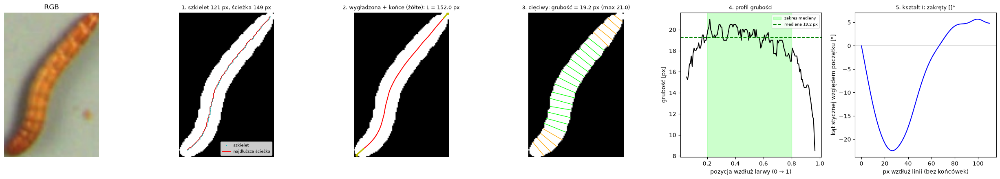

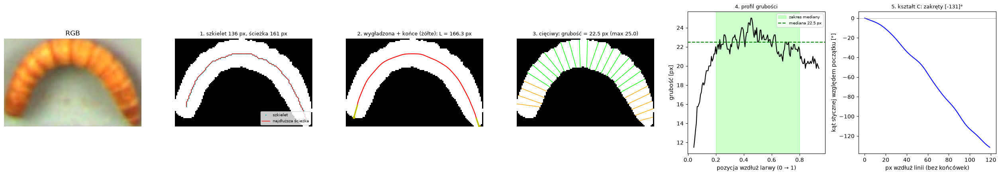

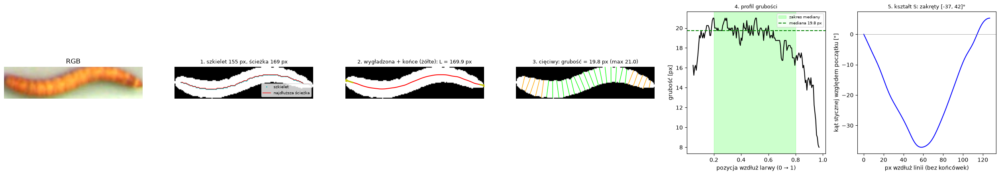

In [34]:
an_calib = analyze_objects(objs_calib)
an_test = analyze_objects(objs_test)
print('kształty  calib:', dict(Counter(a['shape'] for a in an_calib)), '  test:', dict(Counter(a['shape'] for a in an_test)))

# Analiza krok po kroku: po jednym przykładzie każdej klasy kształtu
for cls in 'ICS':
    show_analysis(next(a for a in an_calib if a['shape'] == cls), calib)

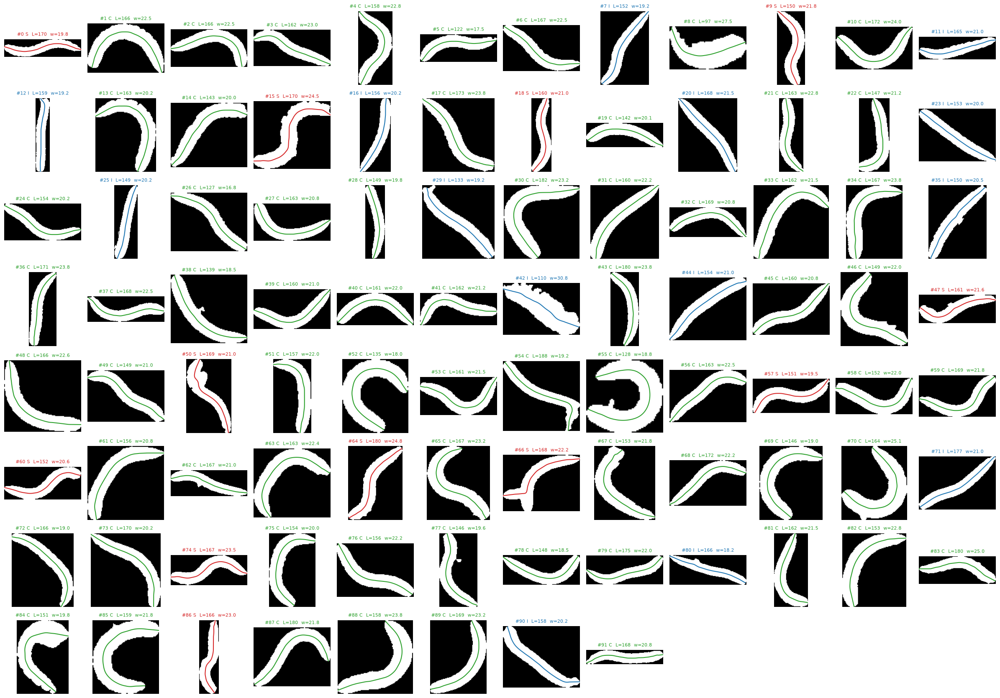

In [35]:
# Galeria wszystkich larw z calib: linia środkowa w kolorze klasy kształtu, w tytule długość i grubość.
# Pozwala szybko ocenić klasyfikację i wychwycić dziwne maski.
colors = {'I': 'tab:blue', 'C': 'tab:green', 'S': 'tab:red'}
cols = 12
rows = int(np.ceil(len(an_calib) / cols))
f, axes = plt.subplots(rows, cols, figsize=(2 * cols, 2.1 * rows))
for ax in axes.ravel():
    ax.axis('off')
for i, (ax, a) in enumerate(zip(axes.ravel(), an_calib)):
    ax.imshow(a['mask'], cmap='gray')
    ax.plot(a['centerline'][:, 1], a['centerline'][:, 0], '-', color=colors[a['shape']], lw=1.5)
    ax.set_title(f"#{i} {a['shape']}  L={a['length']:.0f}  w={a['width']:.1f}", fontsize=8, color=colors[a['shape']])
plt.tight_layout()

#### Eksperyment: siła erozji brzegu a pomiar

Erozja na kanale B (krok 4 detekcji) zdejmuje piksele mieszane z tłem; w kroku 4 widać, które. Nie wiadomo jednak, gdzie dokładnie leży „prawdziwy” brzeg larwy, a od tego zależy zmierzona grubość. Sprawdzam, jak `refine_alpha` wpływa na liczbę wykrytych larw oraz mediany pola, grubości i długości. Mniejsza `alpha` oznacza mocniejszą erozję.

bez erozji             n= 90   mediana: pole   3374 px, grubość 22.50 px, długość  162.6 px


alpha=0.35             n= 90   mediana: pole   3342 px, grubość 22.06 px, długość  161.9 px


alpha=0.25 (domyślnie) n= 92   mediana: pole   3209 px, grubość 21.50 px, długość  161.4 px


alpha=0.15             n= 91   mediana: pole   2962 px, grubość 19.75 px, długość  159.7 px


(np.float64(-0.5), np.float64(161.5), np.float64(91.5), np.float64(-0.5))

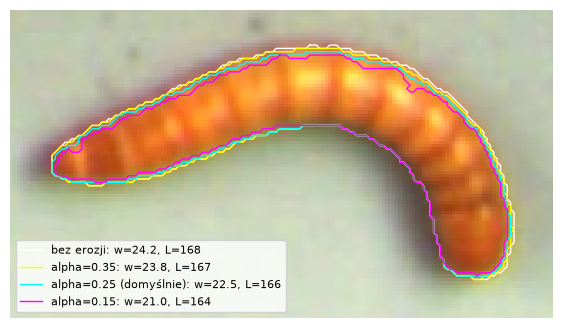

In [36]:
variants = [('bez erozji', dict(refine_iters=0)), ('alpha=0.35', dict(refine_alpha=0.35)),
            ('alpha=0.25 (domyślnie)', dict(refine_alpha=0.25)), ('alpha=0.15', dict(refine_alpha=0.15))]
variant_results = {}
for name, kw in variants:
    an = analyze_objects(detect_objects(calib, S_THR, **kw))
    variant_results[name] = an
    print(f"{name:22s} n={len(an):3d}   mediana: pole {np.median([a['area'] for a in an]):6.0f} px, "
          f"grubość {np.median([a['width'] for a in an]):5.2f} px, długość {np.median([a['length'] for a in an]):6.1f} px")

# ta sama larwa we wszystkich wariantach
ref = an_calib[2]
x, y, w, h = ref['bbox']
cx, cy, pad = x + w / 2, y + h / 2, 12
x0, y0 = max(x - pad, 0), max(y - pad, 0)
f, ax = plt.subplots(figsize=(7, 7))
ax.imshow(calib[y0:y + h + pad, x0:x + w + pad, ::-1])
for (name, an), col in zip(variant_results.items(), ['white', 'yellow', 'cyan', 'magenta']):
    a = min(an, key=lambda a: (a['bbox'][0] + a['bbox'][2] / 2 - cx) ** 2 + (a['bbox'][1] + a['bbox'][3] / 2 - cy) ** 2)
    cnt = a['contour'][:, 0, :] - [x0, y0]
    ax.plot(np.r_[cnt[:, 0], cnt[0, 0]], np.r_[cnt[:, 1], cnt[0, 1]], '-', color=col, lw=1,
            label=f"{name}: w={a['width']:.1f}, L={a['length']:.0f}")
ax.legend(fontsize=8)
ax.axis('off')

**Wniosek:**
* Siła erozji zmienia medianę grubości o ok. 2.75 px: 22.5 px bez erozji, 19.75 px przy `alpha=0.15`. Długość zmienia się dużo mniej, o ok. 2.9 px, czyli ok. 2% wobec ok. 12% dla grubości.
* Bez wzorca nie da się rozstrzygnąć, który brzeg jest „prawdziwy”. Wybrałem `alpha=0.25`, która zdejmuje tylko wyraźnie jasne piksele mieszane z tłem i nie wcina się w ciało larwy, w przeciwieństwie do `alpha=0.15`, która po stronie oświetlonej zdejmuje też brzeg ciała (kroki 3–4).
* Liczba wykrytych larw prawie się nie zmienia (90–92), więc erozja wpływa na pomiar, a nie na detekcję.
* **Praktyczny wniosek:** grubość bezwzględna ma niepewność rzędu ±1–2 px wynikającą z definicji brzegu, ale porównania względne (między larwami lub partiami, przy tych samych parametrach) pozostają ważne.

#### Walidacja pomiaru na syntetycznych larwach

Do prawdziwych larw nie ma pomiaru referencyjnego, więc dokładność sprawdzam na **syntetycznych maskach o znanej długości i grubości**. Generuję 60 larw: po 20 kształtów I, C i S, z losową długością 120–200 px, grubością 17–24 px, obrotem i zwężonymi końcami (jak u prawdziwych larw). Porównuję kolejne warianty metody, żeby pokazać, co daje każdy krok.

DŁUGOŚĆ                         błąd śr.  odch. std  |błąd| wzgl.
liczba pikseli szkieletu         -24.12px     8.60px       14.80 %
najdłuższa ścieżka szkieletu      -3.55px     3.75px        2.77 %
wygładzona linia środkowa        -15.12px     2.68px        9.39 %
wygładzona + przedłużone końce    -1.04px     1.09px        0.77 %

GRUBOŚĆ                       
2 x transformata odległości       -0.31px     0.29px        1.68 %
cięciwy prostopadłe               -0.09px     0.16px        0.67 %

KSZTAŁT (prawdziwy -> przewidziany): {('I', 'I'): 20, ('C', 'C'): 20, ('S', 'S'): 20}


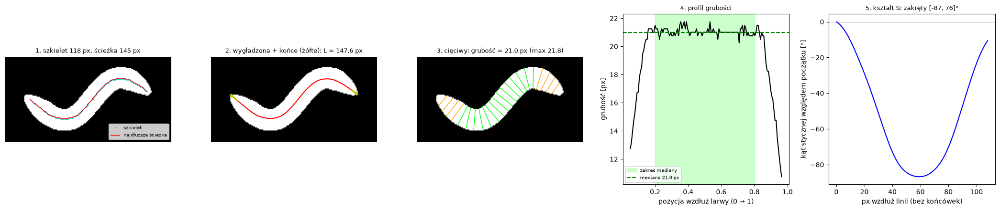

In [37]:
def make_synthetic_larva(kind: str, length: float, width: float, angle: float, taper: float = 0.15, r_min: float = 1.0):
    """Syntetyczna maska larwy o znanej linii środkowej: I (prosta), C (łuk 180°), S (sinusoida).
    Promień zwęża się na końcach (`taper` = część długości). Zwraca (maska, długość GT, grubość GT).
    GT liczę w zasięgu pikseli: cv2.circle zapala piksele o środku w odległości <= r, więc brzeg maski
    leży 0.5 px dalej, czyli figura jest o 1 px dłuższa i o 1 px grubsza niż wynika z parametrów (sprawdzone)."""
    s = np.linspace(0, length, int(length * 4))
    if kind == 'I':
        x, y = s, np.zeros_like(s)
    elif kind == 'C':
        R = length / np.pi
        x, y = R * np.sin(s / R), R * (1 - np.cos(s / R))
    else:  # S: sinusoida sparametryzowana długością łuku
        xx = np.linspace(0, length, 20000)
        yy = 0.12 * length * np.sin(2 * np.pi * xx / (0.75 * length))
        arc = np.r_[0, np.cumsum(np.hypot(np.diff(xx), np.diff(yy)))]
        x, y = np.interp(s, arc, xx), np.interp(s, arc, yy)
    c, sn = np.cos(angle), np.sin(angle)
    X, Y = c * x - sn * y, sn * x + c * y
    X, Y = X - X.min() + width, Y - Y.min() + width
    mask = np.zeros((int(Y.max() + width) + 2, int(X.max() + width) + 2), np.uint8)
    u = s / length
    r = np.maximum(width / 2 * np.clip(np.minimum(u, 1 - u) / taper, 0, 1) ** 0.5, r_min)
    for xi, yi, ri in zip(X, Y, r):
        cv2.circle(mask, (int(round(xi * 8)), int(round(yi * 8))), int(round(ri * 8)), 1, -1, shift=3)
    return mask, length + 2 * r_min + 1, width + 1


rng = np.random.default_rng(0)
synth = []
for kind in 'ICS':
    for _ in range(20):
        L, W = rng.uniform(120, 200), rng.uniform(17, 24)
        mask, gt_len, gt_w = make_synthetic_larva(kind, L, W, rng.uniform(0, np.pi))
        synth.append(dict(kind=kind, gt_len=gt_len, gt_w=gt_w, mask=mask, **analyze_instance({'mask': mask})))

gt_len = np.array([r['gt_len'] for r in synth])
gt_w = np.array([r['gt_w'] for r in synth])
print(f"{'DŁUGOŚĆ':30s} {'błąd śr.':>9s} {'odch. std':>10s} {'|błąd| wzgl.':>13s}")
for key, name in [('length_naive', 'liczba pikseli szkieletu'), ('length_geodesic', 'najdłuższa ścieżka szkieletu'),
                  ('length_smooth', 'wygładzona linia środkowa'), ('length', 'wygładzona + przedłużone końce')]:
    err = np.array([r[key] for r in synth]) - gt_len
    print(f'{name:30s} {err.mean():+8.2f}px {err.std():8.2f}px {100 * np.mean(np.abs(err) / gt_len):11.2f} %')
print(f"\n{'GRUBOŚĆ':30s}")
for key, name in [('width_dt', '2 x transformata odległości'), ('width', 'cięciwy prostopadłe')]:
    err = np.array([r[key] for r in synth]) - gt_w
    print(f'{name:30s} {err.mean():+8.2f}px {err.std():8.2f}px {100 * np.mean(np.abs(err) / gt_w):11.2f} %')
print('\nKSZTAŁT (prawdziwy -> przewidziany):', dict(Counter((r['kind'], r['shape']) for r in synth)))

# podgląd jednego syntetycznego przykładu S
show_analysis(next(r for r in synth if r['kind'] == 'S'))

I: n= 39, mediana długości  156.4 px, IQR 150-166
C: n=135, mediana długości  160.1 px, IQR 151-167
S: n= 21, mediana długości  165.6 px, IQR 152-170


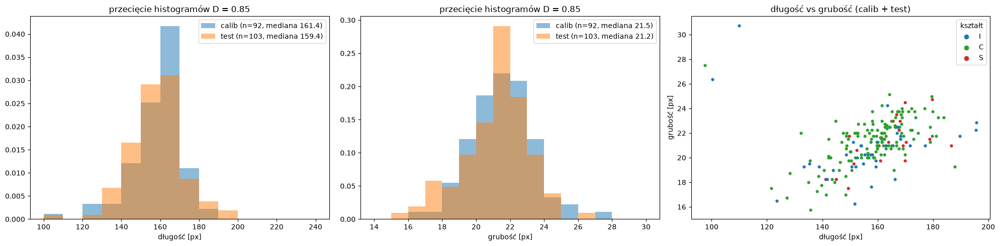

In [38]:
# Statystyki populacji: calib vs test.
# Zdjęcia zrobiono w odstępie ~1 min, więc to najpewniej te same larwy w innych pozach (jak seria zdjęć
# w artykule). Rozkłady powinny się więc pokrywać - to test powtarzalności pomiaru niezależnie od pozy.
# Miara zgodności: przecięcie histogramów D = sum(min(h1, h2)) - ta sama, której używa artykuł (wzór 2).
def hist_intersection(a, b, bins) -> float:
    ha, _ = np.histogram(a, bins)
    hb, _ = np.histogram(b, bins)
    return float(np.minimum(ha / ha.sum(), hb / hb.sum()).sum())

f, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, key, bins, label in [(axes[0], 'length', np.arange(100, 241, 10), 'długość [px]'),
                             (axes[1], 'width', np.arange(14, 30.5, 1), 'grubość [px]')]:
    vc, vt = [a[key] for a in an_calib], [a[key] for a in an_test]
    ax.hist(vc, bins, alpha=0.5, density=True, label=f'calib (n={len(vc)}, mediana {np.median(vc):.1f})')
    ax.hist(vt, bins, alpha=0.5, density=True, label=f'test (n={len(vt)}, mediana {np.median(vt):.1f})')
    ax.set_xlabel(label)
    ax.set_title(f'przecięcie histogramów D = {hist_intersection(vc, vt, bins):.2f}')
    ax.legend()
colors = {'I': 'tab:blue', 'C': 'tab:green', 'S': 'tab:red'}
for a in an_calib + an_test:
    axes[2].scatter(a['length'], a['width'], c=colors[a['shape']], s=12)
for cls, col in colors.items():
    axes[2].scatter([], [], c=col, label=cls)
axes[2].set_xlabel('długość [px]'); axes[2].set_ylabel('grubość [px]'); axes[2].legend(title='kształt')
axes[2].set_title('długość vs grubość (calib + test)')
plt.tight_layout()

# Czy długość zależy od pozy? Jeśli pomiar jest dobry, mediany w klasach I/C/S powinny być zbliżone.
for cls in 'ICS':
    v = [a['length'] for a in an_calib + an_test if a['shape'] == cls]
    print(f'{cls}: n={len(v):3d}, mediana długości {np.median(v):6.1f} px, IQR {np.percentile(v, 25):.0f}-{np.percentile(v, 75):.0f}')

#### Wnioski z analizy

**Długość (miara główna).** Walidacja na 60 syntetycznych larwach:

| metoda | błąd średni | odch. std | średni \|błąd\| względny |
|---|---|---|---|
| liczba pikseli szkieletu (naiwnie) | −24.1 px | 8.6 px | 14.8 % |
| najdłuższa ścieżka szkieletu | −3.6 px | 3.8 px | 2.8 % |
| wygładzona linia środkowa | −15.1 px | 2.7 px | 9.4 % |
| **wygładzona + przedłużone końce** | **−1.0 px** | **1.1 px** | **0.8 %** |

* Naiwne liczenie pikseli szkieletu zaniża długość o ok. 15%, bo krok ukośny liczy się jako 1 zamiast √2, a szkielet kończy się przed czubkami.
* Najdłuższa ścieżka daje mały błąd średni, ale tylko dzięki temu, że dwa błędy się znoszą: schodki zawyżają długość, a skrócone końce ją zaniżają. Rozrzut pozostaje duży (σ = 3.8 px).
* Samo wygładzenie usuwa schodki i odsłania prawdziwy niedomiar na końcach (≈ −15 px, czyli ok. jeden promień z każdej strony).
* Przedłużenie końców ten niedomiar usuwa. Zostaje ok. −1 px, bo przy zwężonym czubku promień trafia w brzeg odrobinę wcześniej.

Każdy krok ma więc uzasadnienie, a końcowa metoda jest prawie nieobciążona i ma rozrzut ok. 1 px.

**Grubość.** Cięciwy prostopadłe do osi: −0.09 ± 0.16 px. Klasyczne 2 × transformata odległości: −0.31 ± 0.29 px. Na prawdziwych danych grubość rośnie razem z długością (wykres rozrzutu), co ma sens biologicznie, bo większe larwy są grubsze.

**Kształt.** Na syntetykach 60/60 trafień. Na prawdziwych larwach przeważają C (≈ 2/3), potem I i S. Granica między łagodnym C a I oraz między C a S zależy od progu `lobe_deg`. Nie ma tu „prawdziwej” etykiety, więc warto ocenić galerię wzrokowo.

**Powtarzalność na prawdziwych danych.** Dwa zdjęcia zrobione w odstępie ok. 1 min dają zgodne rozkłady: przecięcie histogramów D ≈ 0.85 dla długości i ≈ 0.85 dla grubości, mediany długości 161.4 i 159.4 px. Przy stałej `delta` = 30 zgodność grubości wynosiła 0.79, a bez kroku 6 zgodność długości 0.81. Wzrost pasuje do tego, że erozja dopasowana do kontrastu w ROI nie zależy już od jasności tła w danym miejscu pudełka. Mediana długości jest podobna dla larw I, C i S (≈ 156–166 px). To sugeruje, że pomiar nie zależy mocno od pozy: wygięta larwa nie wychodzi krótsza.

**Ograniczenia:**
* Pomiar jest dokładny względem **maski**, więc błędy segmentacji (erozja brzegu na kanale B, przyklejone okruchy, których krok 6 nie usunął) przechodzą wprost na grubość i, w mniejszym stopniu, na długość.
* Mocno zwinięte larwy (prawie pierścień, końce blisko siebie) mają niepewne końce szkieletu.
* Blada larwa `calib` @(3546, 1129) to punkt odstający na wykresie rozrzutu (ok. 110 px długości i 31 px grubości): jej maska jest niepewna (kroki 3–4).
* Brak skali, więc wyniki są w pikselach.